In [ ]:
# ============================================
# CELL 1: IMPORT LIBRARIES
# ============================================

import os
import zipfile
import warnings

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive

warnings.filterwarnings("ignore")
print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
# ============================================
# CELL 2: MOUNT GOOGLE DRIVE
# ============================================

drive.mount('/content/drive')

# Check files in your Drive
!ls -lah /content/drive/MyDrive/

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
total 129M
drwx------ 10 root root 4.0K Oct 23 04:10  .
drwx------  5 root root 4.0K Oct 23 04:10  ..
drwx------  2 root root 4.0K Sep  4 03:35 'AI in Medicine Lab'
-rw-------  1 root root 380K Sep 24 05:15 'archive (1).zip'
-rw-------  1 root root    0 Aug 17 08:01  Artist.pdf.adding
-rw-------  1 root root    0 Aug 17 08:00  Artist.pptx.adding
-rw-------  1 root root  27M Aug 17 08:14 'Artist Take _20260817_131656_0000_compressed.pdf'
-rw-------  1 root root  88M Aug 17 08:14 'Artist Take _20260817_132208_0000.pptx'
-rw-------  1 root root 5.3M Sep  8  2025  Assignment1-E0524003.pdf
-rw-------  1 root root 148K Sep  8  2025  Assignment2-E0524003.pdf
-rw-------  1 root root 207K Jul 31 15:07 'Carotid Artery Stenosis.pdf'
drwx------  2 root root 4.0K Aug 19  2025 'Certificates '
drwx------  2 root root 4.0K Aug 14  2024  Classroom
drwx------  2 root root 4.0K

In [ ]:
# ============================================
# CELL 3: EXTRACT DATASET
# ============================================

zip_path = "/content/drive/MyDrive/archive (1).zip"
extract_path = "/content/blood_cell_dataset"

# Create extraction folder
os.makedirs(extract_path, exist_ok=True)

# Extract ZIP
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print("\nFiles inside dataset:\n")

for root, dirs, files in os.walk(extract_path):
    level = root.replace(extract_path, '').count(os.sep)
    indent = '  ' * level
    print(f"{indent}{os.path.basename(root)}/")

    for file in files[:20]:
        print(f"{indent}  └── {file}")

Dataset extracted successfully!

Files inside dataset:

blood_cell_dataset/
  └── blood_cell_anomaly_detection.csv
  └── cytodiffusion_benchmark_scores.csv
  └── cell_type_reference.csv


In [ ]:
# ============================================
# CELL 4: FIND AND INSPECT DATA FILES
# ============================================

import glob

# Find CSV and Excel files
csv_files = glob.glob(extract_path + "/**/*.csv", recursive=True)
excel_files = glob.glob(extract_path + "/**/*.xlsx", recursive=True)

print("CSV files found:")
for f in csv_files:
    print(" -", f)

print("\nExcel files found:")
for f in excel_files:
    print(" -", f)

# Load the first CSV automatically
if len(csv_files) > 0:
    data_path = csv_files[0]
    df = pd.read_csv(data_path)
elif len(excel_files) > 0:
    data_path = excel_files[0]
    df = pd.read_excel(data_path)
else:
    raise FileNotFoundError("No CSV or Excel dataset found!")

print("\n====================================")
print("Dataset loaded successfully!")
print("====================================")
print("File:", data_path)
print("Shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

CSV files found:
 - /content/blood_cell_dataset/blood_cell_anomaly_detection.csv
 - /content/blood_cell_dataset/cytodiffusion_benchmark_scores.csv
 - /content/blood_cell_dataset/cell_type_reference.csv

Excel files found:

Dataset loaded successfully!
File: /content/blood_cell_dataset/blood_cell_anomaly_detection.csv
Shape: (5880, 36)

First 5 rows:


,cell_id,cell_type,anomaly_label,disease_category,cell_diameter_um,nucleus_area_pct,chromatin_density,cytoplasm_ratio,circularity,eccentricity,...,mcv_fl,mchc_g_dl,dataset_source,staining_protocol,microscope_model,magnification_x,image_resolution_px,cytodiffusion_anomaly_score,cytodiffusion_classification_confidence,labeller_confidence_score
0,CELL_005371,Hypersegmented_Neutrophil,1,Infection,15.18,58.8,0.542,0.301,0.563,0.529,...,85.5,31.4,CytoData,Giemsa,Zeiss_Axio,100,224,0.7649,0.5726,0.5670
1,CELL_005300,Hypersegmented_Neutrophil,1,Infection,16.47,73.6,0.583,0.365,0.859,0.443,...,92.5,35.0,PBC_Dataset,Wright,Zeiss_Axio,100,224,0.8472,0.7150,0.7273
2,CELL_000200,Neutrophil,0,Normal_WBC,13.41,55.5,0.448,0.376,0.781,0.407,...,76.3,33.0,CytoData,Wright,Leica_DM2000,100,512,0.0313,0.9225,0.9623
3,CELL_003269,Normal_RBC,0,Normal_RBC,7.36,0.0,0.000,1.000,0.880,0.167,...,92.3,32.5,CytoData,Wright,Leica_DM2000,100,512,0.1293,0.9180,0.8652
4,CELL_003505,Normal_RBC,0,Normal_RBC,7.53,0.0,0.000,1.000,1.000,0.158,...,83.9,33.4,CytoData,Wright,Olympus_BX51,100,224,0.1418,0.9697,0.8898



Column names:
['cell_id', 'cell_type', 'anomaly_label', 'disease_category', 'cell_diameter_um', 'nucleus_area_pct', 'chromatin_density', 'cytoplasm_ratio', 'circularity', 'eccentricity', 'granularity_score', 'lobularity_score', 'membrane_smoothness', 'cell_area_px', 'perimeter_px', 'mean_r', 'mean_g', 'mean_b', 'stain_intensity', 'patient_age_group', 'patient_sex', 'wbc_count_per_ul', 'rbc_count_millions_per_ul', 'hemoglobin_g_dl', 'hematocrit_pct', 'platelet_count_per_ul', 'mcv_fl', 'mchc_g_dl', 'dataset_source', 'staining_protocol', 'microscope_model', 'magnification_x', 'image_resolution_px', 'cytodiffusion_anomaly_score', 'cytodiffusion_classification_confidence', 'labeller_confidence_score']


In [ ]:
# ============================================
# CELL 5: DATASET QUALITY CHECK
# ============================================

print("DATASET SHAPE")
print("-------------")
print(f"Rows    : {df.shape[0]:,}")
print(f"Columns : {df.shape[1]}")
print()

print("DATA TYPES")
print("----------")
display(df.dtypes.to_frame("Data Type"))

print("\nMISSING VALUES")
print("--------------")
missing = df.isnull().sum()
missing_percent = (missing / len(df)) * 100

missing_table = pd.DataFrame({
    "Missing Count": missing,
    "Missing %": missing_percent.round(2)
})

display(missing_table[missing_table["Missing Count"] > 0])

print("\nDUPLICATES")
print("----------")
print("Duplicate rows:", df.duplicated().sum())

print("\nUNIQUE VALUES")
print("-------------")

unique_table = pd.DataFrame({
    "Column": df.columns,
    "Unique Values": [df[col].nunique() for col in df.columns]
})

display(unique_table)

print("\nNUMERICAL SUMMARY")
print("-----------------")
display(df.describe().T)

DATASET SHAPE
-------------
Rows    : 5,880
Columns : 36

DATA TYPES
----------


,Data Type
cell_id,object
cell_type,object
anomaly_label,int64
disease_category,object
cell_diameter_um,float64
nucleus_area_pct,float64
chromatin_density,float64
cytoplasm_ratio,float64
circularity,float64
eccentricity,float64



MISSING VALUES
--------------


,Missing Count,Missing %



DUPLICATES
----------
Duplicate rows: 0

UNIQUE VALUES
-------------


,Column,Unique Values
0,cell_id,5880
1,cell_type,19
2,anomaly_label,2
3,disease_category,8
4,cell_diameter_um,1472
5,nucleus_area_pct,607
6,chromatin_density,730
7,cytoplasm_ratio,610
8,circularity,727
9,eccentricity,878



NUMERICAL SUMMARY
-----------------


,count,mean,std,min,25%,50%,75%,max
anomaly_label,5880.0,0.319728,0.466411,0.0000,0.000000,0.00000,1.00000,1.00
cell_diameter_um,5880.0,10.176267,3.642051,1.0000,7.630000,10.05500,12.86000,21.18
nucleus_area_pct,5880.0,43.537976,33.419390,0.0000,0.000000,54.50000,72.30000,99.00
chromatin_density,5880.0,0.391394,0.310006,0.0000,0.000000,0.47950,0.63500,1.00
cytoplasm_ratio,5880.0,0.564173,0.335282,0.0500,0.276000,0.45200,1.00000,1.00
circularity,5880.0,0.769263,0.158219,0.1000,0.711000,0.80500,0.87900,1.00
eccentricity,5880.0,0.365458,0.201501,0.0000,0.214750,0.33100,0.45600,0.99
granularity_score,5880.0,1.882109,1.428336,0.0000,0.670000,1.32000,2.98000,6.00
lobularity_score,5880.0,1.769252,1.229362,1.0000,1.000000,1.00000,2.30000,7.20
membrane_smoothness,5880.0,0.842866,0.096033,0.2900,0.784000,0.85400,0.91800,1.00


In [ ]:
# ============================================
# CELL 6: IDENTIFY CATEGORICAL & TARGET COLUMNS
# ============================================

print("CATEGORICAL / OBJECT COLUMNS")
print("============================")

categorical_cols = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

for col in categorical_cols:
    print(f"\n{col}")
    print("Unique values:", df[col].nunique())
    print(df[col].value_counts(dropna=False).head(20))


print("\n\nPOSSIBLE TARGET / CLASS COLUMNS")
print("================================")

# Columns with relatively few unique values are potential categorical targets
for col in df.columns:
    n_unique = df[col].nunique()

    if n_unique <= 30:
        print(
            f"{col:35} | "
            f"Unique: {n_unique:2} | "
            f"Values: {df[col].dropna().unique()[:15]}"
        )

CATEGORICAL / OBJECT COLUMNS

cell_id
Unique values: 5880
cell_id
CELL_000861    1
CELL_005371    1
CELL_005300    1
CELL_000200    1
CELL_003269    1
CELL_003505    1
CELL_005586    1
CELL_002345    1
CELL_000770    1
CELL_002392    1
CELL_005612    1
CELL_002434    1
CELL_005312    1
CELL_005052    1
CELL_001185    1
CELL_004556    1
CELL_003386    1
CELL_004118    1
CELL_004844    1
CELL_002905    1
Name: count, dtype: int64

cell_type
Unique values: 19
cell_type
Neutrophil                   1100
Normal_RBC                    900
Lymphocyte                    850
Monocyte                      400
Eosinophil                    300
Platelet                      300
Blast_Cell                    280
Elliptocyte                   200
Prolymphocyte                 180
Schistocyte                   170
Hypersegmented_Neutrophil     160
Reactive_Lymphocyte           150
Basophil                      150
Spherocyte                    150
Sickle_Cell                   140
Toxic_Granulation  

In [ ]:
# ============================================
# CELL 7: NUMERICAL FEATURE INSPECTION
# ============================================

# Identify numerical columns
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

print("NUMERICAL COLUMNS")
print("=================")

for col in numeric_cols:
    print(f"{col:35} | dtype: {df[col].dtype}")

print("\nTotal numerical columns:", len(numeric_cols))

# Display summary statistics
print("\nNUMERICAL FEATURE SUMMARY")
print("==========================")

display(df[numeric_cols].describe().T)

# Check constant / near-constant columns
print("\nCONSTANT COLUMNS")
print("================")

constant_cols = [
    col for col in numeric_cols
    if df[col].nunique() <= 1
]

print(constant_cols)

# Check missing values in numerical features
print("\nMISSING VALUES IN NUMERICAL FEATURES")
print("=====================================")

numeric_missing = df[numeric_cols].isnull().sum()

display(
    numeric_missing[numeric_missing > 0]
    .sort_values(ascending=False)
)

NUMERICAL COLUMNS
anomaly_label                       | dtype: int64
cell_diameter_um                    | dtype: float64
nucleus_area_pct                    | dtype: float64
chromatin_density                   | dtype: float64
cytoplasm_ratio                     | dtype: float64
circularity                         | dtype: float64
eccentricity                        | dtype: float64
granularity_score                   | dtype: float64
lobularity_score                    | dtype: float64
membrane_smoothness                 | dtype: float64
cell_area_px                        | dtype: int64
perimeter_px                        | dtype: int64
mean_r                              | dtype: int64
mean_g                              | dtype: int64
mean_b                              | dtype: int64
stain_intensity                     | dtype: float64
wbc_count_per_ul                    | dtype: int64
rbc_count_millions_per_ul           | dtype: float64
hemoglobin_g_dl                     | dtyp

,count,mean,std,min,25%,50%,75%,max
anomaly_label,5880.0,0.319728,0.466411,0.0000,0.000000,0.00000,1.00000,1.00
cell_diameter_um,5880.0,10.176267,3.642051,1.0000,7.630000,10.05500,12.86000,21.18
nucleus_area_pct,5880.0,43.537976,33.419390,0.0000,0.000000,54.50000,72.30000,99.00
chromatin_density,5880.0,0.391394,0.310006,0.0000,0.000000,0.47950,0.63500,1.00
cytoplasm_ratio,5880.0,0.564173,0.335282,0.0500,0.276000,0.45200,1.00000,1.00
circularity,5880.0,0.769263,0.158219,0.1000,0.711000,0.80500,0.87900,1.00
eccentricity,5880.0,0.365458,0.201501,0.0000,0.214750,0.33100,0.45600,0.99
granularity_score,5880.0,1.882109,1.428336,0.0000,0.670000,1.32000,2.98000,6.00
lobularity_score,5880.0,1.769252,1.229362,1.0000,1.000000,1.00000,2.30000,7.20
membrane_smoothness,5880.0,0.842866,0.096033,0.2900,0.784000,0.85400,0.91800,1.00



CONSTANT COLUMNS
[]

MISSING VALUES IN NUMERICAL FEATURES


,0


In [ ]:
# ============================================
# CELL 8: INSPECT ALL EXTRACTED FILES
# ============================================

all_files = []

for root, dirs, files in os.walk(extract_path):
    for file in files:
        full_path = os.path.join(root, file)
        size_mb = os.path.getsize(full_path) / (1024 * 1024)

        all_files.append({
            "File": full_path,
            "Size_MB": round(size_mb, 2),
            "Extension": os.path.splitext(file)[1].lower()
        })

files_df = pd.DataFrame(all_files)

print("TOTAL FILES:", len(files_df))
print()

display(files_df)

TOTAL FILES: 3



,File,Size_MB,Extension
0,/content/blood_cell_dataset/blood_cell_anomaly...,1.21,.csv
1,/content/blood_cell_dataset/cytodiffusion_benc...,0.00,.csv
2,/content/blood_cell_dataset/cell_type_referenc...,0.00,.csv


In [ ]:
# ============================================
# CELL 9: LOAD MAIN BLOOD-CELL DATASET
# ============================================

# Find all CSV files
csv_files = glob.glob(
    extract_path + "/**/*.csv",
    recursive=True
)

print("CSV FILES FOUND:")
for i, file in enumerate(csv_files):
    print(f"{i}: {file}")

# Select the largest CSV = likely main dataset
main_file = max(csv_files, key=os.path.getsize)

print("\nSelected main dataset:")
print(main_file)

# Load it
blood_df = pd.read_csv(main_file)

print("\n================================")
print("MAIN DATASET LOADED")
print("================================")
print("Shape:", blood_df.shape)

print("\nColumns:")
print(blood_df.columns.tolist())

print("\nFirst 5 rows:")
display(blood_df.head())

CSV FILES FOUND:
0: /content/blood_cell_dataset/blood_cell_anomaly_detection.csv
1: /content/blood_cell_dataset/cytodiffusion_benchmark_scores.csv
2: /content/blood_cell_dataset/cell_type_reference.csv

Selected main dataset:
/content/blood_cell_dataset/blood_cell_anomaly_detection.csv

MAIN DATASET LOADED
Shape: (5880, 36)

Columns:
['cell_id', 'cell_type', 'anomaly_label', 'disease_category', 'cell_diameter_um', 'nucleus_area_pct', 'chromatin_density', 'cytoplasm_ratio', 'circularity', 'eccentricity', 'granularity_score', 'lobularity_score', 'membrane_smoothness', 'cell_area_px', 'perimeter_px', 'mean_r', 'mean_g', 'mean_b', 'stain_intensity', 'patient_age_group', 'patient_sex', 'wbc_count_per_ul', 'rbc_count_millions_per_ul', 'hemoglobin_g_dl', 'hematocrit_pct', 'platelet_count_per_ul', 'mcv_fl', 'mchc_g_dl', 'dataset_source', 'staining_protocol', 'microscope_model', 'magnification_x', 'image_resolution_px', 'cytodiffusion_anomaly_score', 'cytodiffusion_classification_confidence', '

,cell_id,cell_type,anomaly_label,disease_category,cell_diameter_um,nucleus_area_pct,chromatin_density,cytoplasm_ratio,circularity,eccentricity,...,mcv_fl,mchc_g_dl,dataset_source,staining_protocol,microscope_model,magnification_x,image_resolution_px,cytodiffusion_anomaly_score,cytodiffusion_classification_confidence,labeller_confidence_score
0,CELL_005371,Hypersegmented_Neutrophil,1,Infection,15.18,58.8,0.542,0.301,0.563,0.529,...,85.5,31.4,CytoData,Giemsa,Zeiss_Axio,100,224,0.7649,0.5726,0.5670
1,CELL_005300,Hypersegmented_Neutrophil,1,Infection,16.47,73.6,0.583,0.365,0.859,0.443,...,92.5,35.0,PBC_Dataset,Wright,Zeiss_Axio,100,224,0.8472,0.7150,0.7273
2,CELL_000200,Neutrophil,0,Normal_WBC,13.41,55.5,0.448,0.376,0.781,0.407,...,76.3,33.0,CytoData,Wright,Leica_DM2000,100,512,0.0313,0.9225,0.9623
3,CELL_003269,Normal_RBC,0,Normal_RBC,7.36,0.0,0.000,1.000,0.880,0.167,...,92.3,32.5,CytoData,Wright,Leica_DM2000,100,512,0.1293,0.9180,0.8652
4,CELL_003505,Normal_RBC,0,Normal_RBC,7.53,0.0,0.000,1.000,1.000,0.158,...,83.9,33.4,CytoData,Wright,Olympus_BX51,100,224,0.1418,0.9697,0.8898


In [ ]:
# ============================================
# CELL 10: DEFINE TARGETS & REMOVE LEAKAGE
# ============================================

# Target variables
TARGET_ANOMALY = "anomaly_label"
TARGET_DISEASE = "disease_category"
TARGET_CELL = "cell_type"

# Columns that should NOT be used as predictive features
# because they are identifiers, descriptions, or existing model outputs
DROP_COLUMNS = [
    "cell_id",
    "cell_type",
    "disease_category",
    "anomaly_label",
    "cytodiffusion_anomaly_score",
    "cytodiffusion_classification_confidence",
    "labeller_confidence_score"
]

# Create feature dataframe
X = blood_df.drop(columns=DROP_COLUMNS)

# Targets
y_anomaly = blood_df[TARGET_ANOMALY]
y_disease = blood_df[TARGET_DISEASE]
y_cell = blood_df[TARGET_CELL]

print("FEATURE MATRIX")
print("================")
print("Shape:", X.shape)

print("\nFeatures:")
for col in X.columns:
    print("-", col)

print("\nTARGET DISTRIBUTIONS")
print("====================")

print("\nAnomaly:")
print(y_anomaly.value_counts())

print("\nDisease:")
print(y_disease.value_counts())

print("\nCell Type:")
print(y_cell.value_counts())

FEATURE MATRIX
Shape: (5880, 29)

Features:
- cell_diameter_um
- nucleus_area_pct
- chromatin_density
- cytoplasm_ratio
- circularity
- eccentricity
- granularity_score
- lobularity_score
- membrane_smoothness
- cell_area_px
- perimeter_px
- mean_r
- mean_g
- mean_b
- stain_intensity
- patient_age_group
- patient_sex
- wbc_count_per_ul
- rbc_count_millions_per_ul
- hemoglobin_g_dl
- hematocrit_pct
- platelet_count_per_ul
- mcv_fl
- mchc_g_dl
- dataset_source
- staining_protocol
- microscope_model
- magnification_x
- image_resolution_px

TARGET DISTRIBUTIONS

Anomaly:
anomaly_label
0    4000
1    1880
Name: count, dtype: int64

Disease:
disease_category
Normal_WBC            2800
Normal_RBC             900
Anemia                 650
Leukemia               460
Infection              450
Normal_Platelet        300
Artefact               180
Sickle_Cell_Anemia     140
Name: count, dtype: int64

Cell Type:
cell_type
Neutrophil                   1100
Normal_RBC                    900
Lymphoc

In [ ]:
# ============================================
# CELL 11: PREPROCESSING PIPELINE
# ============================================

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Identify feature types
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical features:", len(numerical_features))
print(numerical_features)

print("\nCategorical features:", len(categorical_features))
print(categorical_features)

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ]
)

print("\nPreprocessing pipeline created successfully!")

Numerical features: 24
['cell_diameter_um', 'nucleus_area_pct', 'chromatin_density', 'cytoplasm_ratio', 'circularity', 'eccentricity', 'granularity_score', 'lobularity_score', 'membrane_smoothness', 'cell_area_px', 'perimeter_px', 'mean_r', 'mean_g', 'mean_b', 'stain_intensity', 'wbc_count_per_ul', 'rbc_count_millions_per_ul', 'hemoglobin_g_dl', 'hematocrit_pct', 'platelet_count_per_ul', 'mcv_fl', 'mchc_g_dl', 'magnification_x', 'image_resolution_px']

Categorical features: 5
['patient_age_group', 'patient_sex', 'dataset_source', 'staining_protocol', 'microscope_model']

Preprocessing pipeline created successfully!


In [ ]:
# ============================================
# CELL 12: TRAIN / TEST SPLIT
# ============================================

X_train, X_test, y_train_anomaly, y_test_anomaly = train_test_split(
    X,
    y_anomaly,
    test_size=0.20,
    random_state=42,
    stratify=y_anomaly
)

print("TRAINING SET")
print("============")
print("X_train:", X_train.shape)
print("y_train:", y_train_anomaly.shape)

print("\nTEST SET")
print("========")
print("X_test:", X_test.shape)
print("y_test:", y_test_anomaly.shape)

print("\nTRAIN CLASS DISTRIBUTION")
print("========================")
print(y_train_anomaly.value_counts())

print("\nTEST CLASS DISTRIBUTION")
print("=======================")
print(y_test_anomaly.value_counts())

TRAINING SET
X_train: (4704, 29)
y_train: (4704,)

TEST SET
X_test: (1176, 29)
y_test: (1176,)

TRAIN CLASS DISTRIBUTION
anomaly_label
0    3200
1    1504
Name: count, dtype: int64

TEST CLASS DISTRIBUTION
anomaly_label
0    800
1    376
Name: count, dtype: int64


In [ ]:
# ============================================
# CELL 13: FIT & TRANSFORM PREPROCESSOR
# ============================================

# Fit ONLY on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data using the already-fitted preprocessor
X_test_processed = preprocessor.transform(X_test)

print("Preprocessing completed!")
print()
print("Original training shape :", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("Original test shape     :", X_test.shape)
print("Processed test shape    :", X_test_processed.shape)

print("\nNo. of processed features:", X_train_processed.shape[1])

Preprocessing completed!

Original training shape : (4704, 29)
Processed training shape: (4704, 38)
Original test shape     : (1176, 29)
Processed test shape    : (1176, 38)

No. of processed features: 38


In [ ]:
# ============================================
# CELL 14: BASELINE ANOMALY MODELS
# ============================================

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# --------------------------------------------
# 1. Logistic Regression
# --------------------------------------------

logistic_model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

logistic_model.fit(
    X_train_processed,
    y_train_anomaly
)

# --------------------------------------------
# 2. Random Forest
# --------------------------------------------

rf_model = RandomForestClassifier(
    n_estimators=500,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train_processed,
    y_train_anomaly
)

# --------------------------------------------
# 3. XGBoost
# --------------------------------------------

xgb_model = XGBClassifier(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
    X_train_processed,
    y_train_anomaly
)

print("All three baseline models trained successfully!")

All three baseline models trained successfully!


In [ ]:
# ============================================
# CELL 15: MODEL EVALUATION
# ============================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

models = {
    "Logistic Regression": logistic_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model
}

results = []

for name, model in models.items():

    # Predictions
    y_pred = model.predict(X_test_processed)
    y_prob = model.predict_proba(X_test_processed)[:, 1]

    # Confusion matrix
    tn, fp, fn, tp = confusion_matrix(
        y_test_anomaly,
        y_pred
    ).ravel()

    # Specificity
    specificity = tn / (tn + fp)

    # Metrics
    accuracy = accuracy_score(y_test_anomaly, y_pred)
    precision = precision_score(y_test_anomaly, y_pred)
    recall = recall_score(y_test_anomaly, y_pred)
    f1 = f1_score(y_test_anomaly, y_pred)
    roc_auc = roc_auc_score(y_test_anomaly, y_prob)
    pr_auc = average_precision_score(y_test_anomaly, y_prob)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Sensitivity": recall,
        "Specificity": specificity,
        "F1": f1,
        "ROC-AUC": roc_auc,
        "PR-AUC": pr_auc
    })

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test_anomaly, y_pred))

    print("\nClassification Report:")
    print(classification_report(
        y_test_anomaly,
        y_pred,
        target_names=["Normal", "Abnormal"]
    ))

# Results table
results_df = pd.DataFrame(results)

print("\n\nMODEL COMPARISON")
print("================")

display(
    results_df.sort_values(
        by="ROC-AUC",
        ascending=False
    ).round(4)
)


Logistic Regression

Confusion Matrix:
[[654 146]
 [102 274]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.87      0.82      0.84       800
    Abnormal       0.65      0.73      0.69       376

    accuracy                           0.79      1176
   macro avg       0.76      0.77      0.76      1176
weighted avg       0.80      0.79      0.79      1176


Random Forest

Confusion Matrix:
[[800   0]
 [ 41 335]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.95      1.00      0.98       800
    Abnormal       1.00      0.89      0.94       376

    accuracy                           0.97      1176
   macro avg       0.98      0.95      0.96      1176
weighted avg       0.97      0.97      0.96      1176


XGBoost

Confusion Matrix:
[[796   4]
 [ 19 357]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.98      0.99      0.99     

,Model,Accuracy,Precision,Sensitivity,Specificity,F1,ROC-AUC,PR-AUC
1,Random Forest,0.9651,1.0000,0.8910,1.0000,0.9423,0.9978,0.9961
2,XGBoost,0.9804,0.9889,0.9495,0.9950,0.9688,0.9975,0.9955
0,Logistic Regression,0.7891,0.6524,0.7287,0.8175,0.6884,0.8547,0.8133


TOP 20 FEATURES


,Feature,Importance
5,num__eccentricity,0.100551
7,num__lobularity_score,0.094459
4,num__circularity,0.087326
1,num__nucleus_area_pct,0.087228
9,num__cell_area_px,0.076180
3,num__cytoplasm_ratio,0.073007
10,num__perimeter_px,0.062287
2,num__chromatin_density,0.059908
6,num__granularity_score,0.056786
0,num__cell_diameter_um,0.049662


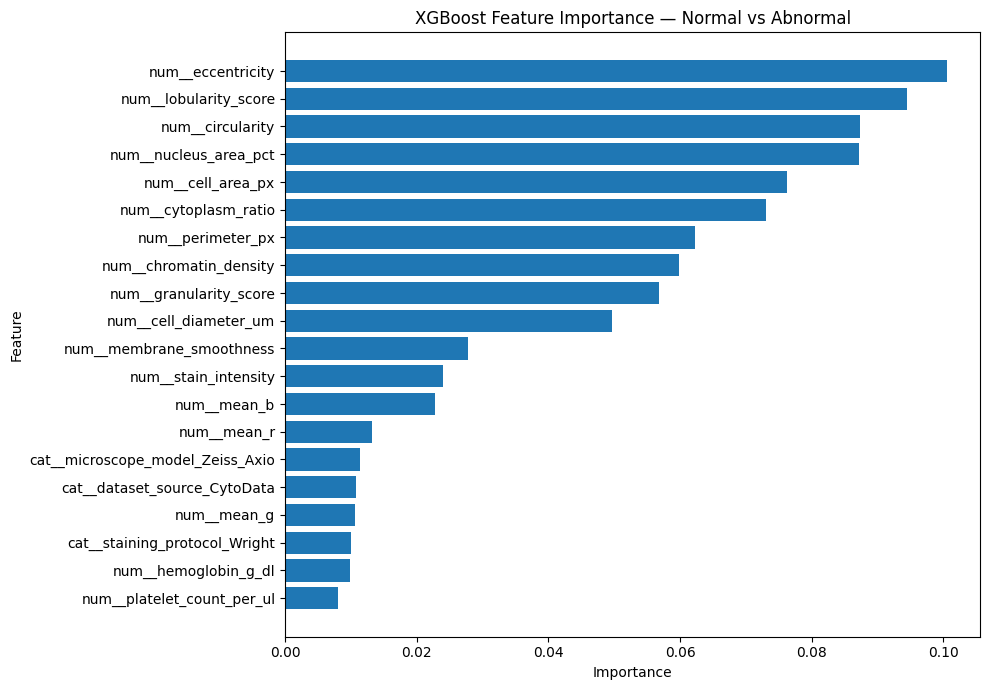

In [ ]:
# ============================================
# CELL 16: XGBOOST FEATURE IMPORTANCE
# ============================================

# Get feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# Get XGBoost importance
importance = xgb_model.feature_importances_

feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
}).sort_values(
    by="Importance",
    ascending=False
)

print("TOP 20 FEATURES")
print("================")

display(
    feature_importance_df.head(20)
)

# Plot top 20
plt.figure(figsize=(10, 7))

top_features = feature_importance_df.head(20).sort_values(
    by="Importance"
)

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("XGBoost Feature Importance — Normal vs Abnormal")

plt.tight_layout()
plt.show()

eccentricity                   lobularity_score         \
                       mean  median       std             mean median   
Anomaly Status                                                          
Abnormal           0.465233  0.3945  0.269873           1.6300    1.0   
Normal             0.318564  0.3110  0.136345           1.8347    1.1   

                         circularity                  nucleus_area_pct  ...  \
                     std        mean median       std             mean  ...   
Anomaly Status                                                          ...   
Abnormal        1.430960    0.679954  0.748  0.214771        41.361117  ...   
Normal          1.116384    0.811239  0.824  0.098063        44.561100  ...   

               perimeter_px chromatin_density                   \
                        std              mean median       std   
Anomaly Status                                                   
Abnormal          23.732992          0.290110  0.311  0.278616   
Normal            19.432206          0.438998  0.524  0.312601   

               granularity_score                  cell_diameter_um          \
                            mean median       std             mean  median   
Anomaly Status                                                               
Abnormal                1.325234  0.810  1.277805        10.359266  10.245   
Normal                  2.143840  2.035  1.420476        10.090257  10.010   

                          
                     std  
Anomaly Status            
Abnormal        3.951398  
Normal          3.484392  

[2 rows x 30 columns]

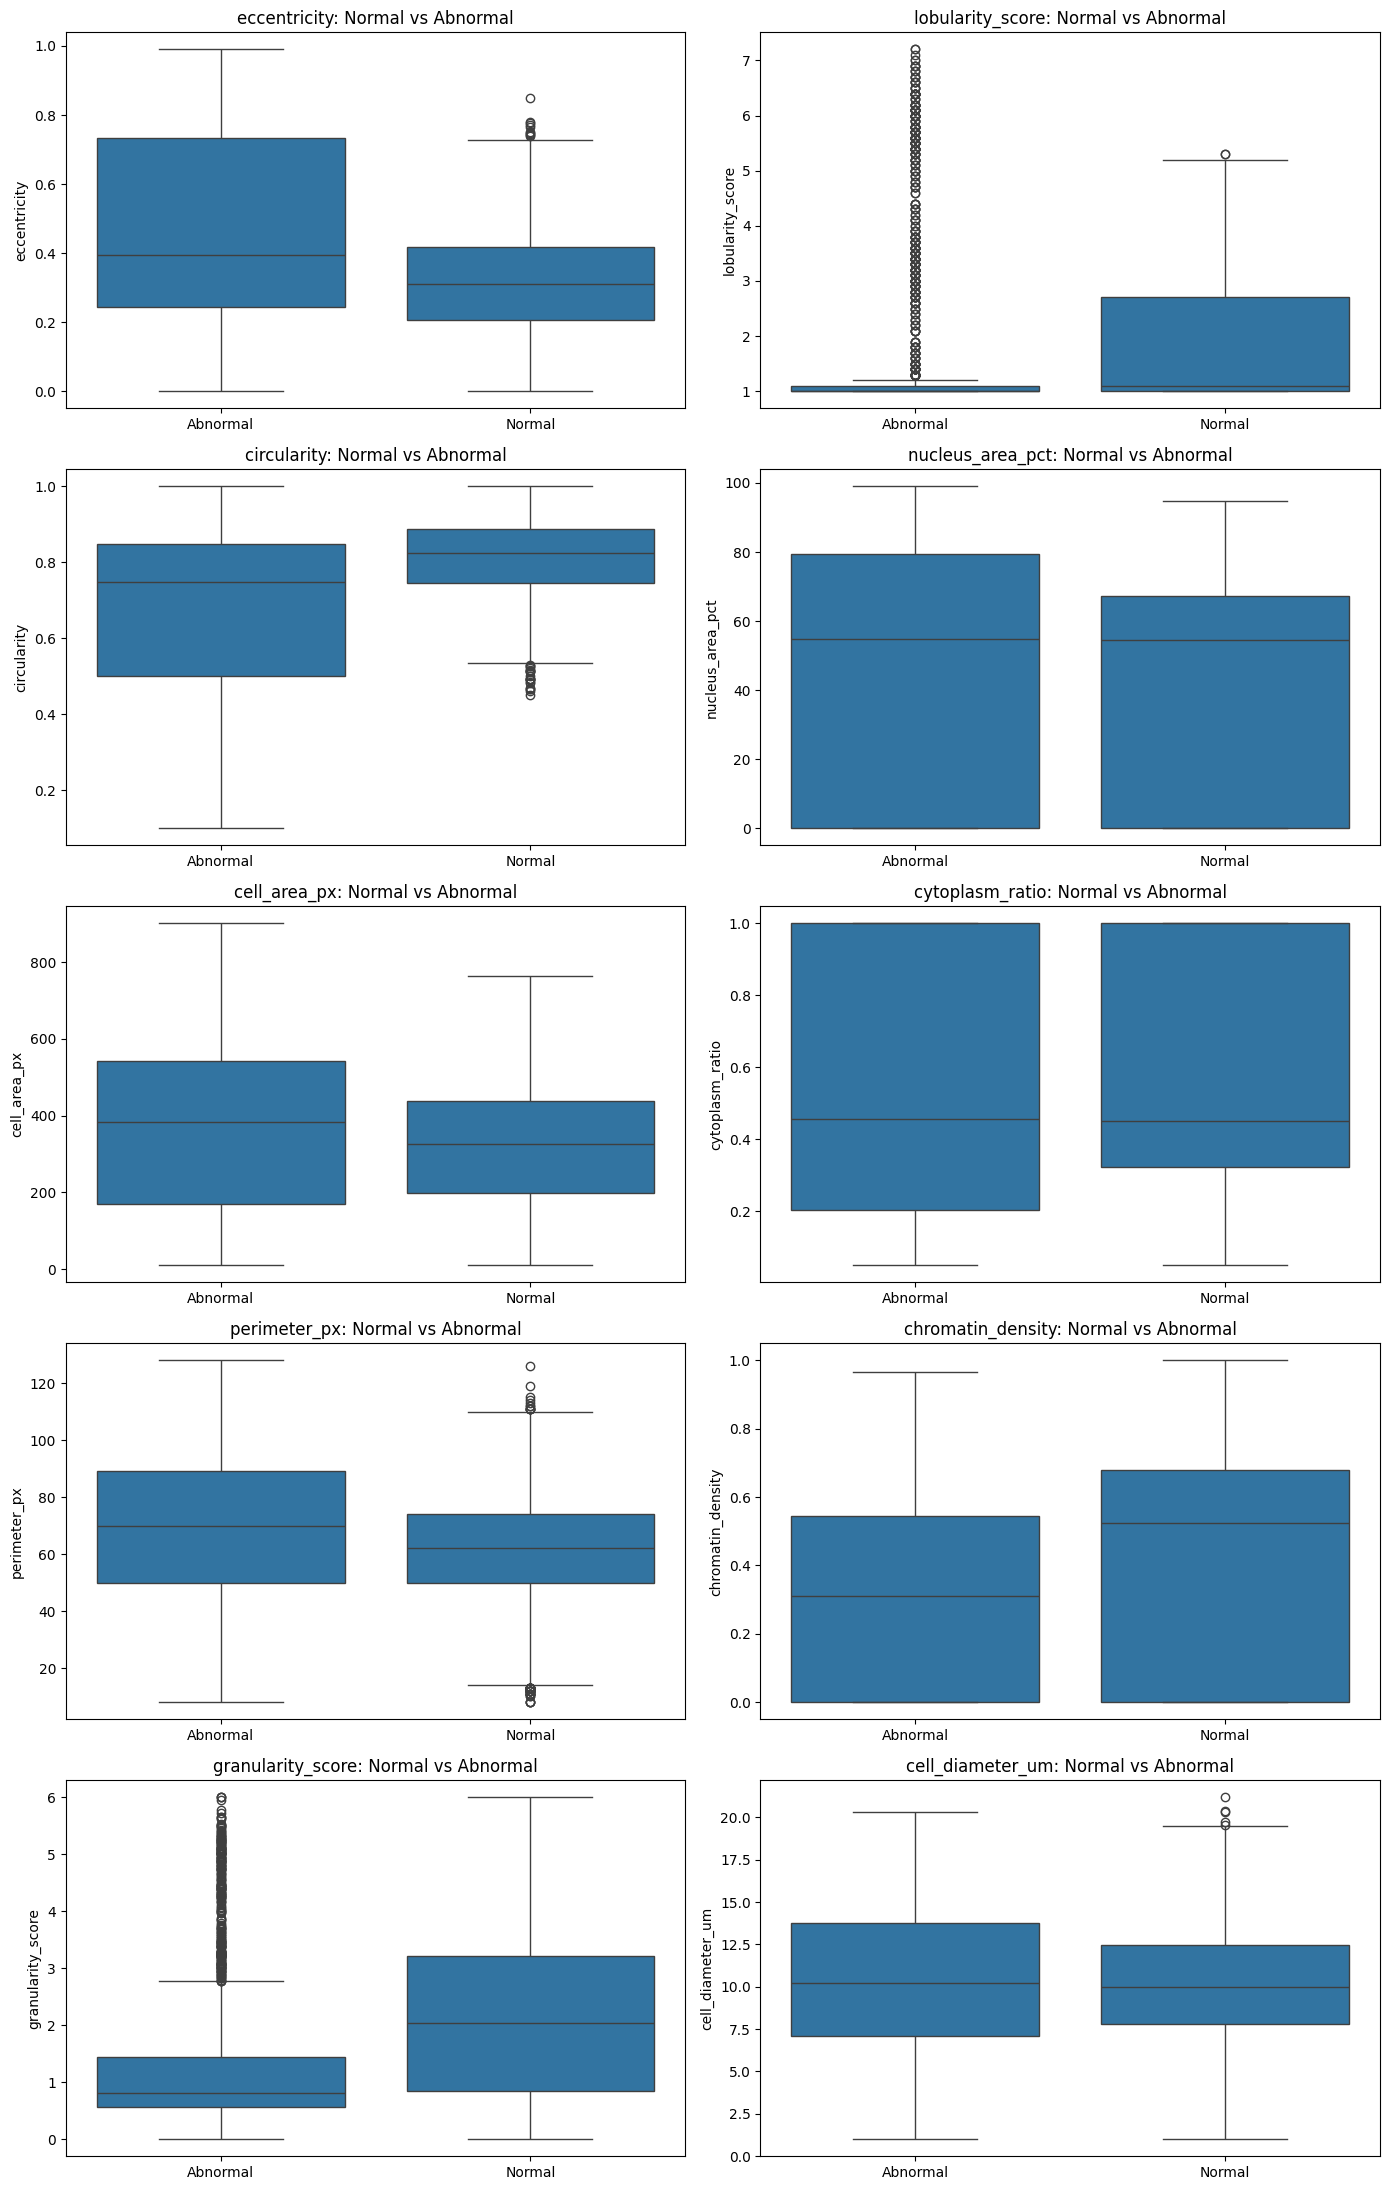

In [ ]:
# ============================================
# CELL 17: FEATURE DISTRIBUTION ANALYSIS
# ============================================

# Select the top morphological features from XGBoost
top_morphological_features = [
    "eccentricity",
    "lobularity_score",
    "circularity",
    "nucleus_area_pct",
    "cell_area_px",
    "cytoplasm_ratio",
    "perimeter_px",
    "chromatin_density",
    "granularity_score",
    "cell_diameter_um"
]

# Create analysis dataframe
analysis_df = blood_df[
    top_morphological_features + ["anomaly_label"]
].copy()

# Convert anomaly label to readable names
analysis_df["Anomaly Status"] = analysis_df["anomaly_label"].map({
    0: "Normal",
    1: "Abnormal"
})

# Summary statistics
summary = analysis_df.groupby(
    "Anomaly Status"
)[top_morphological_features].agg(
    ["mean", "median", "std"]
)

display(summary)

# Boxplots
fig, axes = plt.subplots(
    5, 2,
    figsize=(14, 22)
)

axes = axes.flatten()

for i, feature in enumerate(top_morphological_features):

    sns.boxplot(
        data=analysis_df,
        x="Anomaly Status",
        y=feature,
        ax=axes[i]
    )

    axes[i].set_title(
        f"{feature}: Normal vs Abnormal"
    )

    axes[i].set_xlabel("")
    axes[i].set_ylabel(feature)

plt.tight_layout()
plt.show()

PHENOTYPE DISTRIBUTION


,count
Phenotype_Status,
Normal,796
Abnormal,344
Borderline,36



ABNORMALITY SCORE SUMMARY


,Abnormality_Score
count,1176.000000
mean,0.310867
std,0.443875
min,0.000059
25%,0.001064
50%,0.005804
75%,0.978758
max,0.999972


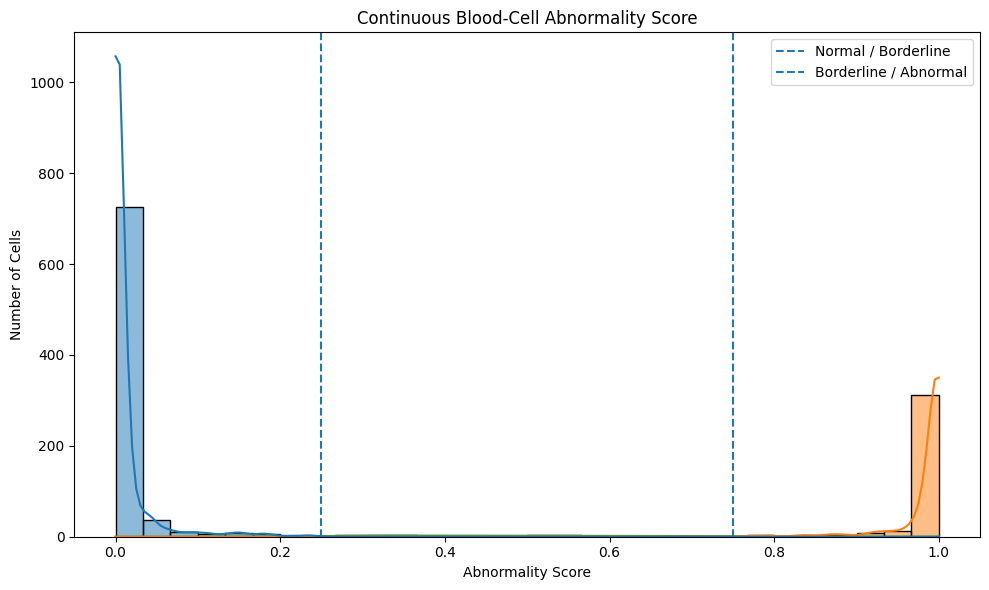

In [ ]:
# ============================================
# CELL 18: CONTINUOUS ABNORMALITY SCORE
# ============================================

# Get probability of being abnormal from XGBoost
abnormal_probability = xgb_model.predict_proba(
    X_test_processed
)[:, 1]

# Create a dataframe for analysis
phenotype_df = X_test.copy()

phenotype_df["True_Label"] = y_test_anomaly.values
phenotype_df["Abnormality_Score"] = abnormal_probability

# Categorize based on model confidence
def assign_phenotype(score):
    if score < 0.25:
        return "Normal"
    elif score < 0.75:
        return "Borderline"
    else:
        return "Abnormal"

phenotype_df["Phenotype_Status"] = phenotype_df[
    "Abnormality_Score"
].apply(assign_phenotype)

print("PHENOTYPE DISTRIBUTION")
print("======================")

display(
    phenotype_df["Phenotype_Status"]
    .value_counts()
)

print("\nABNORMALITY SCORE SUMMARY")
print("==========================")

display(
    phenotype_df["Abnormality_Score"].describe()
)

# Visualize score distribution
plt.figure(figsize=(10, 6))

sns.histplot(
    data=phenotype_df,
    x="Abnormality_Score",
    hue="Phenotype_Status",
    bins=30,
    kde=True
)

plt.axvline(
    0.25,
    linestyle="--",
    label="Normal / Borderline"
)

plt.axvline(
    0.75,
    linestyle="--",
    label="Borderline / Abnormal"
)

plt.title("Continuous Blood-Cell Abnormality Score")
plt.xlabel("Abnormality Score")
plt.ylabel("Number of Cells")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
# ============================================
# CELL 19: UNCERTAINTY / BORDERLINE ANALYSIS
# ============================================

# Add original target information back for analysis
phenotype_df["cell_type"] = blood_df.loc[
    X_test.index, "cell_type"
].values

phenotype_df["disease_category"] = blood_df.loc[
    X_test.index, "disease_category"
].values

# Distance from decision boundary
phenotype_df["Distance_From_0.5"] = abs(
    phenotype_df["Abnormality_Score"] - 0.5
)

# Sort by uncertainty
most_uncertain = phenotype_df.sort_values(
    "Distance_From_0.5"
)

print("MOST UNCERTAIN CELLS")
print("====================")

display(
    most_uncertain[
        [
            "cell_type",
            "disease_category",
            "True_Label",
            "Abnormality_Score",
            "Distance_From_0.5"
        ]
    ].head(30)
)

# --------------------------------------------
# Boundary region
# --------------------------------------------

boundary_range = phenotype_df[
    (phenotype_df["Abnormality_Score"] >= 0.30) &
    (phenotype_df["Abnormality_Score"] <= 0.70)
]

print("\nCELLS BETWEEN 0.30 AND 0.70")
print("===========================")
print("Number of cells:", len(boundary_range))

print("\nTrue label distribution:")
display(
    boundary_range["True_Label"].value_counts()
)

print("\nDisease distribution:")
display(
    boundary_range["disease_category"].value_counts()
)

print("\nCell-type distribution:")
display(
    boundary_range["cell_type"].value_counts()
)

MOST UNCERTAIN CELLS


,cell_type,disease_category,True_Label,Abnormality_Score,Distance_From_0.5
3714,Toxic_Granulation,Infection,1,0.502137,0.002137
1650,Artefact,Artefact,1,0.486531,0.013469
2223,Target_Cell,Anemia,1,0.520594,0.020594
2736,Spherocyte,Anemia,1,0.528261,0.028261
3782,Target_Cell,Anemia,1,0.528815,0.028815
4654,Reactive_Lymphocyte,Infection,1,0.535629,0.035629
802,Normal_RBC,Normal_RBC,0,0.457159,0.042841
2764,Hypersegmented_Neutrophil,Infection,1,0.449204,0.050796
3275,Artefact,Artefact,1,0.551056,0.051056
4891,Reactive_Lymphocyte,Infection,1,0.565057,0.065057



CELLS BETWEEN 0.30 AND 0.70
Number of cells: 27

True label distribution:


,count
True_Label,
1,18
0,9



Disease distribution:


,count
disease_category,
Infection,9
Normal_RBC,6
Anemia,5
Artefact,4
Normal_WBC,2
Normal_Platelet,1



Cell-type distribution:


,count
cell_type,
Normal_RBC,6
Toxic_Granulation,4
Artefact,4
Target_Cell,3
Reactive_Lymphocyte,3
Hypersegmented_Neutrophil,2
Spherocyte,2
Monocyte,1
Platelet,1


BORDERLINE CELLS: 27

DISEASE-WISE BORDERLINE ANALYSIS


,count,mean,median,std
disease_category,,,,
Infection,9,0.527467,0.535629,0.104043
Normal_RBC,6,0.475515,0.442216,0.149719
Anemia,5,0.510318,0.528261,0.067183
Artefact,4,0.418762,0.411545,0.119363
Normal_WBC,2,0.346815,0.346815,0.020713
Normal_Platelet,1,0.390091,0.390091,NaN



CELL-TYPE BORDERLINE ANALYSIS


,count,mean,median,std
cell_type,,,,
Normal_RBC,6,0.475515,0.442216,0.149719
Artefact,4,0.418762,0.411545,0.119363
Toxic_Granulation,4,0.476966,0.463848,0.115170
Reactive_Lymphocyte,3,0.590937,0.565057,0.071833
Target_Cell,3,0.542116,0.528815,0.030437
Hypersegmented_Neutrophil,2,0.533266,0.533266,0.118881
Spherocyte,2,0.462619,0.462619,0.092831
Eosinophil,1,0.332169,0.332169,NaN
Platelet,1,0.390091,0.390091,NaN


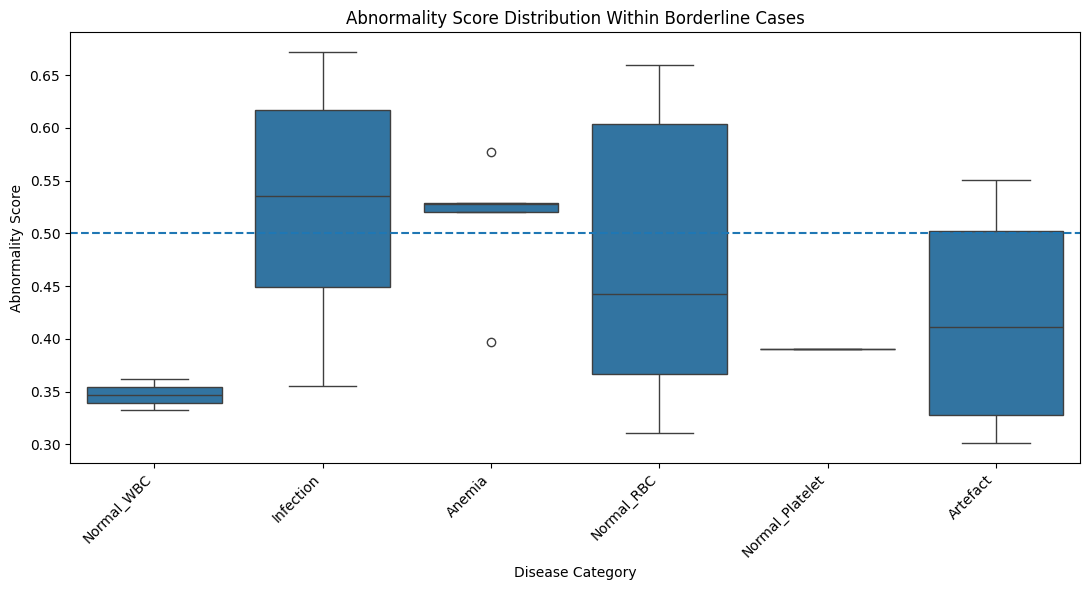

In [ ]:
# ============================================
# CELL 20: BORDERLINE PHENOTYPE ANALYSIS
# ============================================

# Create a clean borderline dataset
borderline_df = boundary_range.copy()

print("BORDERLINE CELLS:", len(borderline_df))

# --------------------------------------------
# Disease-wise abnormality score
# --------------------------------------------

disease_summary = (
    borderline_df
    .groupby("disease_category")["Abnormality_Score"]
    .agg(["count", "mean", "median", "std"])
    .sort_values("count", ascending=False)
)

print("\nDISEASE-WISE BORDERLINE ANALYSIS")
print("=================================")

display(disease_summary)

# --------------------------------------------
# Cell-type-wise analysis
# --------------------------------------------

cell_summary = (
    borderline_df
    .groupby("cell_type")["Abnormality_Score"]
    .agg(["count", "mean", "median", "std"])
    .sort_values("count", ascending=False)
)

print("\nCELL-TYPE BORDERLINE ANALYSIS")
print("==============================")

display(cell_summary)

# --------------------------------------------
# Visualization
# --------------------------------------------

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=borderline_df,
    x="disease_category",
    y="Abnormality_Score"
)

plt.xticks(rotation=45, ha="right")
plt.axhline(0.5, linestyle="--")

plt.title(
    "Abnormality Score Distribution Within Borderline Cases"
)

plt.xlabel("Disease Category")
plt.ylabel("Abnormality Score")

plt.tight_layout()
plt.show()

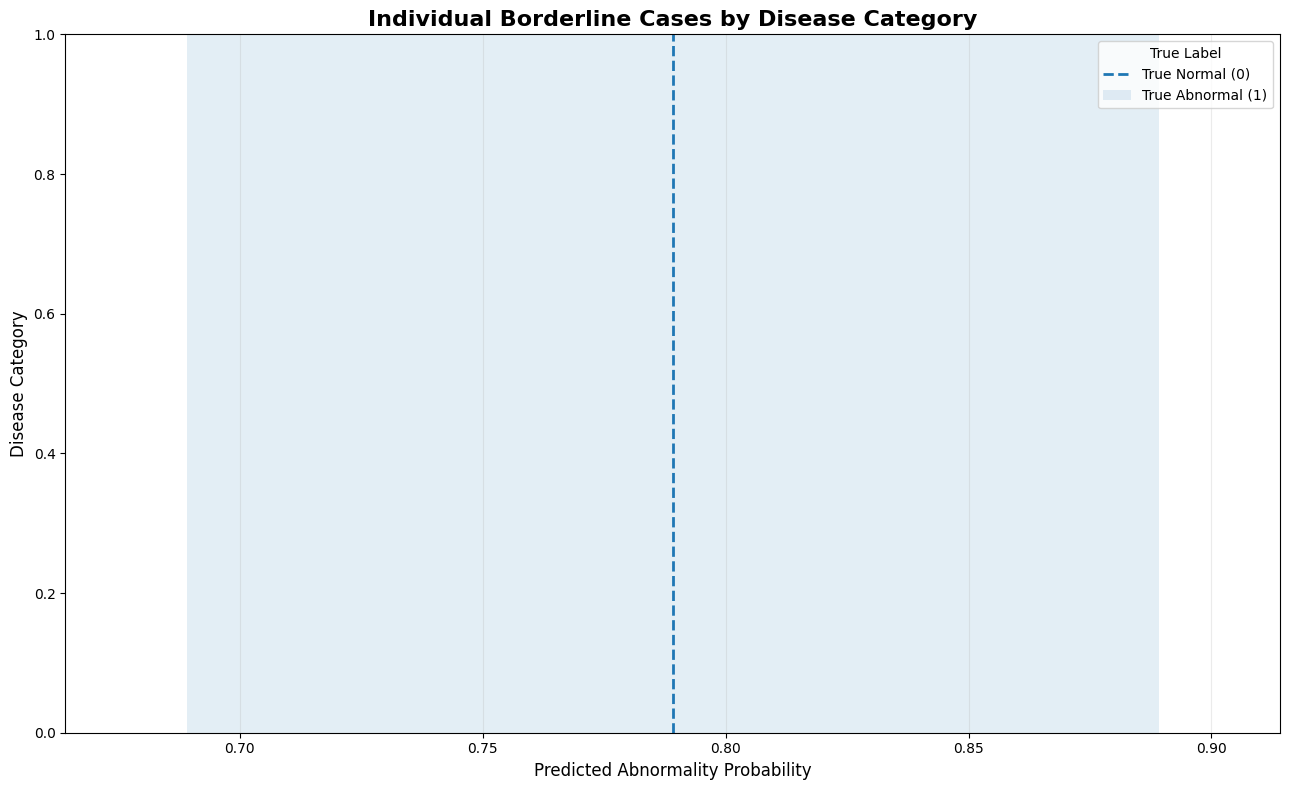

In [ ]:
# ============================================
# CELL 18B: BORDERLINE CASES - INDIVIDUAL
# SCORE VISUALIZATION
# ============================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# --------------------------------------------
# Get uncertain cases
# --------------------------------------------

borderline_df = phenotype_df[
    phenotype_df["Phenotype_Status"] == "Uncertain"
].copy()

# Add disease category safely
borderline_df["Disease Category"] = blood_df.loc[
    borderline_df.index,
    "disease_category"
].values

# --------------------------------------------
# Sort disease categories by median score
# --------------------------------------------

category_order = (
    borderline_df
    .groupby("Disease Category")["Abnormality_Score"]
    .median()
    .sort_values()
    .index
)

# --------------------------------------------
# Plot
# --------------------------------------------

plt.figure(figsize=(13, 8))

ax = sns.stripplot(
    data=borderline_df,
    x="Abnormality_Score",
    y="Disease Category",
    order=category_order,
    hue="True_Label",
    dodge=False,
    jitter=0.12,
    size=11,
    alpha=0.85
)

# --------------------------------------------
# Operating threshold
# --------------------------------------------

operating_threshold = 0.7891

plt.axvline(
    operating_threshold,
    linestyle="--",
    linewidth=2,
    label=f"Operating threshold = {operating_threshold:.3f}"
)

# --------------------------------------------
# Uncertainty boundaries
# --------------------------------------------

lower_threshold = 0.6891
upper_threshold = 0.8891

plt.axvspan(
    lower_threshold,
    upper_threshold,
    alpha=0.12,
    label="Uncertainty region"
)

# --------------------------------------------
# Add score labels to each point
# --------------------------------------------

for _, row in borderline_df.iterrows():

    category_position = list(category_order).index(
        row["Disease Category"]
    )

    plt.text(
        row["Abnormality_Score"] + 0.006,
        category_position,
        f"{row['Abnormality_Score']:.3f}",
        va="center",
        fontsize=9
    )

# --------------------------------------------
# Formatting
# --------------------------------------------

plt.xlim(
    lower_threshold - 0.025,
    upper_threshold + 0.025
)

plt.xlabel(
    "Predicted Abnormality Probability",
    fontsize=12
)

plt.ylabel(
    "Disease Category",
    fontsize=12
)

plt.title(
    "Individual Borderline Cases by Disease Category",
    fontsize=16,
    fontweight="bold"
)

plt.grid(
    axis="x",
    alpha=0.25
)

plt.legend(
    title="True Label",
    labels=[
        "True Normal (0)",
        "True Abnormal (1)"
    ]
)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================
# CELL 21: PHENOTYPE FEATURE MATRIX
# ============================================

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import HDBSCAN
from sklearn.metrics import silhouette_score

# Morphological + hematological features
phenotype_features = [
    "cell_diameter_um",
    "nucleus_area_pct",
    "chromatin_density",
    "cytoplasm_ratio",
    "circularity",
    "eccentricity",
    "granularity_score",
    "lobularity_score",
    "membrane_smoothness",
    "cell_area_px",
    "perimeter_px",
    "mean_r",
    "mean_g",
    "mean_b",
    "stain_intensity",
    "wbc_count_per_ul",
    "rbc_count_millions_per_ul",
    "hemoglobin_g_dl",
    "hematocrit_pct",
    "platelet_count_per_ul",
    "mcv_fl",
    "mchc_g_dl"
]

# Create phenotype matrix
phenotype_X = blood_df[phenotype_features].copy()

# Handle any missing values
phenotype_X = phenotype_X.fillna(
    phenotype_X.median()
)

# Standardize
phenotype_scaler = StandardScaler()

phenotype_scaled = phenotype_scaler.fit_transform(
    phenotype_X
)

print("PHENOTYPE MATRIX")
print("================")

print("Samples :", phenotype_scaled.shape[0])
print("Features:", phenotype_scaled.shape[1])

print("\nReady for unsupervised phenotype discovery.")

PHENOTYPE MATRIX
Samples : 5880
Features: 22

Ready for unsupervised phenotype discovery.


In [ ]:
# ============================================
# CELL 22: HDBSCAN PHENOTYPE DISCOVERY
# ============================================

# HDBSCAN finds natural phenotype groups
# without forcing every cell into a cluster.

hdbscan_model = HDBSCAN(
    min_cluster_size=80,
    min_samples=20,
    metric="euclidean",
    cluster_selection_method="eom"
)

phenotype_clusters = hdbscan_model.fit_predict(
    phenotype_scaled
)

# Add clusters to original dataframe
phenotype_results = blood_df.copy()

phenotype_results["phenotype_cluster"] = phenotype_clusters

print("PHENOTYPE CLUSTERING RESULTS")
print("============================")

print(
    "Total cells:",
    len(phenotype_results)
)

print(
    "Number of clusters:",
    len(set(phenotype_clusters)) - (
        1 if -1 in phenotype_clusters else 0
    )
)

print(
    "Noise / ambiguous cells:",
    sum(phenotype_clusters == -1)
)

print("\nCLUSTER DISTRIBUTION")
print("====================")

display(
    phenotype_results["phenotype_cluster"]
    .value_counts()
    .sort_index()
)

PHENOTYPE CLUSTERING RESULTS
Total cells: 5880
Number of clusters: 4
Noise / ambiguous cells: 761

CLUSTER DISTRIBUTION


,count
phenotype_cluster,
-1,761
0,3601
1,121
2,269
3,1128


In [ ]:
# ============================================
# CELL 23: CLUSTER PHENOTYPE INTERPRETATION
# ============================================

# Exclude HDBSCAN noise for cluster interpretation
clustered = phenotype_results[
    phenotype_results["phenotype_cluster"] != -1
].copy()

print("CLUSTER vs CELL TYPE")
print("====================")

cluster_celltype = pd.crosstab(
    clustered["phenotype_cluster"],
    clustered["cell_type"],
    normalize="index"
) * 100

display(
    cluster_celltype.round(2)
)

print("\nCLUSTER vs DISEASE CATEGORY")
print("===========================")

cluster_disease = pd.crosstab(
    clustered["phenotype_cluster"],
    clustered["disease_category"],
    normalize="index"
) * 100

display(
    cluster_disease.round(2)
)

print("\nCLUSTER SIZE")
print("============")

display(
    clustered["phenotype_cluster"]
    .value_counts()
    .sort_index()
)

CLUSTER vs CELL TYPE


cell_type,Basophil,Blast_Cell,Elliptocyte,Eosinophil,Hypersegmented_Neutrophil,Lymphocyte,Monocyte,Neutrophil,Normal_RBC,Platelet,Prolymphocyte,Reactive_Lymphocyte,Schistocyte,Sickle_Cell,Smudge_Cell,Spherocyte,Target_Cell,Toxic_Granulation
phenotype_cluster,,,,,,,,,,,,,,,,,,
0,3.8,7.16,0.00,7.94,3.97,23.49,10.72,30.16,0.0,0.00,4.67,3.97,0.00,0.00,0.31,0.00,0.00,3.8
1,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0,99.17,0.00,0.00,0.83,0.00,0.00,0.00,0.00,0.0
2,0.0,0.00,45.35,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00,25.28,29.37,0.00,0.00,0.00,0.0
3,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,76.6,0.00,0.00,0.00,0.00,0.00,0.00,12.59,10.82,0.0



CLUSTER vs DISEASE CATEGORY


disease_category,Anemia,Artefact,Infection,Leukemia,Normal_Platelet,Normal_RBC,Normal_WBC,Sickle_Cell_Anemia
phenotype_cluster,,,,,,,,
0,0.00,0.31,11.75,11.83,0.00,0.0,76.12,0.00
1,0.83,0.00,0.00,0.00,99.17,0.0,0.00,0.00
2,70.63,0.00,0.00,0.00,0.00,0.0,0.00,29.37
3,23.40,0.00,0.00,0.00,0.00,76.6,0.00,0.00



CLUSTER SIZE


,count
phenotype_cluster,
0,3601
1,121
2,269
3,1128


In [ ]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

# Remove HDBSCAN noise
eval_df = phenotype_results[
    phenotype_results["phenotype_cluster"] != -1
].copy()

# Cluster vs cell type
cell_ari = adjusted_rand_score(
    eval_df["cell_type"],
    eval_df["phenotype_cluster"]
)

cell_nmi = normalized_mutual_info_score(
    eval_df["cell_type"],
    eval_df["phenotype_cluster"]
)

# Cluster vs disease
disease_ari = adjusted_rand_score(
    eval_df["disease_category"],
    eval_df["phenotype_cluster"]
)

disease_nmi = normalized_mutual_info_score(
    eval_df["disease_category"],
    eval_df["phenotype_cluster"]
)

print("CLUSTER VALIDATION")
print("==================")
print(f"Cell Type  - ARI: {cell_ari:.4f}")
print(f"Cell Type  - NMI: {cell_nmi:.4f}")
print(f"Disease    - ARI: {disease_ari:.4f}")
print(f"Disease    - NMI: {disease_nmi:.4f}")

CLUSTER VALIDATION
Cell Type  - ARI: 0.2013
Cell Type  - NMI: 0.5042
Disease    - ARI: 0.5791
Disease    - NMI: 0.6769


In [ ]:
from sklearn.metrics import adjusted_rand_score
from sklearn.cluster import HDBSCAN

# Test clustering stability using different random subsets
stability_scores = []

for seed in [42, 52, 62, 72, 82]:

    sample_df = blood_df.sample(
        n=int(len(blood_df) * 0.80),
        random_state=seed
    )

    X_sample = sample_df[phenotype_features].copy()

    # Use the same preprocessing approach
    X_sample = X_sample.fillna(phenotype_X.median())

    X_sample_scaled = phenotype_scaler.transform(X_sample)

    model = HDBSCAN(
        min_cluster_size=80,
        min_samples=20,
        metric="euclidean",
        cluster_selection_method="eom"
    )

    labels = model.fit_predict(X_sample_scaled)

    valid = labels != -1

    score = adjusted_rand_score(
        sample_df.loc[valid, "disease_category"],
        labels[valid]
    )

    stability_scores.append(score)

    print(f"Seed {seed}: Disease ARI = {score:.4f}")

print("\nMean ARI:", np.mean(stability_scores).round(4))
print("Std ARI :", np.std(stability_scores).round(4))

Seed 42: Disease ARI = 0.5794
Seed 52: Disease ARI = 0.5854
Seed 62: Disease ARI = 0.5087
Seed 72: Disease ARI = 0.5102
Seed 82: Disease ARI = 0.5807

Mean ARI: 0.5529
Std ARI : 0.0355


In [ ]:
# Merge cluster information with abnormality scores
analysis_df = phenotype_results.copy()

# Get XGBoost abnormality scores for test samples
analysis_df["Abnormality_Score"] = np.nan
analysis_df.loc[X_test.index, "Abnormality_Score"] = abnormal_probability

# Compare abnormality score across discovered clusters
cluster_score_summary = (
    analysis_df[
        analysis_df["phenotype_cluster"] != -1
    ]
    .groupby("phenotype_cluster")["Abnormality_Score"]
    .agg(["count", "mean", "median", "std"])
    .round(4)
)

print("ABNORMALITY SCORE BY PHENOTYPE CLUSTER")
print("======================================")
display(cluster_score_summary)

ABNORMALITY SCORE BY PHENOTYPE CLUSTER


,count,mean,median,std
phenotype_cluster,,,,
0,711,0.2274,0.0022,0.4041
1,26,0.0125,0.0011,0.0531
2,51,0.9995,0.9998,0.0007
3,232,0.2268,0.0141,0.3716


In [ ]:
from scipy.stats import kruskal

score_df = analysis_df[
    (analysis_df["phenotype_cluster"] != -1) &
    (analysis_df["Abnormality_Score"].notna())
].copy()

groups = [
    group["Abnormality_Score"].values
    for _, group in score_df.groupby("phenotype_cluster")
]

kruskal_stat, kruskal_p = kruskal(*groups)

print("KRUSKAL-WALLIS TEST")
print("===================")
print(f"H-statistic: {kruskal_stat:.4f}")
print(f"p-value    : {kruskal_p:.6e}")

KRUSKAL-WALLIS TEST
H-statistic: 178.5159
p-value    : 1.844872e-38


In [ ]:
from scipy.stats import mannwhitneyu
from itertools import combinations
from statsmodels.stats.multitest import multipletests

pair_results = []

clusters = sorted(score_df["phenotype_cluster"].unique())

for c1, c2 in combinations(clusters, 2):

    s1 = score_df.loc[
        score_df["phenotype_cluster"] == c1,
        "Abnormality_Score"
    ]

    s2 = score_df.loc[
        score_df["phenotype_cluster"] == c2,
        "Abnormality_Score"
    ]

    stat, p = mannwhitneyu(
        s1,
        s2,
        alternative="two-sided"
    )

    pair_results.append({
        "Cluster_1": c1,
        "Cluster_2": c2,
        "U_statistic": stat,
        "Raw_p": p
    })

pairwise_df = pd.DataFrame(pair_results)

# Bonferroni correction
pairwise_df["Adjusted_p"] = multipletests(
    pairwise_df["Raw_p"],
    method="bonferroni"
)[1]

display(pairwise_df.round(6))

,Cluster_1,Cluster_2,U_statistic,Raw_p,Adjusted_p
0,0,1,11762.0,0.018176,0.109055
1,0,2,1291.0,0.000000,0.000000
2,0,3,58848.0,0.000000,0.000000
3,1,2,0.0,0.000000,0.000000
4,1,3,876.0,0.000000,0.000000
5,2,3,11732.0,0.000000,0.000000


In [ ]:
from itertools import combinations

def cliffs_delta(x, y):
    x = np.asarray(x)
    y = np.asarray(y)

    greater = 0
    less = 0

    for xi in x:
        greater += np.sum(xi > y)
        less += np.sum(xi < y)

    return (greater - less) / (len(x) * len(y))


effect_results = []

for c1, c2 in combinations(clusters, 2):

    s1 = score_df.loc[
        score_df["phenotype_cluster"] == c1,
        "Abnormality_Score"
    ].values

    s2 = score_df.loc[
        score_df["phenotype_cluster"] == c2,
        "Abnormality_Score"
    ].values

    delta = cliffs_delta(s1, s2)

    effect_results.append({
        "Cluster_1": c1,
        "Cluster_2": c2,
        "Cliffs_Delta": delta,
        "Abs_Delta": abs(delta)
    })

effect_df = pd.DataFrame(effect_results)

display(effect_df.round(4))

,Cluster_1,Cluster_2,Cliffs_Delta,Abs_Delta
0,0,1,0.2725,0.2725
1,0,2,-0.9288,0.9288
2,0,3,-0.2865,0.2865
3,1,2,-1.0000,1.0000
4,1,3,-0.7095,0.7095
5,2,3,0.9831,0.9831


In [ ]:
cluster_abnormality = (
    score_df
    .assign(
        Abnormal = score_df["Abnormality_Score"] >= 0.75
    )
    .groupby("phenotype_cluster")
    .agg(
        Total_Cells=("Abnormal", "size"),
        Abnormal_Cells=("Abnormal", "sum"),
        Abnormal_Percentage=("Abnormal", "mean")
    )
)

cluster_abnormality["Abnormal_Percentage"] *= 100

display(cluster_abnormality.round(2))

,Total_Cells,Abnormal_Cells,Abnormal_Percentage
phenotype_cluster,,,
0,711,153,21.52
1,26,0,0.00
2,51,51,100.00
3,232,42,18.10


In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score

# Training probabilities
train_probability = xgb_model.predict_proba(X_train_processed)[:, 1]

# ROC curve on training data
fpr, tpr, thresholds = roc_curve(
    y_train_anomaly,
    train_probability
)

# Youden's J statistic
youden_j = tpr - fpr
best_idx = np.argmax(youden_j)

optimal_threshold = thresholds[best_idx]

print("TRAINING-BASED THRESHOLD")
print("========================")
print(f"Optimal threshold : {optimal_threshold:.4f}")
print(f"Sensitivity       : {tpr[best_idx]:.4f}")
print(f"Specificity       : {1 - fpr[best_idx]:.4f}")

print("\nTest ROC-AUC:", roc_auc_score(
    y_test_anomaly,
    abnormal_probability
).round(4))

TRAINING-BASED THRESHOLD
Optimal threshold : 0.7891
Sensitivity       : 1.0000
Specificity       : 1.0000

Test ROC-AUC: 0.9975


In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Apply training-derived threshold to untouched test set
test_pred_threshold = (
    abnormal_probability >= optimal_threshold
).astype(int)

cm = confusion_matrix(
    y_test_anomaly,
    test_pred_threshold
)

tn, fp, fn, tp = cm.ravel()

sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)

print("TEST PERFORMANCE USING TRAINING-DERIVED THRESHOLD")
print("=================================================")
print(f"Threshold   : {optimal_threshold:.4f}")
print(f"Accuracy    : {accuracy_score(y_test_anomaly, test_pred_threshold):.4f}")
print(f"Precision   : {precision_score(y_test_anomaly, test_pred_threshold):.4f}")
print(f"Sensitivity : {sensitivity:.4f}")
print(f"Specificity : {specificity:.4f}")
print(f"F1-score    : {f1_score(y_test_anomaly, test_pred_threshold):.4f}")

print("\nConfusion Matrix:")
print(cm)

TEST PERFORMANCE USING TRAINING-DERIVED THRESHOLD
Threshold   : 0.7891
Accuracy    : 0.9702
Precision   : 0.9971
Sensitivity : 0.9096
Specificity : 0.9988
F1-score    : 0.9513

Confusion Matrix:
[[799   1]
 [ 34 342]]


In [ ]:
print("Potential patient-related columns:")
print([
    col for col in blood_df.columns
    if any(word in col.lower() for word in [
        "patient", "subject", "case", "sample", "donor"
    ])
])

Potential patient-related columns:
['patient_age_group', 'patient_sex']


In [ ]:
# Define feature groups
morphology_features = [
    "cell_diameter_um",
    "nucleus_area_pct",
    "chromatin_density",
    "cytoplasm_ratio",
    "circularity",
    "eccentricity",
    "granularity_score",
    "lobularity_score",
    "membrane_smoothness",
    "cell_area_px",
    "perimeter_px",
    "mean_r",
    "mean_g",
    "mean_b",
    "stain_intensity"
]

hematology_features = [
    "wbc_count_per_ul",
    "rbc_count_millions_per_ul",
    "hemoglobin_g_dl",
    "hematocrit_pct",
    "platelet_count_per_ul",
    "mcv_fl",
    "mchc_g_dl"
]

print("Morphology features:", len(morphology_features))
print("Hematology features:", len(hematology_features))
print("Total:", len(morphology_features + hematology_features))

Morphology features: 15
Hematology features: 7
Total: 22


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Common categorical features
categorical_features = [
    "patient_age_group",
    "patient_sex",
    "dataset_source",
    "staining_protocol",
    "microscope_model"
]

# Create three feature sets
X_morphology = blood_df[
    morphology_features + categorical_features
].copy()

X_hematology = blood_df[
    hematology_features + categorical_features
].copy()

X_combined = blood_df[
    morphology_features + hematology_features + categorical_features
].copy()

print("Feature-set shapes")
print("==================")
print("Morphology :", X_morphology.shape)
print("Hematology :", X_hematology.shape)
print("Combined   :", X_combined.shape)

Feature-set shapes
Morphology : (5880, 20)
Hematology : (5880, 12)
Combined   : (5880, 27)


In [ ]:
from sklearn.model_selection import train_test_split

# Use exactly the same indices for all experiments
train_idx, test_idx = train_test_split(
    np.arange(len(blood_df)),
    test_size=0.20,
    random_state=42,
    stratify=y_anomaly
)

X_morph_train = X_morphology.iloc[train_idx]
X_morph_test  = X_morphology.iloc[test_idx]

X_hema_train = X_hematology.iloc[train_idx]
X_hema_test  = X_hematology.iloc[test_idx]

X_comb_train = X_combined.iloc[train_idx]
X_comb_test  = X_combined.iloc[test_idx]

y_train = y_anomaly.iloc[train_idx]
y_test = y_anomaly.iloc[test_idx]

print("Train samples:", len(train_idx))
print("Test samples :", len(test_idx))
print("Same test set:", np.array_equal(test_idx, np.array(test_idx)))

Train samples: 4704
Test samples : 1176
Same test set: True


In [ ]:
def build_preprocessor(X):
    num_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
    cat_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()

    return ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), num_cols),
            ("cat", OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ), cat_cols)
        ]
    )


# Create separate preprocessors
morph_preprocessor = build_preprocessor(X_morphology)
hema_preprocessor = build_preprocessor(X_hematology)
combined_preprocessor = build_preprocessor(X_combined)


# Fit ONLY on training data
X_morph_train_p = morph_preprocessor.fit_transform(X_morph_train)
X_morph_test_p = morph_preprocessor.transform(X_morph_test)

X_hema_train_p = hema_preprocessor.fit_transform(X_hema_train)
X_hema_test_p = hema_preprocessor.transform(X_hema_test)

X_comb_train_p = combined_preprocessor.fit_transform(X_comb_train)
X_comb_test_p = combined_preprocessor.transform(X_comb_test)


print("Processed shapes")
print("================")
print("Morphology :", X_morph_train_p.shape, X_morph_test_p.shape)
print("Hematology :", X_hema_train_p.shape, X_hema_test_p.shape)
print("Combined   :", X_comb_train_p.shape, X_comb_test_p.shape)

Processed shapes
Morphology : (4704, 29) (1176, 29)
Hematology : (4704, 21) (1176, 21)
Combined   : (4704, 36) (1176, 36)


In [ ]:
from xgboost import XGBClassifier

def train_xgb(X_train, y_train):
    model = XGBClassifier(
        n_estimators=500,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)
    return model


# Train three models
morph_model = train_xgb(X_morph_train_p, y_train)
hema_model = train_xgb(X_hema_train_p, y_train)
combined_model = train_xgb(X_comb_train_p, y_train)

print("All three XGBoost models trained successfully.")

All three XGBoost models trained successfully.


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

models = {
    "Morphology": (morph_model, X_morph_test_p),
    "Hematology": (hema_model, X_hema_test_p),
    "Combined": (combined_model, X_comb_test_p)
}

ablation_results = []

for name, (model, X_test_p) in models.items():

    prob = model.predict_proba(X_test_p)[:, 1]
    pred = (prob >= 0.5).astype(int)

    ablation_results.append({
        "Feature_Set": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Sensitivity": recall_score(y_test, pred),
        "Specificity": (
            ((y_test == 0) & (pred == 0)).sum()
            / (y_test == 0).sum()
        ),
        "F1": f1_score(y_test, pred),
        "ROC_AUC": roc_auc_score(y_test, prob),
        "PR_AUC": average_precision_score(y_test, prob)
    })

ablation_df = pd.DataFrame(ablation_results)

display(ablation_df.round(4))

,Feature_Set,Accuracy,Precision,Sensitivity,Specificity,F1,ROC_AUC,PR_AUC
0,Morphology,0.9804,0.9889,0.9495,0.9950,0.9688,0.9978,0.9960
1,Hematology,0.6259,0.2377,0.0771,0.8838,0.1165,0.4708,0.2964
2,Combined,0.9787,0.9861,0.9468,0.9938,0.9661,0.9979,0.9959


In [ ]:
# Morphology-only phenotype discovery

morph_cluster_features = blood_df[morphology_features].copy()
morph_cluster_features = morph_cluster_features.fillna(
    morph_cluster_features.median()
)

morph_scaler = StandardScaler()
morph_scaled = morph_scaler.fit_transform(morph_cluster_features)

morph_hdbscan = HDBSCAN(
    min_cluster_size=80,
    min_samples=20,
    metric="euclidean",
    cluster_selection_method="eom"
)

morph_clusters = morph_hdbscan.fit_predict(morph_scaled)

morph_clustered = blood_df.copy()
morph_clustered["morph_cluster"] = morph_clusters

valid = morph_clusters != -1

morph_disease_ari = adjusted_rand_score(
    morph_clustered.loc[valid, "disease_category"],
    morph_clusters[valid]
)

morph_disease_nmi = normalized_mutual_info_score(
    morph_clustered.loc[valid, "disease_category"],
    morph_clusters[valid]
)

print("MORPHOLOGY-ONLY CLUSTERING")
print("==========================")
print("Clusters:", len(set(morph_clusters)) - (1 if -1 in morph_clusters else 0))
print("Noise:", (morph_clusters == -1).sum())
print(f"Disease ARI: {morph_disease_ari:.4f}")
print(f"Disease NMI: {morph_disease_nmi:.4f}")

MORPHOLOGY-ONLY CLUSTERING
Clusters: 4
Noise: 134
Disease ARI: 0.5784
Disease NMI: 0.6950


In [ ]:
# Hematology-only phenotype discovery

hema_cluster_features = blood_df[hematology_features].copy()
hema_cluster_features = hema_cluster_features.fillna(
    hema_cluster_features.median()
)

hema_scaler = StandardScaler()
hema_scaled = hema_scaler.fit_transform(hema_cluster_features)

hema_hdbscan = HDBSCAN(
    min_cluster_size=80,
    min_samples=20,
    metric="euclidean",
    cluster_selection_method="eom"
)

hema_clusters = hema_hdbscan.fit_predict(hema_scaled)

hema_clustered = blood_df.copy()
hema_clustered["hema_cluster"] = hema_clusters

valid = hema_clusters != -1

hema_disease_ari = adjusted_rand_score(
    hema_clustered.loc[valid, "disease_category"],
    hema_clusters[valid]
)

hema_disease_nmi = normalized_mutual_info_score(
    hema_clustered.loc[valid, "disease_category"],
    hema_clusters[valid]
)

print("HEMATOLOGY-ONLY CLUSTERING")
print("==========================")
print("Clusters:", len(set(hema_clusters)) - (1 if -1 in hema_clusters else 0))
print("Noise:", (hema_clusters == -1).sum())
print(f"Disease ARI: {hema_disease_ari:.4f}")
print(f"Disease NMI: {hema_disease_nmi:.4f}")

HEMATOLOGY-ONLY CLUSTERING
Clusters: 0
Noise: 5880
Disease ARI: 1.0000
Disease NMI: 1.0000


In [ ]:
print("HEMATOLOGY FEATURE VARIATION")
print("============================")

hema_variation = blood_df[hematology_features].agg(
    ["mean", "std", "min", "max"]
).T

display(hema_variation.round(4))

HEMATOLOGY FEATURE VARIATION


,mean,std,min,max
wbc_count_per_ul,7043.2740,2481.9999,1000.00,16855.0
rbc_count_millions_per_ul,4.7907,0.8059,2.11,7.0
hemoglobin_g_dl,13.5472,2.0251,5.40,20.0
hematocrit_pct,41.0220,5.4846,20.30,60.0
platelet_count_per_ul,249792.6235,79472.6762,20000.00,543084.0
mcv_fl,88.9422,9.9270,60.00,120.0
mchc_g_dl,33.4959,1.4802,28.00,38.0


In [ ]:
# Attach morphology clusters
cluster_analysis = blood_df.copy()
cluster_analysis["morph_cluster"] = morph_clusters

# Remove HDBSCAN noise
cluster_analysis = cluster_analysis[
    cluster_analysis["morph_cluster"] != -1
]

# Mean hematology values by morphology phenotype
hema_by_cluster = (
    cluster_analysis
    .groupby("morph_cluster")[hematology_features]
    .mean()
    .round(2)
)

print("HEMATOLOGY PROFILE BY MORPHOLOGY PHENOTYPE")
print("===========================================")
display(hema_by_cluster)

HEMATOLOGY PROFILE BY MORPHOLOGY PHENOTYPE


,wbc_count_per_ul,rbc_count_millions_per_ul,hemoglobin_g_dl,hematocrit_pct,platelet_count_per_ul,mcv_fl,mchc_g_dl
morph_cluster,,,,,,,
0,7067.47,4.80,13.57,40.95,250178.06,88.96,33.48
1,7108.90,4.80,13.50,40.91,246430.22,88.70,33.44
2,6796.89,4.82,13.47,41.02,250786.30,89.11,33.62
3,7004.90,4.76,13.52,41.29,248456.97,88.81,33.49


In [ ]:
import shap

# Get the transformed feature names
feature_names = combined_preprocessor.get_feature_names_out()

print("Number of transformed features:", len(feature_names))
print("\nFirst 20 features:")
print(feature_names[:20])

Number of transformed features: 36

First 20 features:
['num__cell_diameter_um' 'num__nucleus_area_pct' 'num__chromatin_density'
 'num__cytoplasm_ratio' 'num__circularity' 'num__eccentricity'
 'num__granularity_score' 'num__lobularity_score'
 'num__membrane_smoothness' 'num__cell_area_px' 'num__perimeter_px'
 'num__mean_r' 'num__mean_g' 'num__mean_b' 'num__stain_intensity'
 'num__wbc_count_per_ul' 'num__rbc_count_millions_per_ul'
 'num__hemoglobin_g_dl' 'num__hematocrit_pct' 'num__platelet_count_per_ul']


In [ ]:
# Create SHAP TreeExplainer
explainer = shap.TreeExplainer(combined_model)

# Calculate SHAP values on the held-out test set
shap_values = explainer.shap_values(X_comb_test_p)

print("SHAP shape:", shap_values.shape)
print("Test feature matrix shape:", X_comb_test_p.shape)

SHAP shape: (1176, 36)
Test feature matrix shape: (1176, 36)


In [ ]:
# Global SHAP feature importance
mean_abs_shap = np.abs(shap_values).mean(axis=0)

shap_importance = pd.DataFrame({
    "Feature": feature_names,
    "Mean_Abs_SHAP": mean_abs_shap
}).sort_values(
    "Mean_Abs_SHAP",
    ascending=False
)

print("TOP 20 SHAP FEATURES")
print("====================")
display(shap_importance.head(20).round(6))

TOP 20 SHAP FEATURES


,Feature,Mean_Abs_SHAP
6,num__granularity_score,1.399227
4,num__circularity,0.861019
7,num__lobularity_score,0.788805
5,num__eccentricity,0.753601
9,num__cell_area_px,0.732972
0,num__cell_diameter_um,0.713627
10,num__perimeter_px,0.520807
2,num__chromatin_density,0.489773
1,num__nucleus_area_pct,0.467213
3,num__cytoplasm_ratio,0.373482


In [ ]:
# Mean SHAP direction for the top 10 features

shap_direction = pd.DataFrame({
    "Feature": feature_names,
    "Mean_SHAP": shap_values.mean(axis=0),
    "Mean_Abs_SHAP": np.abs(shap_values).mean(axis=0)
})

shap_direction = (
    shap_direction
    .sort_values("Mean_Abs_SHAP", ascending=False)
    .head(10)
)

print("TOP 10 FEATURES — SHAP DIRECTION")
print("=================================")
display(shap_direction.round(6))

TOP 10 FEATURES — SHAP DIRECTION


,Feature,Mean_SHAP,Mean_Abs_SHAP
6,num__granularity_score,-0.429907,1.399227
4,num__circularity,0.147056,0.861019
7,num__lobularity_score,-0.345912,0.788805
5,num__eccentricity,0.070750,0.753601
9,num__cell_area_px,-0.176136,0.732972
0,num__cell_diameter_um,0.092136,0.713627
10,num__perimeter_px,-0.089181,0.520807
2,num__chromatin_density,-0.298546,0.489773
1,num__nucleus_area_pct,-0.138526,0.467213
3,num__cytoplasm_ratio,-0.082427,0.373482


In [ ]:
# SHAP dependence data for the most important feature

top_feature = "num__granularity_score"
top_idx = list(feature_names).index(top_feature)

dependence_df = pd.DataFrame({
    "Granularity_Score": X_comb_test_p[:, top_idx],
    "SHAP_Value": shap_values[:, top_idx]
})

print("GRANULARITY SCORE — SHAP RELATIONSHIP")
print("======================================")
display(dependence_df.describe().round(4))

GRANULARITY SCORE — SHAP RELATIONSHIP


,Granularity_Score,SHAP_Value
count,1176.0000,1176.0000
mean,-0.0128,-0.4299
std,1.0101,1.6762
min,-1.3229,-3.7251
25%,-0.8547,-1.9221
50%,-0.4460,0.0041
75%,0.7396,0.8509
max,2.8512,3.8382


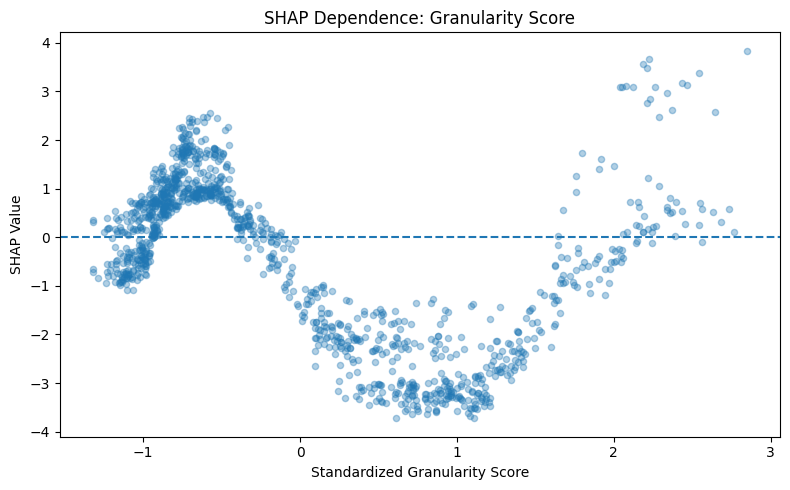

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(
    dependence_df["Granularity_Score"],
    dependence_df["SHAP_Value"],
    alpha=0.35,
    s=20
)

plt.axhline(0, linestyle="--")

plt.xlabel("Standardized Granularity Score")
plt.ylabel("SHAP Value")
plt.title("SHAP Dependence: Granularity Score")
plt.tight_layout()
plt.show()

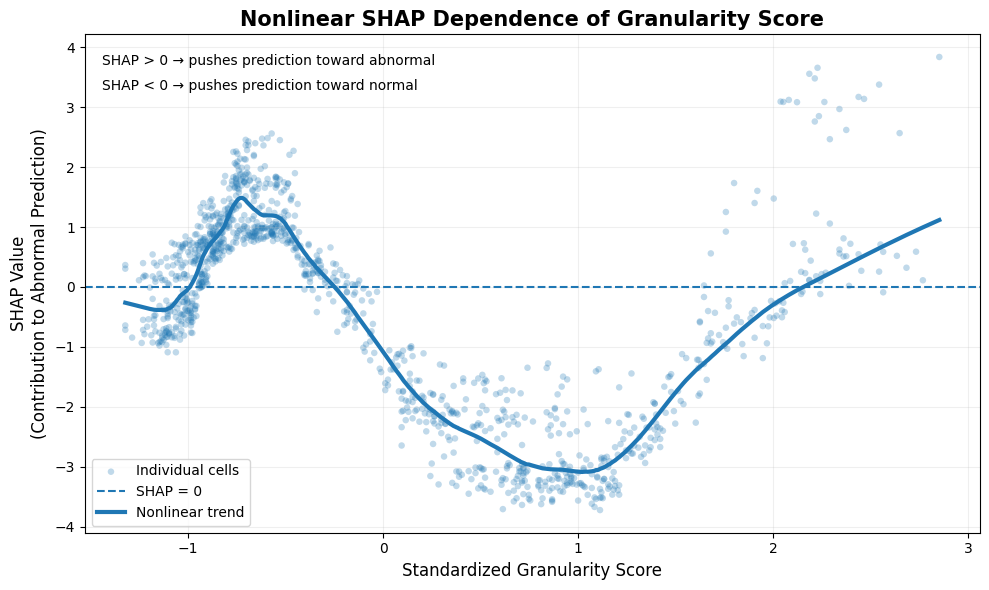

In [ ]:
# ============================================
# IMPROVED SHAP DEPENDENCE PLOT
# ============================================

import numpy as np
import matplotlib.pyplot as plt
from statsmodels.nonparametric.smoothers_lowess import lowess

# Extract values
x = dependence_df["Granularity_Score"].values
y = dependence_df["SHAP_Value"].values

# Remove missing values
mask = np.isfinite(x) & np.isfinite(y)
x = x[mask]
y = y[mask]

# Sort for smooth curve
order = np.argsort(x)
x_sorted = x[order]
y_sorted = y[order]

# LOWESS smooth trend
smooth = lowess(
    y_sorted,
    x_sorted,
    frac=0.12,
    return_sorted=True
)

# --------------------------------------------
# Plot
# --------------------------------------------

fig, ax = plt.subplots(figsize=(10, 6))

# Individual observations
ax.scatter(
    x,
    y,
    s=22,
    alpha=0.28,
    edgecolors="none",
    label="Individual cells"
)

# SHAP = 0 reference
ax.axhline(
    0,
    linestyle="--",
    linewidth=1.5,
    label="SHAP = 0"
)

# Smooth nonlinear trend
ax.plot(
    smooth[:, 0],
    smooth[:, 1],
    linewidth=3,
    label="Nonlinear trend"
)

# --------------------------------------------
# Labels
# --------------------------------------------

ax.set_xlabel(
    "Standardized Granularity Score",
    fontsize=12
)

ax.set_ylabel(
    "SHAP Value\n(Contribution to Abnormal Prediction)",
    fontsize=12
)

ax.set_title(
    "Nonlinear SHAP Dependence of Granularity Score",
    fontsize=15,
    fontweight="bold"
)

# --------------------------------------------
# Annotate SHAP interpretation
# --------------------------------------------

ax.text(
    0.02,
    0.96,
    "SHAP > 0 → pushes prediction toward abnormal",
    transform=ax.transAxes,
    fontsize=10,
    va="top"
)

ax.text(
    0.02,
    0.91,
    "SHAP < 0 → pushes prediction toward normal",
    transform=ax.transAxes,
    fontsize=10,
    va="top"
)

# Grid
ax.grid(
    axis="both",
    alpha=0.2
)

ax.legend(
    loc="best",
    frameon=True
)

plt.tight_layout()
plt.show()

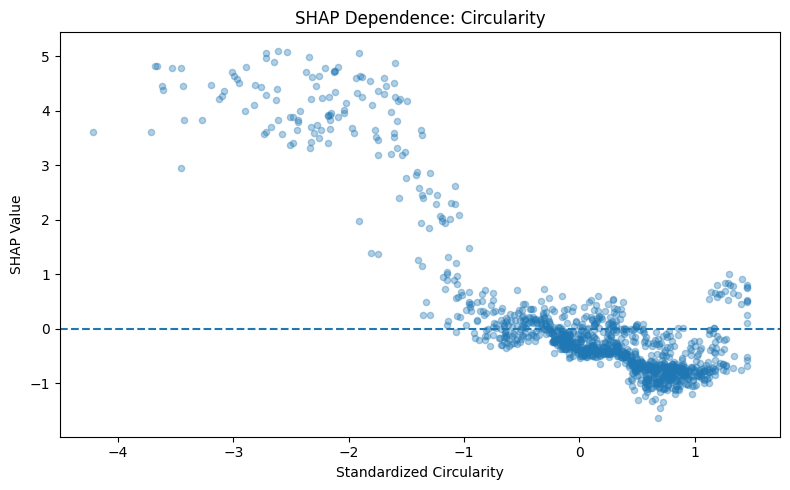

In [ ]:
# SHAP dependence data for circularity

feature_name = "num__circularity"
feature_idx = list(feature_names).index(feature_name)

circularity_df = pd.DataFrame({
    "Circularity": X_comb_test_p[:, feature_idx],
    "SHAP_Value": shap_values[:, feature_idx]
})

plt.figure(figsize=(8, 5))

plt.scatter(
    circularity_df["Circularity"],
    circularity_df["SHAP_Value"],
    alpha=0.35,
    s=20
)

plt.axhline(0, linestyle="--")

plt.xlabel("Standardized Circularity")
plt.ylabel("SHAP Value")
plt.title("SHAP Dependence: Circularity")
plt.tight_layout()
plt.show()

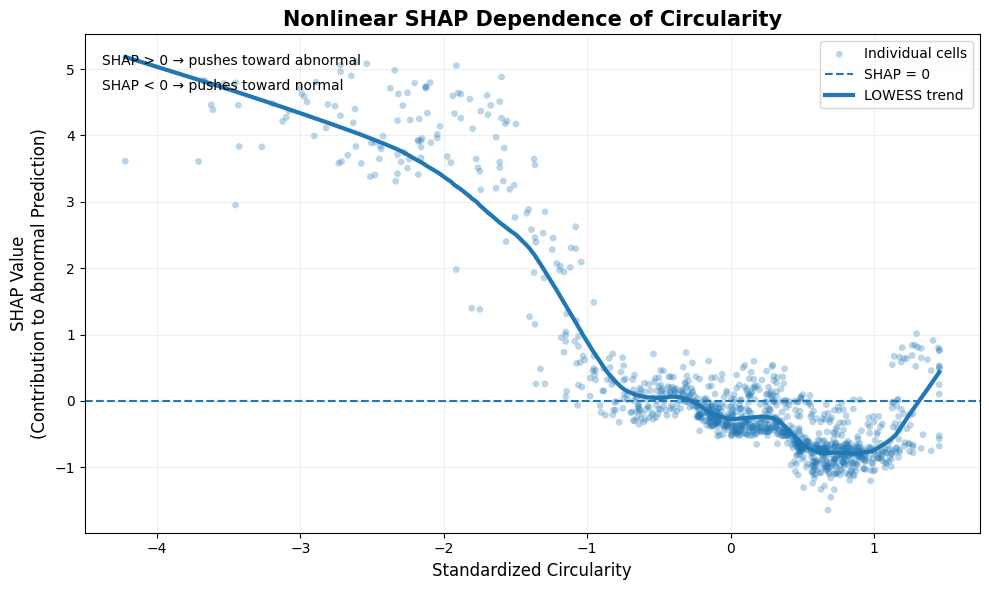

CIRCULARITY SHAP SUMMARY
------------------------
Number of cells     : 1176
Mean |SHAP|         : 0.8610
Mean SHAP           : 0.1471
Minimum SHAP        : -1.6432
Maximum SHAP        : 5.1024


In [ ]:
# ============================================
# IMPROVED SHAP DEPENDENCE: CIRCULARITY
# ============================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.nonparametric.smoothers_lowess import lowess

# --------------------------------------------
# Extract circularity SHAP values
# --------------------------------------------

feature_name = "num__circularity"
feature_idx = list(feature_names).index(feature_name)

circularity_df = pd.DataFrame({
    "Circularity": X_comb_test_p[:, feature_idx],
    "SHAP_Value": shap_values[:, feature_idx]
}).dropna()

x = circularity_df["Circularity"].values
y = circularity_df["SHAP_Value"].values

# --------------------------------------------
# LOWESS nonlinear trend
# --------------------------------------------

sort_idx = np.argsort(x)

x_sorted = x[sort_idx]
y_sorted = y[sort_idx]

smooth = lowess(
    y_sorted,
    x_sorted,
    frac=0.15,
    it=2,
    return_sorted=True
)

# --------------------------------------------
# Plot
# --------------------------------------------

fig, ax = plt.subplots(figsize=(10, 6))

# Individual observations
ax.scatter(
    x,
    y,
    s=24,
    alpha=0.30,
    edgecolors="none",
    label="Individual cells"
)

# SHAP = 0
ax.axhline(
    0,
    linestyle="--",
    linewidth=1.5,
    label="SHAP = 0"
)

# Nonlinear trend
ax.plot(
    smooth[:, 0],
    smooth[:, 1],
    linewidth=3,
    label="LOWESS trend"
)

# --------------------------------------------
# Labels
# --------------------------------------------

ax.set_xlabel(
    "Standardized Circularity",
    fontsize=12
)

ax.set_ylabel(
    "SHAP Value\n(Contribution to Abnormal Prediction)",
    fontsize=12
)

ax.set_title(
    "Nonlinear SHAP Dependence of Circularity",
    fontsize=15,
    fontweight="bold"
)

# --------------------------------------------
# Interpretation labels
# --------------------------------------------

ax.text(
    0.02,
    0.96,
    "SHAP > 0 → pushes toward abnormal",
    transform=ax.transAxes,
    fontsize=10,
    va="top"
)

ax.text(
    0.02,
    0.91,
    "SHAP < 0 → pushes toward normal",
    transform=ax.transAxes,
    fontsize=10,
    va="top"
)

# --------------------------------------------
# Grid and formatting
# --------------------------------------------

ax.grid(
    axis="both",
    alpha=0.20
)

ax.legend(
    loc="best",
    frameon=True
)

plt.tight_layout()
plt.show()

# --------------------------------------------
# Numerical summary
# --------------------------------------------

print("CIRCULARITY SHAP SUMMARY")
print("------------------------")
print(f"Number of cells     : {len(y)}")
print(f"Mean |SHAP|         : {np.mean(np.abs(y)):.4f}")
print(f"Mean SHAP           : {np.mean(y):.4f}")
print(f"Minimum SHAP        : {np.min(y):.4f}")
print(f"Maximum SHAP        : {np.max(y):.4f}")

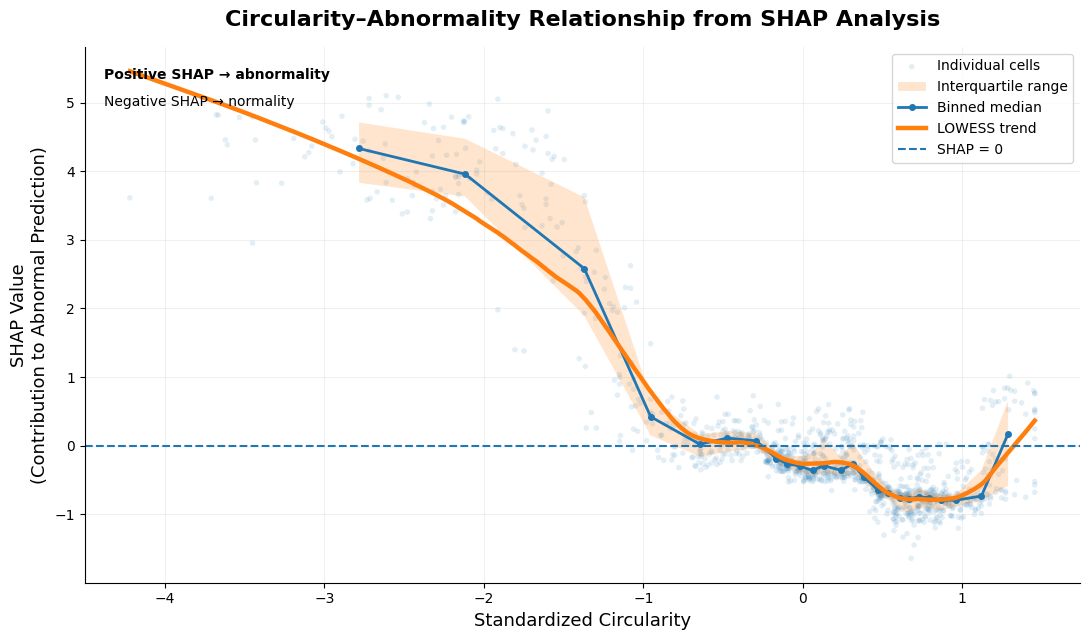

CIRCULARITY SHAP ANALYSIS
Number of cells : 1176
Mean |SHAP|    : 0.8610
Mean SHAP      : 0.1471
Median SHAP    : -0.2830


In [ ]:
# ============================================
# PUBLICATION-READY SHAP DEPENDENCE: CIRCULARITY
# ============================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.nonparametric.smoothers_lowess import lowess

# --------------------------------------------
# Extract SHAP dependence data
# --------------------------------------------

feature_name = "num__circularity"
feature_idx = list(feature_names).index(feature_name)

circularity_df = pd.DataFrame({
    "Circularity": X_comb_test_p[:, feature_idx],
    "SHAP_Value": shap_values[:, feature_idx]
}).dropna()

x = circularity_df["Circularity"].values
y = circularity_df["SHAP_Value"].values

# --------------------------------------------
# LOWESS trend
# --------------------------------------------

order = np.argsort(x)

lowess_result = lowess(
    y[order],
    x[order],
    frac=0.18,
    it=2,
    return_sorted=True
)

# --------------------------------------------
# Quantile bins
# --------------------------------------------

n_bins = 25

circularity_df["Bin"] = pd.qcut(
    circularity_df["Circularity"],
    q=n_bins,
    duplicates="drop"
)

binned = circularity_df.groupby(
    "Bin",
    observed=True
).agg(
    x_median=("Circularity", "median"),
    shap_median=("SHAP_Value", "median"),
    shap_q25=("SHAP_Value", lambda z: z.quantile(0.25)),
    shap_q75=("SHAP_Value", lambda z: z.quantile(0.75)),
    count=("SHAP_Value", "size")
).reset_index()

# --------------------------------------------
# Figure
# --------------------------------------------

fig, ax = plt.subplots(figsize=(11, 6.5))

# Faint individual observations
ax.scatter(
    x,
    y,
    s=16,
    alpha=0.12,
    edgecolors="none",
    label="Individual cells"
)

# IQR uncertainty band
ax.fill_between(
    binned["x_median"],
    binned["shap_q25"],
    binned["shap_q75"],
    alpha=0.20,
    label="Interquartile range"
)

# Binned median
ax.plot(
    binned["x_median"],
    binned["shap_median"],
    marker="o",
    markersize=4,
    linewidth=2,
    label="Binned median"
)

# LOWESS nonlinear trend
ax.plot(
    lowess_result[:, 0],
    lowess_result[:, 1],
    linewidth=3.2,
    label="LOWESS trend"
)

# SHAP = 0 reference
ax.axhline(
    0,
    linestyle="--",
    linewidth=1.5,
    label="SHAP = 0"
)

# --------------------------------------------
# Labels
# --------------------------------------------

ax.set_xlabel(
    "Standardized Circularity",
    fontsize=13
)

ax.set_ylabel(
    "SHAP Value\n(Contribution to Abnormal Prediction)",
    fontsize=13
)

ax.set_title(
    "Circularity–Abnormality Relationship from SHAP Analysis",
    fontsize=16,
    fontweight="bold",
    pad=15
)

# --------------------------------------------
# Interpretation regions
# --------------------------------------------

ymin, ymax = ax.get_ylim()

ax.text(
    0.02,
    0.94,
    "Positive SHAP → abnormality",
    transform=ax.transAxes,
    fontsize=10,
    fontweight="bold"
)

ax.text(
    0.02,
    0.89,
    "Negative SHAP → normality",
    transform=ax.transAxes,
    fontsize=10
)

# --------------------------------------------
# Grid / layout
# --------------------------------------------

ax.grid(
    True,
    alpha=0.18
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(
    loc="best",
    frameon=True
)

plt.tight_layout()
plt.show()

# --------------------------------------------
# Numerical summary
# --------------------------------------------

print("CIRCULARITY SHAP ANALYSIS")
print("=" * 35)

print(f"Number of cells : {len(y)}")
print(f"Mean |SHAP|    : {np.mean(np.abs(y)):.4f}")
print(f"Mean SHAP      : {np.mean(y):.4f}")
print(f"Median SHAP    : {np.median(y):.4f}")

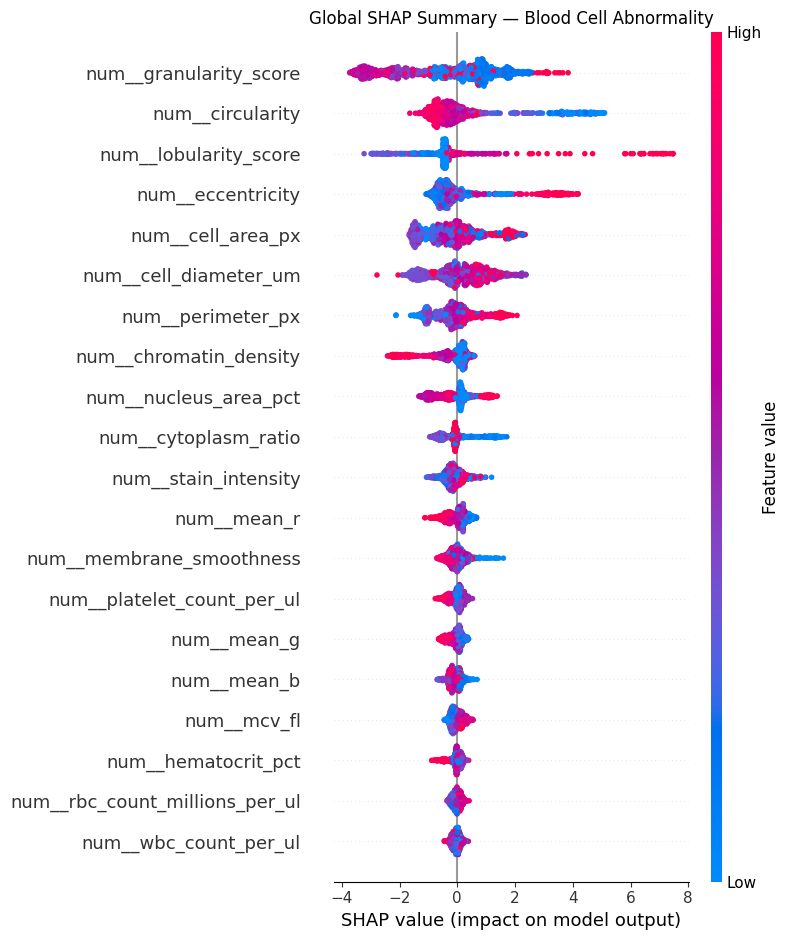

In [ ]:
# SHAP summary plot
plt.figure(figsize=(10, 7))

shap.summary_plot(
    shap_values,
    X_comb_test_p,
    feature_names=feature_names,
    max_display=20,
    show=False
)

plt.title("Global SHAP Summary — Blood Cell Abnormality")
plt.tight_layout()
plt.show()

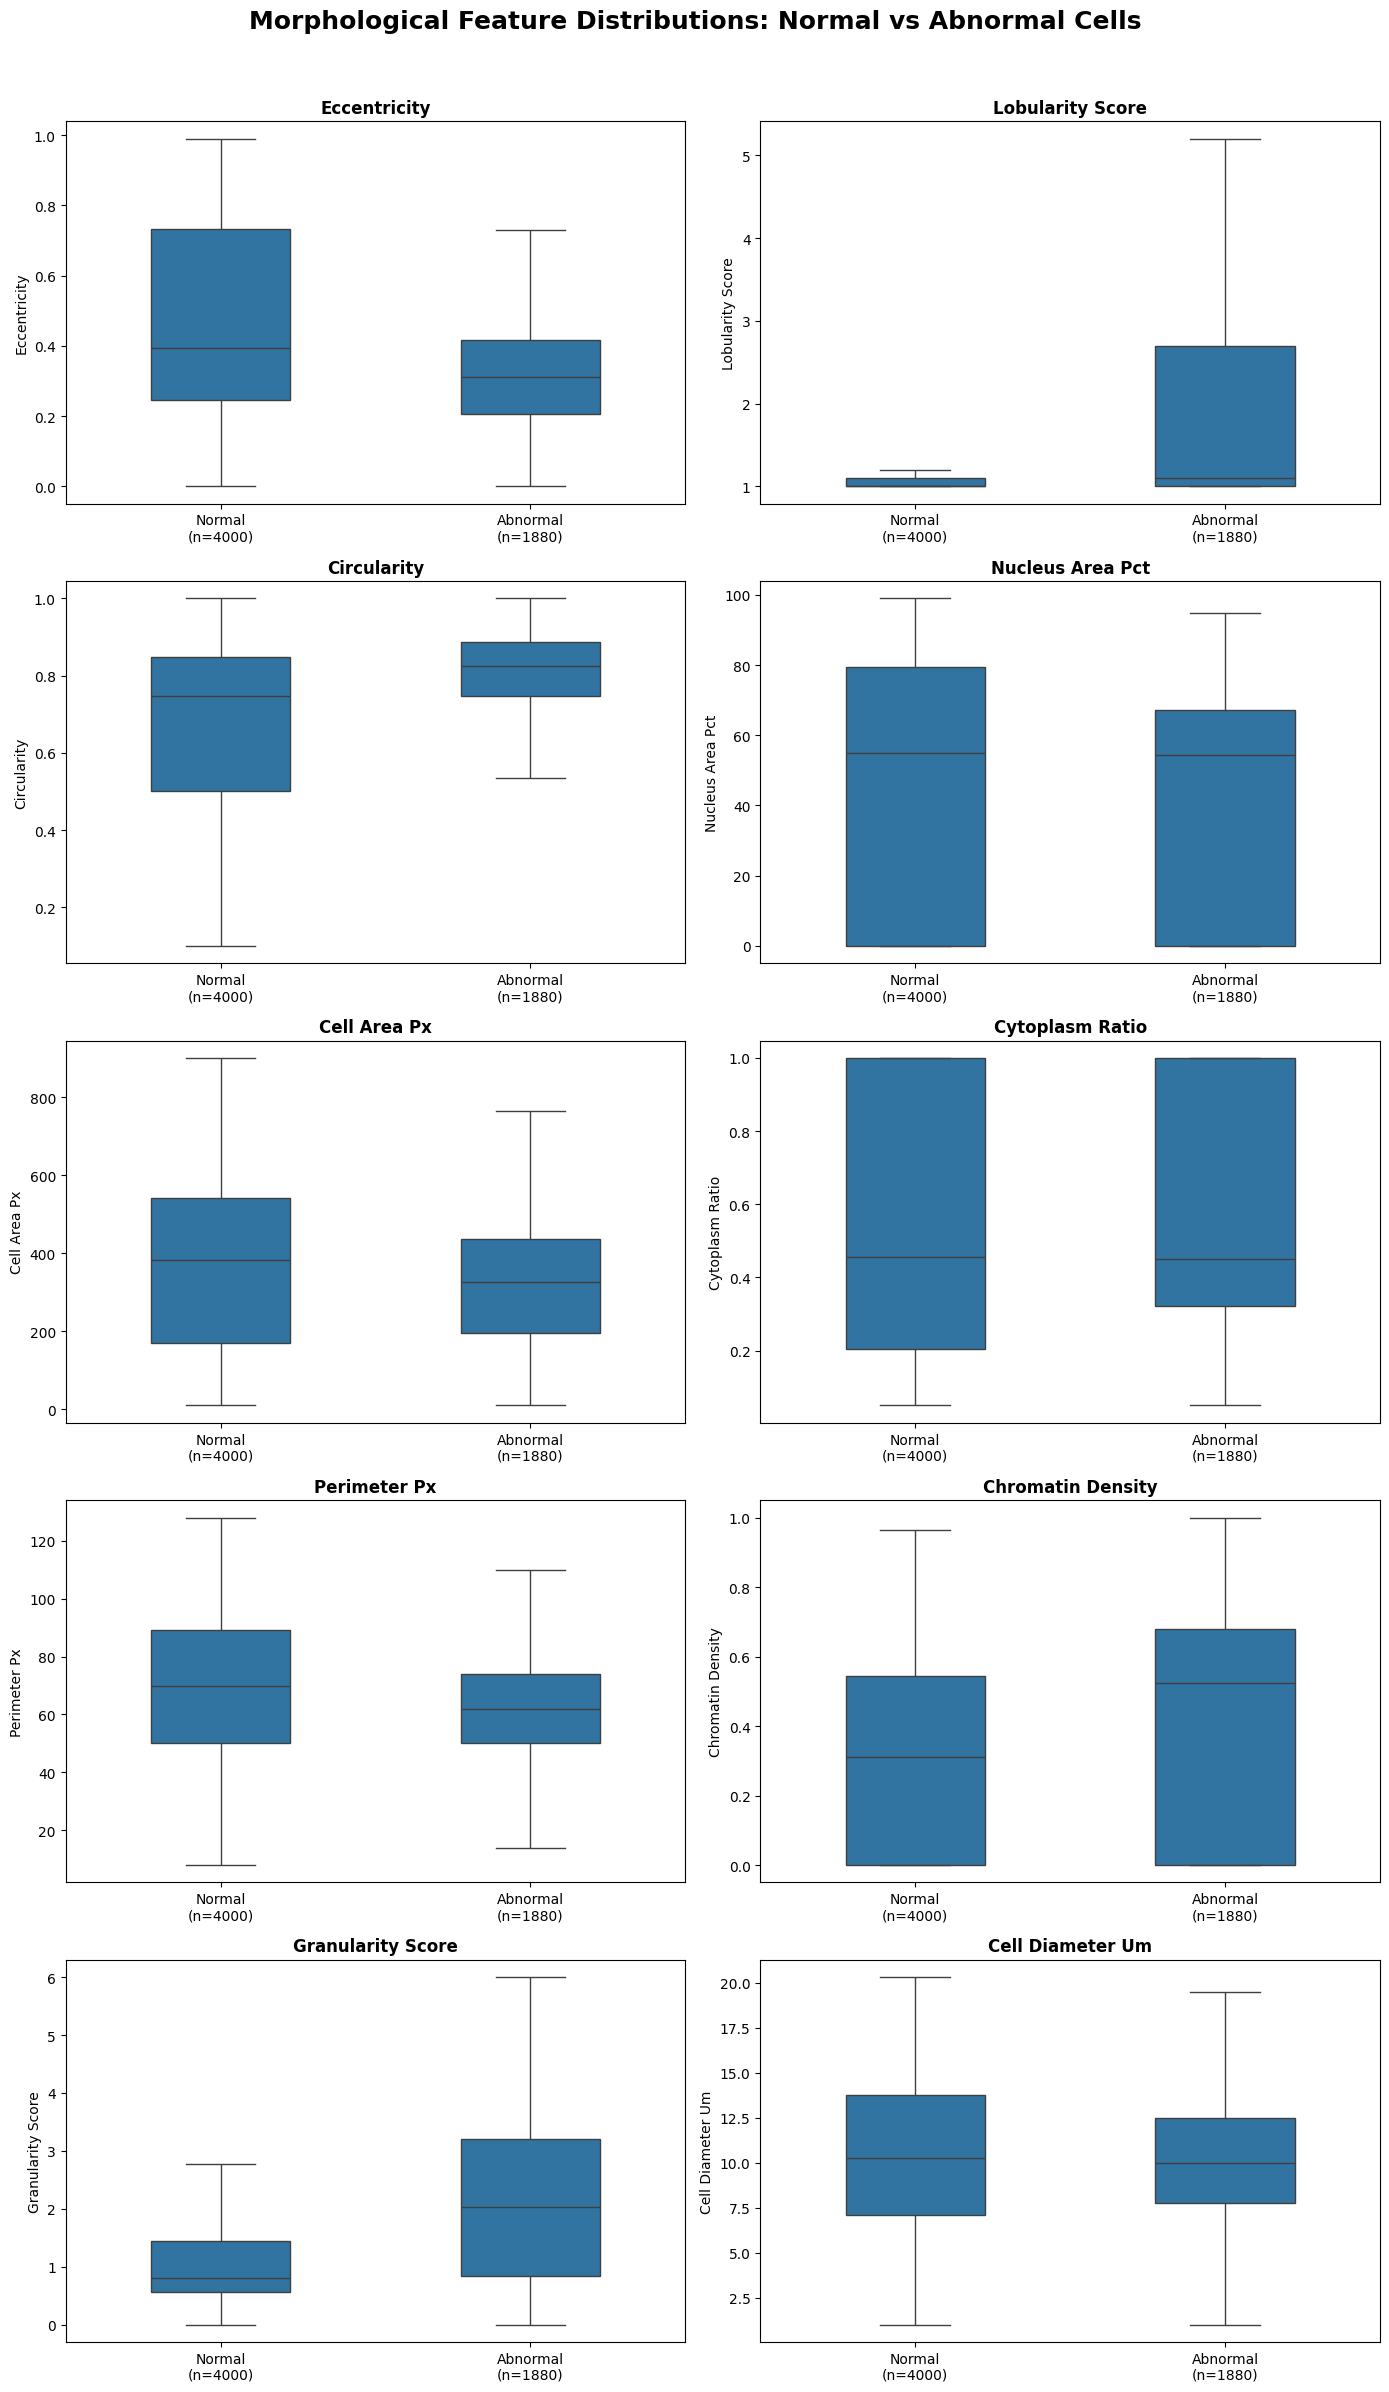

In [ ]:
# ============================================
# BOX PLOTS ONLY: NORMAL vs ABNORMAL
# SELF-CONTAINED VERSION
# ============================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --------------------------------------------
# Top morphological features
# --------------------------------------------

top_morphological_features = [
    "eccentricity",
    "lobularity_score",
    "circularity",
    "nucleus_area_pct",
    "cell_area_px",
    "cytoplasm_ratio",
    "perimeter_px",
    "chromatin_density",
    "granularity_score",
    "cell_diameter_um"
]

# --------------------------------------------
# Rebuild plotting dataframe
# --------------------------------------------

plot_df = blood_df[
    top_morphological_features + ["anomaly_label"]
].copy()

plot_df["Anomaly Status"] = plot_df["anomaly_label"].map({
    0: "Normal",
    1: "Abnormal"
})

# Remove missing values
plot_df = plot_df.dropna(
    subset=top_morphological_features + ["Anomaly Status"]
)

# Sample counts
n_normal = (plot_df["Anomaly Status"] == "Normal").sum()
n_abnormal = (plot_df["Anomaly Status"] == "Abnormal").sum()

# --------------------------------------------
# Create box plots
# --------------------------------------------

fig, axes = plt.subplots(
    5, 2,
    figsize=(14, 24)
)

axes = axes.flatten()

for i, feature in enumerate(top_morphological_features):

    ax = axes[i]

    sns.boxplot(
        data=plot_df,
        x="Anomaly Status",
        y=feature,
        width=0.45,
        showfliers=False,
        ax=ax
    )

    ax.set_title(
        feature.replace("_", " ").title(),
        fontsize=12,
        fontweight="bold"
    )

    ax.set_xlabel("")
    ax.set_ylabel(feature.replace("_", " ").title())

    ax.set_xticklabels([
        f"Normal\n(n={n_normal})",
        f"Abnormal\n(n={n_abnormal})"
    ])

# --------------------------------------------
# Overall title
# --------------------------------------------

plt.suptitle(
    "Morphological Feature Distributions: Normal vs Abnormal Cells",
    fontsize=18,
    fontweight="bold",
    y=0.995
)

plt.tight_layout(rect=[0, 0, 1, 0.98])

plt.show()

In [ ]:
# Analyze uncertainty around the training-derived threshold

uncertainty_df = blood_df.loc[test_idx].copy()

uncertainty_df["Abnormality_Score"] = abnormal_probability
uncertainty_df["True_Label"] = y_test.values

# Distance from the learned decision threshold
uncertainty_df["Distance_From_Threshold"] = abs(
    uncertainty_df["Abnormality_Score"] - optimal_threshold
)

# Most uncertain test samples
most_uncertain = uncertainty_df.sort_values(
    "Distance_From_Threshold"
).head(50)

print("MOST UNCERTAIN TEST SAMPLES")
print("==========================")
print(
    most_uncertain[
        [
            "cell_type",
            "disease_category",
            "Abnormality_Score",
            "True_Label",
            "Distance_From_Threshold"
        ]
    ].head(20)
)

MOST UNCERTAIN TEST SAMPLES
                      cell_type disease_category  Abnormality_Score  \
1026                Target_Cell           Anemia           0.789992   
4806          Toxic_Granulation        Infection           0.793294   
1732          Toxic_Granulation        Infection           0.769236   
2734  Hypersegmented_Neutrophil        Infection           0.827298   
2269                 Normal_RBC       Normal_RBC           0.748334   
2176        Reactive_Lymphocyte        Infection           0.837030   
2153                Target_Cell           Anemia           0.839937   
4735                 Spherocyte           Anemia           0.736513   
460                    Artefact         Artefact           0.862673   
2655  Hypersegmented_Neutrophil        Infection           0.863640   
4077          Toxic_Granulation        Infection           0.714423   
608                 Target_Cell           Anemia           0.870735   
1538          Toxic_Granulation        Infection 

In [ ]:
# Define uncertainty band around the learned threshold

uncertainty_band = uncertainty_df[
    uncertainty_df["Distance_From_Threshold"] <= 0.10
].copy()

print("UNCERTAINTY BAND")
print("================")
print("Threshold:", round(optimal_threshold, 4))
print("Band: ±0.10")
print("Total samples:", len(uncertainty_band))

print("\nTrue-label distribution:")
print(
    uncertainty_band["True_Label"]
    .value_counts()
    .sort_index()
)

print("\nCell-type distribution:")
display(
    uncertainty_band["cell_type"]
    .value_counts()
    .to_frame("Count")
)

print("\nDisease distribution:")
display(
    uncertainty_band["disease_category"]
    .value_counts()
    .to_frame("Count")
)

UNCERTAINTY BAND
Threshold: 0.7891
Band: ±0.10
Total samples: 16

True-label distribution:
True_Label
0     2
1    14
Name: count, dtype: int64

Cell-type distribution:


,Count
cell_type,
Toxic_Granulation,5
Target_Cell,3
Reactive_Lymphocyte,2
Hypersegmented_Neutrophil,2
Normal_RBC,1
Artefact,1
Eosinophil,1
Spherocyte,1



Disease distribution:


,Count
disease_category,
Infection,9
Anemia,4
Normal_RBC,1
Artefact,1
Normal_WBC,1


In [ ]:
# Compare error concentration inside vs outside uncertainty band

uncertainty_df["Needs_Review"] = (
    uncertainty_df["Distance_From_Threshold"] <= 0.10
)

uncertainty_df["Prediction"] = (
    uncertainty_df["Abnormality_Score"] >= optimal_threshold
).astype(int)

uncertainty_df["Correct"] = (
    uncertainty_df["Prediction"] == uncertainty_df["True_Label"]
)

review_summary = (
    uncertainty_df
    .groupby("Needs_Review")
    .agg(
        Samples=("Correct", "size"),
        Errors=("Correct", lambda x: (~x).sum()),
        Accuracy=("Correct", "mean")
    )
)

review_summary["Error_Rate"] = (
    1 - review_summary["Accuracy"]
)

review_summary["Sample_Percentage"] = (
    review_summary["Samples"] / len(uncertainty_df) * 100
)

print("REVIEW-PRIORITIZATION ANALYSIS")
print("==============================")
display(review_summary.round(4))

REVIEW-PRIORITIZATION ANALYSIS


,Samples,Errors,Accuracy,Error_Rate,Sample_Percentage
Needs_Review,,,,,
False,1160,30,0.9741,0.0259,98.6395
True,16,5,0.6875,0.3125,1.3605


In [ ]:
# Sensitivity analysis for uncertainty-band width

band_results = []

total_errors = (~uncertainty_df["Correct"]).sum()

for band in [0.05, 0.10, 0.15, 0.20]:

    mask = (
        uncertainty_df["Distance_From_Threshold"] <= band
    )

    subset = uncertainty_df[mask]

    errors = (~subset["Correct"]).sum()

    band_results.append({
        "Band_Width": band,
        "Flagged_Samples": len(subset),
        "Flagged_Percentage": len(subset) / len(uncertainty_df) * 100,
        "Errors_Captured": errors,
        "Error_Capture_Percentage": (
            errors / total_errors * 100
        ),
        "Error_Rate_Inside_Band": (
            errors / len(subset) * 100
            if len(subset) > 0 else 0
        )
    })

band_results_df = pd.DataFrame(band_results)

print("UNCERTAINTY BAND SENSITIVITY")
print("============================")
display(band_results_df.round(2))

UNCERTAINTY BAND SENSITIVITY


,Band_Width,Flagged_Samples,Flagged_Percentage,Errors_Captured,Error_Capture_Percentage,Error_Rate_Inside_Band
0,0.05,6,0.51,1,2.86,16.67
1,0.10,16,1.36,5,14.29,31.25
2,0.15,30,2.55,6,17.14,20.00
3,0.20,83,7.06,8,22.86,9.64


In [ ]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

# Use the combined model on the untouched test set
test_prob = combined_model.predict_proba(X_comb_test_p)[:, 1]

# Brier score
brier = brier_score_loss(y_test, test_prob)

# Calibration curve
prob_true, prob_pred = calibration_curve(
    y_test,
    test_prob,
    n_bins=10,
    strategy="quantile"
)

print("PROBABILITY CALIBRATION")
print("=======================")
print(f"Brier Score: {brier:.4f}")

print("\nCalibration bins:")
calibration_df = pd.DataFrame({
    "Mean_Predicted_Probability": prob_pred,
    "Observed_Abnormal_Rate": prob_true
})

display(calibration_df.round(4))

PROBABILITY CALIBRATION
Brier Score: 0.0165

Calibration bins:


,Mean_Predicted_Probability,Observed_Abnormal_Rate
0,0.0003,0.0000
1,0.0006,0.0000
2,0.0010,0.0000
3,0.0017,0.0000
4,0.0037,0.0000
5,0.0111,0.0085
6,0.1488,0.2137
7,0.9415,0.9746
8,0.9984,1.0000
9,0.9997,1.0000


In [ ]:
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

Shape: (5880, 36)

Columns:
['cell_id', 'cell_type', 'anomaly_label', 'disease_category', 'cell_diameter_um', 'nucleus_area_pct', 'chromatin_density', 'cytoplasm_ratio', 'circularity', 'eccentricity', 'granularity_score', 'lobularity_score', 'membrane_smoothness', 'cell_area_px', 'perimeter_px', 'mean_r', 'mean_g', 'mean_b', 'stain_intensity', 'patient_age_group', 'patient_sex', 'wbc_count_per_ul', 'rbc_count_millions_per_ul', 'hemoglobin_g_dl', 'hematocrit_pct', 'platelet_count_per_ul', 'mcv_fl', 'mchc_g_dl', 'dataset_source', 'staining_protocol', 'microscope_model', 'magnification_x', 'image_resolution_px', 'cytodiffusion_anomaly_score', 'cytodiffusion_classification_confidence', 'labeller_confidence_score']


In [ ]:
import pandas as pd

blood_df = pd.read_csv(
    "/content/blood_cell_dataset/blood_cell_anomaly_detection.csv"
)

print("Shape:", blood_df.shape)
print("\nColumns:")
print(blood_df.columns.tolist())

Shape: (5880, 36)

Columns:
['cell_id', 'cell_type', 'anomaly_label', 'disease_category', 'cell_diameter_um', 'nucleus_area_pct', 'chromatin_density', 'cytoplasm_ratio', 'circularity', 'eccentricity', 'granularity_score', 'lobularity_score', 'membrane_smoothness', 'cell_area_px', 'perimeter_px', 'mean_r', 'mean_g', 'mean_b', 'stain_intensity', 'patient_age_group', 'patient_sex', 'wbc_count_per_ul', 'rbc_count_millions_per_ul', 'hemoglobin_g_dl', 'hematocrit_pct', 'platelet_count_per_ul', 'mcv_fl', 'mchc_g_dl', 'dataset_source', 'staining_protocol', 'microscope_model', 'magnification_x', 'image_resolution_px', 'cytodiffusion_anomaly_score', 'cytodiffusion_classification_confidence', 'labeller_confidence_score']


In [ ]:
print([
    c for c in blood_df.columns
    if any(x in c.lower() for x in ["patient", "subject", "case", "sample", "record"])
])

['patient_age_group', 'patient_sex']


In [ ]:
print("Exact duplicate rows:", blood_df.duplicated().sum())
print("Duplicate cell IDs:", blood_df["cell_id"].duplicated().sum())

Exact duplicate rows: 0
Duplicate cell IDs: 0


In [ ]:
hema = [
    "wbc_count_per_ul",
    "rbc_count_millions_per_ul",
    "hemoglobin_g_dl",
    "hematocrit_pct",
    "platelet_count_per_ul",
    "mcv_fl",
    "mchc_g_dl"
]

for c in hema:
    print(c, "→ unique values:", blood_df[c].nunique())

wbc_count_per_ul → unique values: 4291
rbc_count_millions_per_ul → unique values: 434
hemoglobin_g_dl → unique values: 126
hematocrit_pct → unique values: 317
platelet_count_per_ul → unique values: 5818
mcv_fl → unique values: 523
mchc_g_dl → unique values: 96


In [ ]:
profile_counts = (
    blood_df.groupby(hema)
    .size()
    .sort_values(ascending=False)
)

print(profile_counts.head(20))

wbc_count_per_ul  rbc_count_millions_per_ul  hemoglobin_g_dl  hematocrit_pct  platelet_count_per_ul  mcv_fl  mchc_g_dl
16855             5.48                       14.9             36.5            406792                 89.6    33.7         1
1000              2.89                       12.9             48.0            275476                 72.8    31.7         1
                  3.30                       14.1             36.5            373012                 68.3    34.1         1
                  3.54                       12.0             51.2            273248                 88.4    34.1         1
                  3.66                       13.4             50.5            275612                 90.1    33.5         1
                  3.72                       13.5             56.9            280024                 95.4    32.9         1
                  3.94                       12.0             40.6            338607                 92.2    33.9         1
             

In [ ]:
print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

print("Index overlap:",
      len(set(X_train.index) & set(X_test.index)))

Train shape: (4704, 29)
Test shape: (1176, 29)
Index overlap: 0


In [ ]:
print(
    blood_df.groupby(
        ["patient_age_group", "patient_sex"]
    ).size().sort_values(ascending=False).head(20)
)

patient_age_group  patient_sex
Adult              F              1653
                   M              1623
Elderly            F               747
                   M               708
Pediatric          M               583
                   F               566
dtype: int64


In [ ]:
print(blood_df["cell_id"].head(20).tolist())

['CELL_005371', 'CELL_005300', 'CELL_000200', 'CELL_003269', 'CELL_003505', 'CELL_005586', 'CELL_002345', 'CELL_001612', 'CELL_005756', 'CELL_002202', 'CELL_001832', 'CELL_005361', 'CELL_003318', 'CELL_003746', 'CELL_002863', 'CELL_003930', 'CELL_001651', 'CELL_003280', 'CELL_004086', 'CELL_003690']


In [ ]:
print(blood_df["dataset_source"].value_counts())

dataset_source
PBC_Dataset    2351
Raabin_WBC     2089
CytoData       1440
Name: count, dtype: int64


In [ ]:
print(
    pd.crosstab(
        blood_df["dataset_source"],
        blood_df["anomaly_label"],
        normalize="index"
    ).round(3)
)

anomaly_label       0      1
dataset_source              
CytoData        0.692  0.308
PBC_Dataset     0.679  0.321
Raabin_WBC      0.674  0.326


In [ ]:
print(
    pd.crosstab(
        blood_df["dataset_source"],
        blood_df["disease_category"],
        normalize="index"
    ).round(3)
)

disease_category  Anemia  Artefact  Infection  Leukemia  Normal_Platelet  \
dataset_source                                                             
CytoData           0.103     0.030      0.077     0.070            0.058   
PBC_Dataset        0.111     0.031      0.079     0.077            0.050   
Raabin_WBC         0.115     0.031      0.074     0.085            0.047   

disease_category  Normal_RBC  Normal_WBC  Sickle_Cell_Anemia  
dataset_source                                                
CytoData               0.147       0.486               0.028  
PBC_Dataset            0.150       0.479               0.023  
Raabin_WBC             0.160       0.466               0.022  


In [ ]:
print(
    pd.crosstab(
        blood_df["staining_protocol"],
        blood_df["anomaly_label"],
        normalize="index"
    ).round(3)
)

anomaly_label            0      1
staining_protocol                
Giemsa               0.670  0.330
May_Grunwald_Giemsa  0.665  0.335
Wright               0.702  0.298


In [ ]:
print(
    pd.crosstab(
        blood_df["microscope_model"],
        blood_df["anomaly_label"],
        normalize="index"
    ).round(3)
)

anomaly_label         0      1
microscope_model              
Leica_DM2000      0.688  0.312
Olympus_BX51      0.671  0.329
Zeiss_Axio        0.685  0.315


In [ ]:
print("Magnification:")
print(blood_df["magnification_x"].value_counts().sort_index())

print("\nImage resolution:")
print(blood_df["image_resolution_px"].value_counts().sort_index())

Magnification:
magnification_x
40     1188
60     1745
100    2947
Name: count, dtype: int64

Image resolution:
image_resolution_px
224    1506
256    1473
360    1465
512    1436
Name: count, dtype: int64


In [ ]:
print(
    pd.crosstab(
        blood_df["magnification_x"],
        blood_df["anomaly_label"],
        normalize="index"
    ).round(3)
)

print("\nImage resolution:")
print(
    pd.crosstab(
        blood_df["image_resolution_px"],
        blood_df["anomaly_label"],
        normalize="index"
    ).round(3)
)

anomaly_label        0      1
magnification_x              
40               0.686  0.314
60               0.695  0.305
100              0.669  0.331

Image resolution:
anomaly_label            0      1
image_resolution_px              
224                  0.679  0.321
256                  0.683  0.317
360                  0.673  0.327
512                  0.686  0.314


In [ ]:
print(
    pd.crosstab(
        blood_df["cell_type"],
        blood_df["anomaly_label"],
        normalize="index"
    ).round(3)
)

anomaly_label                0    1
cell_type                          
Artefact                   0.0  1.0
Basophil                   1.0  0.0
Blast_Cell                 0.0  1.0
Elliptocyte                0.0  1.0
Eosinophil                 1.0  0.0
Hypersegmented_Neutrophil  0.0  1.0
Lymphocyte                 1.0  0.0
Monocyte                   1.0  0.0
Neutrophil                 1.0  0.0
Normal_RBC                 1.0  0.0
Platelet                   1.0  0.0
Prolymphocyte              0.0  1.0
Reactive_Lymphocyte        0.0  1.0
Schistocyte                0.0  1.0
Sickle_Cell                0.0  1.0
Smudge_Cell                0.0  1.0
Spherocyte                 0.0  1.0
Target_Cell                0.0  1.0
Toxic_Granulation          0.0  1.0


In [ ]:
print(
    pd.crosstab(
        blood_df["cell_type"],
        blood_df["disease_category"],
        normalize="index"
    ).round(3)
)

disease_category           Anemia  Artefact  Infection  Leukemia  \
cell_type                                                          
Artefact                      0.0       1.0        0.0       0.0   
Basophil                      0.0       0.0        0.0       0.0   
Blast_Cell                    0.0       0.0        0.0       1.0   
Elliptocyte                   1.0       0.0        0.0       0.0   
Eosinophil                    0.0       0.0        0.0       0.0   
Hypersegmented_Neutrophil     0.0       0.0        1.0       0.0   
Lymphocyte                    0.0       0.0        0.0       0.0   
Monocyte                      0.0       0.0        0.0       0.0   
Neutrophil                    0.0       0.0        0.0       0.0   
Normal_RBC                    0.0       0.0        0.0       0.0   
Platelet                      0.0       0.0        0.0       0.0   
Prolymphocyte                 0.0       0.0        0.0       1.0   
Reactive_Lymphocyte           0.0       0.0     

In [ ]:
morph_cols = [
    "cell_diameter_um",
    "nucleus_area_pct",
    "chromatin_density",
    "cytoplasm_ratio",
    "circularity",
    "eccentricity",
    "granularity_score",
    "lobularity_score",
    "membrane_smoothness",
    "cell_area_px",
    "perimeter_px",
    "mean_r",
    "mean_g",
    "mean_b",
    "stain_intensity"
]

print("Morphology features:", len(morph_cols))

print(
    blood_df[morph_cols]
    .describe()
    .T[["mean", "std", "min", "max"]]
)

Morphology features: 15
                           mean         std      min     max
cell_diameter_um      10.176267    3.642051    1.000   21.18
nucleus_area_pct      43.537976   33.419390    0.000   99.00
chromatin_density      0.391394    0.310006    0.000    1.00
cytoplasm_ratio        0.564173    0.335282    0.050    1.00
circularity            0.769263    0.158219    0.100    1.00
eccentricity           0.365458    0.201501    0.000    0.99
granularity_score      1.882109    1.428336    0.000    6.00
lobularity_score       1.769252    1.229362    1.000    7.20
membrane_smoothness    0.842866    0.096033    0.290    1.00
cell_area_px         336.571088  175.059021   10.000  901.00
perimeter_px          64.068878   21.290605    8.000  128.00
mean_r               212.119218   19.190629  123.000  255.00
mean_g               146.392687   18.836691   89.000  218.00
mean_b               168.664966   30.619209   94.000  244.00
stain_intensity        0.616362    0.109240    0.307    1.00


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from xgboost import XGBClassifier

X = blood_df[morph_cols]
y = LabelEncoder().fit_transform(blood_df["cell_type"])

Xtr, Xte, ytr, yte = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="mlogloss"
)

model.fit(Xtr, ytr)

pred = model.predict(Xte)

print("Cell-type prediction accuracy:",
      round(accuracy_score(yte, pred), 4))

print("Balanced accuracy:",
      round(balanced_accuracy_score(yte, pred), 4))

Cell-type prediction accuracy: 0.9609
Balanced accuracy: 0.9349


In [ ]:
X = blood_df[morph_cols]
y = LabelEncoder().fit_transform(blood_df["disease_category"])

Xtr, Xte, ytr, yte = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="mlogloss"
)

model.fit(Xtr, ytr)
pred = model.predict(Xte)

print("Disease prediction accuracy:",
      round(accuracy_score(yte, pred), 4))

print("Balanced accuracy:",
      round(balanced_accuracy_score(yte, pred), 4))

Disease prediction accuracy: 0.9677
Balanced accuracy: 0.9505


In [ ]:
print([
    x for x in globals()
    if any(k in x.lower() for k in ["cluster", "hdb", "phenotype", "label"])
])

['phenotype_df', 'assign_phenotype', 'HDBSCAN', 'phenotype_features', 'phenotype_X', 'phenotype_scaler', 'phenotype_scaled', 'hdbscan_model', 'phenotype_clusters', 'phenotype_results', 'clustered', 'cluster_celltype', 'cluster_disease', 'labels', 'cluster_score_summary', 'clusters', 'cluster_abnormality', 'morph_cluster_features', 'morph_hdbscan', 'morph_clusters', 'morph_clustered', 'hema_cluster_features', 'hema_hdbscan', 'hema_clusters', 'hema_clustered', 'cluster_analysis', 'hema_by_cluster', 'LabelEncoder']


In [ ]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

mask = phenotype_clusters != -1

print("Usable samples:", mask.sum())

print(
    "Cell-type ARI:",
    round(
        adjusted_rand_score(
            blood_df.loc[mask, "cell_type"],
            phenotype_clusters[mask]
        ), 4
    )
)

print(
    "Cell-type NMI:",
    round(
        normalized_mutual_info_score(
            blood_df.loc[mask, "cell_type"],
            phenotype_clusters[mask]
        ), 4
    )
)

Usable samples: 5119
Cell-type ARI: 0.2013
Cell-type NMI: 0.5042


In [ ]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

print(
    "Disease-category ARI:",
    round(
        adjusted_rand_score(
            blood_df.loc[mask, "disease_category"],
            phenotype_clusters[mask]
        ), 4
    )
)

print(
    "Disease-category NMI:",
    round(
        normalized_mutual_info_score(
            blood_df.loc[mask, "disease_category"],
            phenotype_clusters[mask]
        ), 4
    )
)

Disease-category ARI: 0.5791
Disease-category NMI: 0.6769


In [ ]:
within_type = (
    blood_df.loc[mask, ["cell_type"]]
    .assign(cluster=phenotype_clusters[mask])
    .groupby("cell_type")["cluster"]
    .nunique()
    .sort_values(ascending=False)
)

print(within_type)

cell_type
Schistocyte                  2
Basophil                     1
Blast_Cell                   1
Elliptocyte                  1
Hypersegmented_Neutrophil    1
Eosinophil                   1
Monocyte                     1
Neutrophil                   1
Normal_RBC                   1
Lymphocyte                   1
Platelet                     1
Prolymphocyte                1
Reactive_Lymphocyte          1
Sickle_Cell                  1
Smudge_Cell                  1
Spherocyte                   1
Target_Cell                  1
Toxic_Granulation            1
Name: cluster, dtype: int64


In [ ]:
sch = blood_df.loc[
    mask & (blood_df["cell_type"] == "Schistocyte")
].copy()

sch["cluster"] = phenotype_clusters[mask][
    blood_df.loc[mask, "cell_type"].values == "Schistocyte"
]

print(sch["cluster"].value_counts())

print(
    sch.groupby("cluster")[morph_cols]
       .mean()
       .round(3)
)

cluster
2    68
1     1
Name: count, dtype: int64
         cell_diameter_um  nucleus_area_pct  chromatin_density  \
cluster                                                          
1                   3.740               0.0                0.0   
2                   4.232               0.0                0.0   

         cytoplasm_ratio  circularity  eccentricity  granularity_score  \
cluster                                                                  
1                    1.0        0.592         0.724              0.830   
2                    1.0        0.430         0.820              0.592   

         lobularity_score  membrane_smoothness  cell_area_px  perimeter_px  \
cluster                                                                      
1                     1.0                0.691        92.000        42.000   
2                     1.0                0.723        78.324        36.235   

          mean_r   mean_g   mean_b  stain_intensity  
cluster              

In [ ]:
print(cluster_score_summary)

                   count    mean  median     std
phenotype_cluster                               
0                    711  0.2274  0.0022  0.4041
1                     26  0.0125  0.0011  0.0531
2                     51  0.9995  0.9998  0.0007
3                    232  0.2268  0.0141  0.3716


In [ ]:
print(cluster_score_summary.columns)

Index(['count', 'mean', 'median', 'std'], dtype='object')


In [ ]:
print(cluster_score_summary.columns)

Index(['count', 'mean', 'median', 'std'], dtype='object')


In [ ]:
print(cluster_analysis)

          cell_id                  cell_type  anomaly_label disease_category  \
0     CELL_005371  Hypersegmented_Neutrophil              1        Infection   
1     CELL_005300  Hypersegmented_Neutrophil              1        Infection   
2     CELL_000200                 Neutrophil              0       Normal_WBC   
3     CELL_003269                 Normal_RBC              0       Normal_RBC   
4     CELL_003505                 Normal_RBC              0       Normal_RBC   
...           ...                        ...            ...              ...   
5875  CELL_003773                   Platelet              0  Normal_Platelet   
5876  CELL_005192                Target_Cell              1           Anemia   
5877  CELL_005227                Target_Cell              1           Anemia   
5878  CELL_005391  Hypersegmented_Neutrophil              1        Infection   
5879  CELL_000861                 Neutrophil              0       Normal_WBC   

      cell_diameter_um  nucleus_area_pc

===== SUMMARY STATISTICS =====


eccentricity                   lobularity_score         \
                       mean  median       std             mean median   
Anomaly Status                                                          
Abnormal           0.465233  0.3945  0.269873           1.6300    1.0   
Normal             0.318564  0.3110  0.136345           1.8347    1.1   

                         circularity                  nucleus_area_pct  ...  \
                     std        mean median       std             mean  ...   
Anomaly Status                                                          ...   
Abnormal        1.430960    0.679954  0.748  0.214771        41.361117  ...   
Normal          1.116384    0.811239  0.824  0.098063        44.561100  ...   

               perimeter_px chromatin_density                   \
                        std              mean median       std   
Anomaly Status                                                   
Abnormal          23.732992          0.290110  0.311  0.278616   
Normal            19.432206          0.438998  0.524  0.312601   

               granularity_score                  cell_diameter_um          \
                            mean median       std             mean  median   
Anomaly Status                                                               
Abnormal                1.325234  0.810  1.277805        10.359266  10.245   
Normal                  2.143840  2.035  1.420476        10.090257  10.010   

                          
                     std  
Anomaly Status            
Abnormal        3.951398  
Normal          3.484392  

[2 rows x 30 columns]


===== STATISTICAL COMPARISON =====


,Feature,Normal Median,Abnormal Median,Median Difference,Cliffs Delta,P-value,Adjusted P-value,Effect Interpretation
8,granularity_score,2.035,0.8100,-1.2250,-0.3582,0.0000,0.0000,Medium
2,circularity,0.824,0.7480,-0.0760,-0.3317,0.0000,0.0000,Medium
7,chromatin_density,0.524,0.3110,-0.2130,-0.2831,0.0000,0.0000,Small
0,eccentricity,0.311,0.3945,0.0835,0.2756,0.0000,0.0000,Small
1,lobularity_score,1.100,1.0000,-0.1000,-0.1988,0.0000,0.0000,Small
6,perimeter_px,62.000,70.0000,8.0000,0.1895,0.0000,0.0000,Small
4,cell_area_px,327.000,382.5000,55.5000,0.0748,0.0000,0.0000,Negligible
3,nucleus_area_pct,54.500,54.8000,0.3000,0.0310,0.0503,0.5030,Negligible
9,cell_diameter_um,10.010,10.2450,0.2350,0.0295,0.0677,0.6774,Negligible
5,cytoplasm_ratio,0.451,0.4560,0.0050,-0.0294,0.0634,0.6337,Negligible


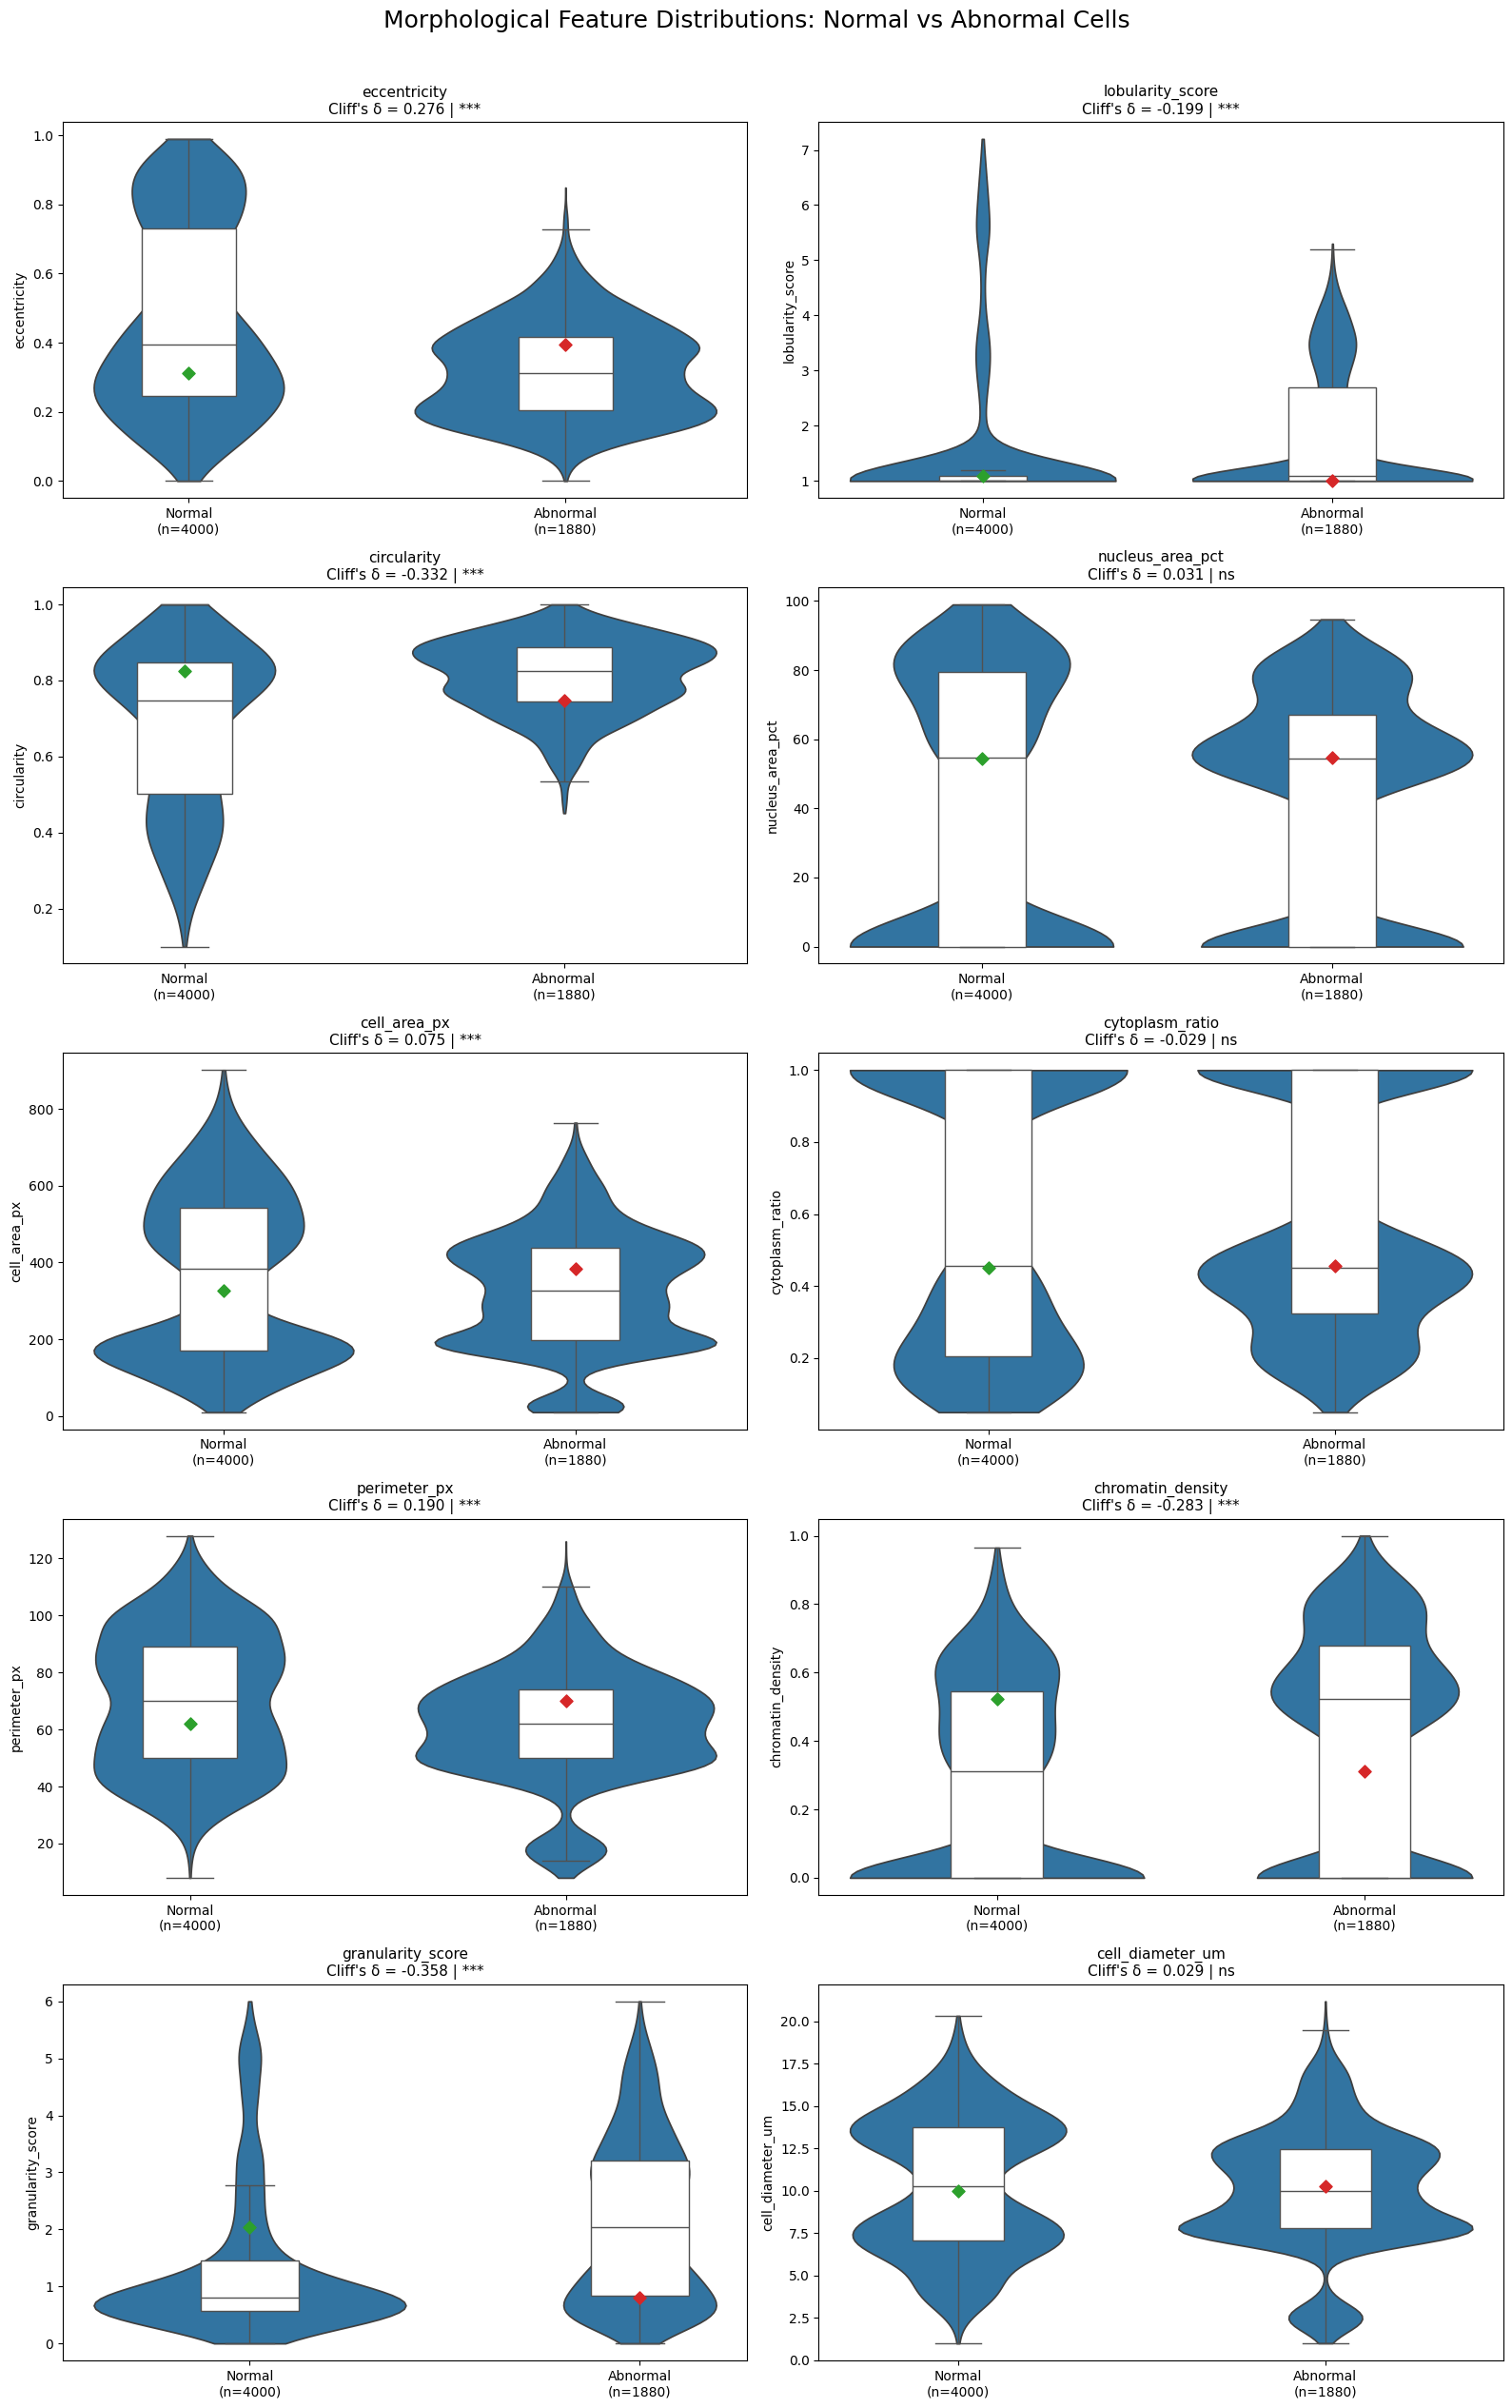

In [ ]:
# ============================================
# CELL 17: FEATURE DISTRIBUTION + STATISTICAL ANALYSIS
# ============================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import mannwhitneyu

# --------------------------------------------
# Top morphological features from XGBoost
# --------------------------------------------

top_morphological_features = [
    "eccentricity",
    "lobularity_score",
    "circularity",
    "nucleus_area_pct",
    "cell_area_px",
    "cytoplasm_ratio",
    "perimeter_px",
    "chromatin_density",
    "granularity_score",
    "cell_diameter_um"
]

# --------------------------------------------
# Create analysis dataframe
# --------------------------------------------

analysis_df = blood_df[
    top_morphological_features + ["anomaly_label"]
].copy()

analysis_df["Anomaly Status"] = analysis_df["anomaly_label"].map({
    0: "Normal",
    1: "Abnormal"
})

# --------------------------------------------
# 1. Summary statistics
# --------------------------------------------

summary = (
    analysis_df
    .groupby("Anomaly Status")[top_morphological_features]
    .agg(["mean", "median", "std"])
)

print("===== SUMMARY STATISTICS =====")
display(summary)

# --------------------------------------------
# 2. Statistical significance + effect size
# --------------------------------------------

results = []

normal = analysis_df[
    analysis_df["Anomaly Status"] == "Normal"
]

abnormal = analysis_df[
    analysis_df["Anomaly Status"] == "Abnormal"
]

for feature in top_morphological_features:

    normal_values = normal[feature].dropna().values
    abnormal_values = abnormal[feature].dropna().values

    # Mann-Whitney U test
    u_stat, p_value = mannwhitneyu(
        normal_values,
        abnormal_values,
        alternative="two-sided"
    )

    # Cliff's Delta
    # Positive = abnormal values tend to be larger
    # Negative = abnormal values tend to be smaller

    n1 = len(abnormal_values)
    n2 = len(normal_values)

    greater = np.sum(
        abnormal_values[:, None] > normal_values[None, :]
    )

    less = np.sum(
        abnormal_values[:, None] < normal_values[None, :]
    )

    cliffs_delta = (greater - less) / (n1 * n2)

    # Median difference
    median_normal = np.median(normal_values)
    median_abnormal = np.median(abnormal_values)

    results.append({
        "Feature": feature,
        "Normal Median": median_normal,
        "Abnormal Median": median_abnormal,
        "Median Difference": median_abnormal - median_normal,
        "Cliffs Delta": cliffs_delta,
        "P-value": p_value
    })

stats_results = pd.DataFrame(results)

# Multiple-testing correction using Bonferroni
stats_results["Adjusted P-value"] = np.minimum(
    stats_results["P-value"] * len(top_morphological_features),
    1.0
)

# Effect-size interpretation
def interpret_effect(delta):

    magnitude = abs(delta)

    if magnitude < 0.147:
        return "Negligible"
    elif magnitude < 0.33:
        return "Small"
    elif magnitude < 0.474:
        return "Medium"
    else:
        return "Large"

stats_results["Effect Interpretation"] = (
    stats_results["Cliffs Delta"]
    .apply(interpret_effect)
)

# Sort by absolute effect size
stats_results["Abs Effect"] = (
    stats_results["Cliffs Delta"].abs()
)

stats_results = (
    stats_results
    .sort_values("Abs Effect", ascending=False)
    .drop(columns="Abs Effect")
)

print("\n===== STATISTICAL COMPARISON =====")
display(stats_results.round(4))

# --------------------------------------------
# 3. Improved distribution plots
# --------------------------------------------

fig, axes = plt.subplots(
    5, 2,
    figsize=(16, 25)
)

axes = axes.flatten()

for i, feature in enumerate(top_morphological_features):

    ax = axes[i]

    # Violin plot
    sns.violinplot(
        data=analysis_df,
        x="Anomaly Status",
        y=feature,
        inner=None,
        cut=0,
        ax=ax
    )

    # Boxplot on top
    sns.boxplot(
        data=analysis_df,
        x="Anomaly Status",
        y=feature,
        width=0.25,
        showfliers=False,
        boxprops={"facecolor": "white"},
        ax=ax
    )

    # Median values
    medians = analysis_df.groupby(
        "Anomaly Status"
    )[feature].median()

    for j, status in enumerate(["Normal", "Abnormal"]):

        ax.scatter(
            j,
            medians[status],
            marker="D",
            s=45,
            zorder=5
        )

    # Get statistics for this feature
    row = stats_results[
        stats_results["Feature"] == feature
    ].iloc[0]

    # Significance label
    if row["Adjusted P-value"] < 0.001:
        significance = "***"
    elif row["Adjusted P-value"] < 0.01:
        significance = "**"
    elif row["Adjusted P-value"] < 0.05:
        significance = "*"
    else:
        significance = "ns"

    ax.set_title(
        f"{feature}\n"
        f"Cliff's δ = {row['Cliffs Delta']:.3f} | "
        f"{significance}",
        fontsize=11
    )

    ax.set_xlabel("")

    ax.set_ylabel(feature)

    # Sample counts
    n_normal = len(normal)
    n_abnormal = len(abnormal)

    ax.set_xticklabels([
        f"Normal\n(n={n_normal})",
        f"Abnormal\n(n={n_abnormal})"
    ])

plt.suptitle(
    "Morphological Feature Distributions: Normal vs Abnormal Cells",
    fontsize=18,
    y=1.01
)

plt.tight_layout()
plt.show()

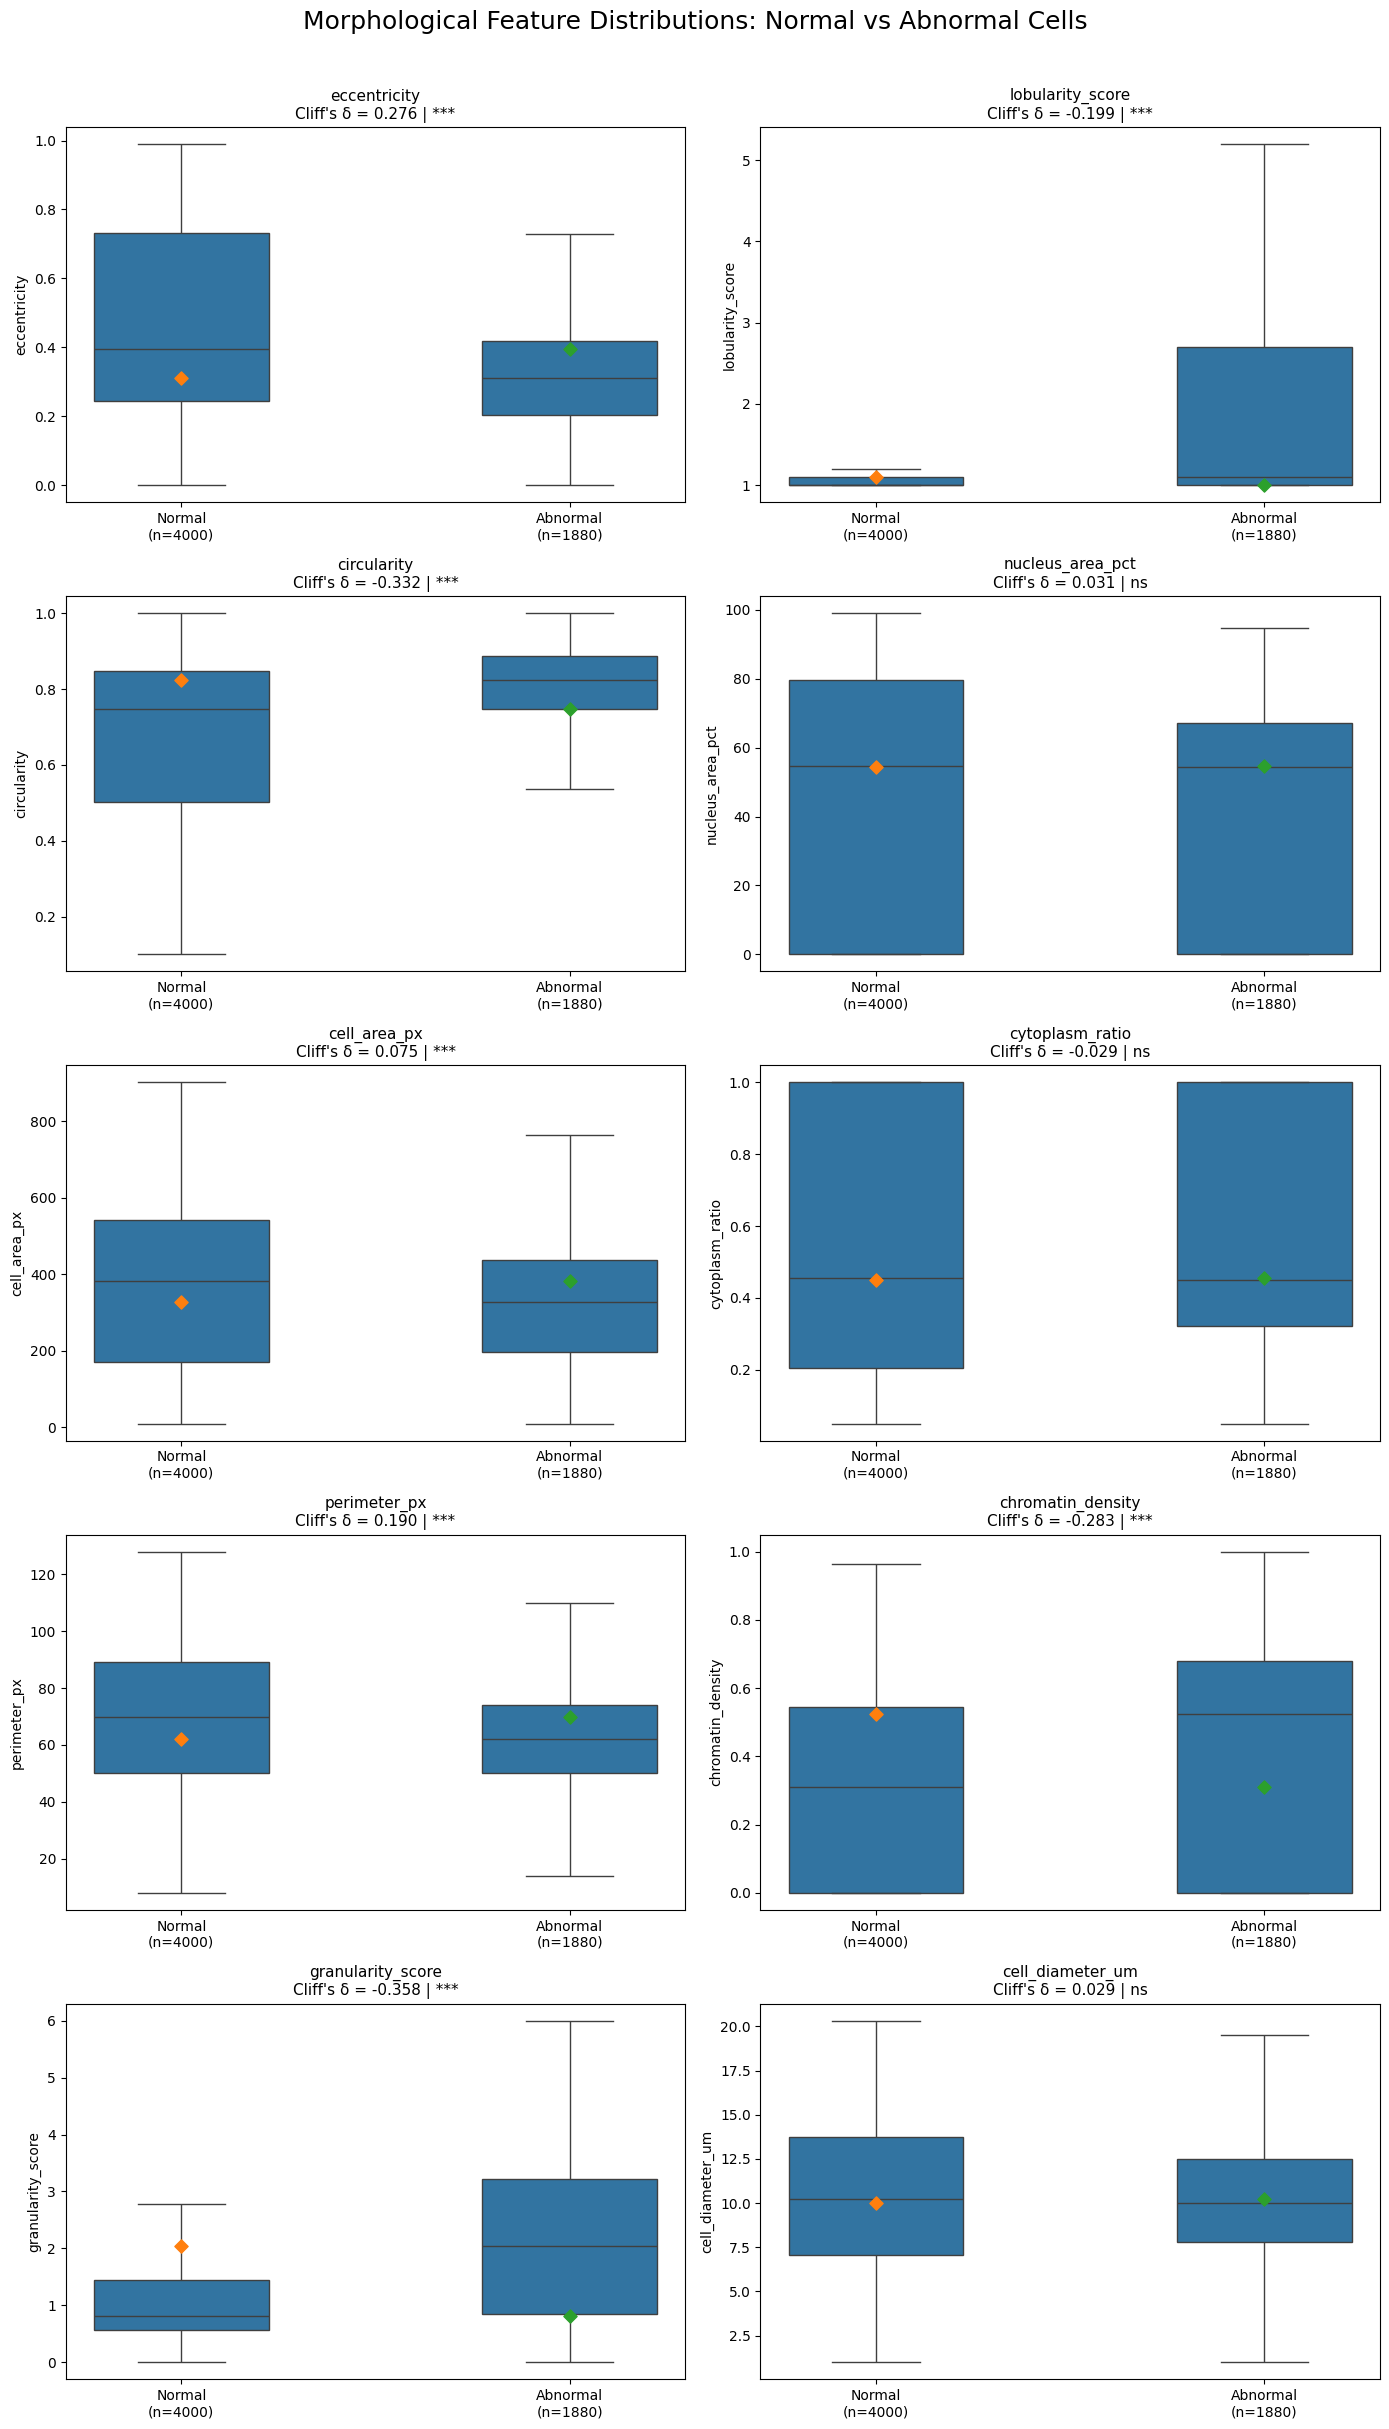

In [ ]:
# --------------------------------------------
# 3. Box plots only
# --------------------------------------------

fig, axes = plt.subplots(
    5, 2,
    figsize=(14, 24)
)

axes = axes.flatten()

for i, feature in enumerate(top_morphological_features):

    ax = axes[i]

    sns.boxplot(
        data=analysis_df,
        x="Anomaly Status",
        y=feature,
        width=0.45,
        showfliers=False,
        ax=ax
    )

    # Median values
    medians = analysis_df.groupby(
        "Anomaly Status"
    )[feature].median()

    # Mark median
    for j, status in enumerate(["Normal", "Abnormal"]):

        ax.scatter(
            j,
            medians[status],
            marker="D",
            s=45,
            zorder=5
        )

    # Get statistics
    row = stats_results[
        stats_results["Feature"] == feature
    ].iloc[0]

    # Significance label
    if row["Adjusted P-value"] < 0.001:
        significance = "***"
    elif row["Adjusted P-value"] < 0.01:
        significance = "**"
    elif row["Adjusted P-value"] < 0.05:
        significance = "*"
    else:
        significance = "ns"

    ax.set_title(
        f"{feature}\n"
        f"Cliff's δ = {row['Cliffs Delta']:.3f} | "
        f"{significance}",
        fontsize=11
    )

    ax.set_xlabel("")

    ax.set_ylabel(feature)

    # Sample counts
    ax.set_xticklabels([
        f"Normal\n(n={len(normal)})",
        f"Abnormal\n(n={len(abnormal)})"
    ])

plt.suptitle(
    "Morphological Feature Distributions: Normal vs Abnormal Cells",
    fontsize=18,
    y=1.01
)

plt.tight_layout()
plt.show()

PHENOTYPE REVIEW SUMMARY


,Cells,Percentage
Phenotype_Status,,
Normal,828,70.41
Uncertain,16,1.36
Abnormal,332,28.23


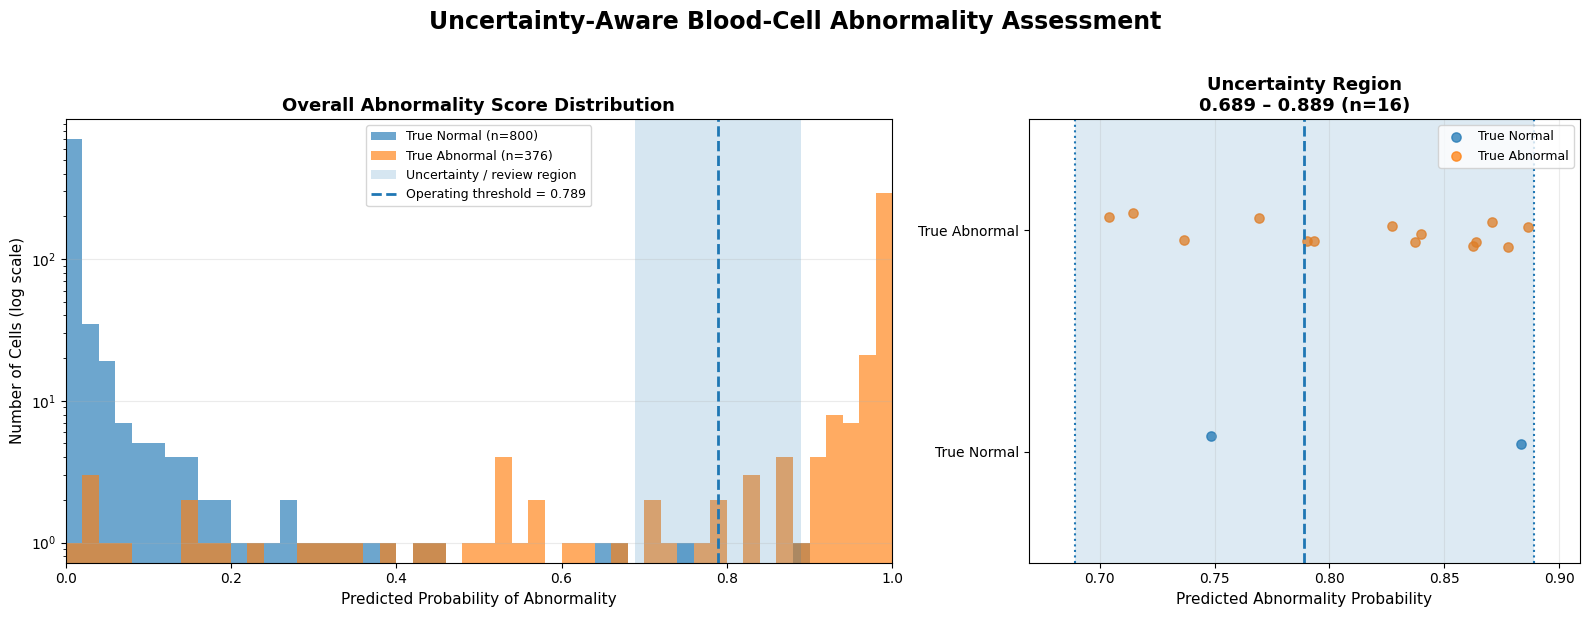


UNCERTAINTY REVIEW
Review candidates: 16 (1.36%)
True abnormal: 14
True normal: 2


In [ ]:
# ============================================
# CELL 18: UNCERTAINTY-AWARE ABNORMALITY SCORE
# ============================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --------------------------------------------
# 1. Predicted abnormality probability
# --------------------------------------------

abnormal_probability = xgb_model.predict_proba(
    X_test_processed
)[:, 1]

phenotype_df = X_test.copy()

phenotype_df["True_Label"] = y_test_anomaly.values
phenotype_df["Abnormality_Score"] = abnormal_probability

# --------------------------------------------
# 2. Training-derived operating threshold
# --------------------------------------------

operating_threshold = 0.7891
uncertainty_margin = 0.10

lower_threshold = operating_threshold - uncertainty_margin
upper_threshold = operating_threshold + uncertainty_margin

# --------------------------------------------
# 3. Phenotype status
# --------------------------------------------

def assign_phenotype(score):

    if score < lower_threshold:
        return "Normal"

    elif score <= upper_threshold:
        return "Uncertain"

    else:
        return "Abnormal"


phenotype_df["Phenotype_Status"] = (
    phenotype_df["Abnormality_Score"]
    .apply(assign_phenotype)
)

# --------------------------------------------
# 4. Summary statistics
# --------------------------------------------

status_order = ["Normal", "Uncertain", "Abnormal"]

status_counts = (
    phenotype_df["Phenotype_Status"]
    .value_counts()
    .reindex(status_order)
    .fillna(0)
    .astype(int)
)

status_percent = (
    status_counts / len(phenotype_df) * 100
).round(2)

summary_table = pd.DataFrame({
    "Cells": status_counts,
    "Percentage": status_percent
})

print("PHENOTYPE REVIEW SUMMARY")
print("========================")
display(summary_table)

# --------------------------------------------
# 5. Create figure
# --------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 6),
    gridspec_kw={"width_ratios": [1.5, 1]}
)

# =========================================================
# PANEL A — Overall abnormality score distribution
# =========================================================

ax = axes[0]

normal_scores = phenotype_df.loc[
    phenotype_df["True_Label"] == 0,
    "Abnormality_Score"
]

abnormal_scores = phenotype_df.loc[
    phenotype_df["True_Label"] == 1,
    "Abnormality_Score"
]

bins = np.linspace(0, 1, 51)

ax.hist(
    normal_scores,
    bins=bins,
    alpha=0.65,
    label=f"True Normal (n={len(normal_scores)})"
)

ax.hist(
    abnormal_scores,
    bins=bins,
    alpha=0.65,
    label=f"True Abnormal (n={len(abnormal_scores)})"
)

# Uncertainty region
ax.axvspan(
    lower_threshold,
    upper_threshold,
    alpha=0.18,
    label="Uncertainty / review region"
)

# Operating threshold
ax.axvline(
    operating_threshold,
    linestyle="--",
    linewidth=2,
    label=f"Operating threshold = {operating_threshold:.3f}"
)

# Log scale makes the small middle distribution visible
ax.set_yscale("log")

ax.set_xlim(0, 1)

ax.set_xlabel(
    "Predicted Probability of Abnormality",
    fontsize=11
)

ax.set_ylabel(
    "Number of Cells (log scale)",
    fontsize=11
)

ax.set_title(
    "Overall Abnormality Score Distribution",
    fontsize=13,
    fontweight="bold"
)

ax.grid(
    axis="y",
    alpha=0.25
)

ax.legend(
    fontsize=9,
    loc="upper center"
)

# =========================================================
# PANEL B — Zoom into uncertainty region
# =========================================================

ax = axes[1]

review_df = phenotype_df[
    phenotype_df["Abnormality_Score"].between(
        lower_threshold,
        upper_threshold
    )
].copy()

# Add small vertical jitter
np.random.seed(42)

jitter = np.random.uniform(
    -0.08,
    0.08,
    size=len(review_df)
)

normal_review = review_df[
    review_df["True_Label"] == 0
]

abnormal_review = review_df[
    review_df["True_Label"] == 1
]

# Plot true normal uncertain cells
ax.scatter(
    normal_review["Abnormality_Score"],
    np.zeros(len(normal_review)) + jitter[
        review_df["True_Label"].values == 0
    ],
    s=45,
    alpha=0.75,
    label="True Normal"
)

# Plot true abnormal uncertain cells
ax.scatter(
    abnormal_review["Abnormality_Score"],
    np.ones(len(abnormal_review)) + jitter[
        review_df["True_Label"].values == 1
    ],
    s=45,
    alpha=0.75,
    label="True Abnormal"
)

# Threshold
ax.axvline(
    operating_threshold,
    linestyle="--",
    linewidth=2
)

# Region boundaries
ax.axvline(
    lower_threshold,
    linestyle=":",
    linewidth=1.5
)

ax.axvline(
    upper_threshold,
    linestyle=":",
    linewidth=1.5
)

# Background uncertainty region
ax.axvspan(
    lower_threshold,
    upper_threshold,
    alpha=0.15
)

ax.set_xlim(
    lower_threshold - 0.02,
    upper_threshold + 0.02
)

ax.set_ylim(-0.5, 1.5)

ax.set_yticks([0, 1])
ax.set_yticklabels([
    "True Normal",
    "True Abnormal"
])

ax.set_xlabel(
    "Predicted Abnormality Probability",
    fontsize=11
)

ax.set_title(
    f"Uncertainty Region\n"
    f"{lower_threshold:.3f} – {upper_threshold:.3f} "
    f"(n={len(review_df)})",
    fontsize=13,
    fontweight="bold"
)

ax.grid(
    axis="x",
    alpha=0.25
)

ax.legend(
    fontsize=9
)

# --------------------------------------------
# Overall title
# --------------------------------------------

fig.suptitle(
    "Uncertainty-Aware Blood-Cell Abnormality Assessment",
    fontsize=17,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()
plt.show()

# --------------------------------------------
# 6. Review performance
# --------------------------------------------

if len(review_df) > 0:

    review_errors = (
        review_df["True_Label"] !=
        (review_df["Abnormality_Score"] >= operating_threshold)
    ).sum()

    print("\nUNCERTAINTY REVIEW")
    print("==================")
    print(
        f"Review candidates: {len(review_df)} "
        f"({len(review_df)/len(phenotype_df)*100:.2f}%)"
    )

    print(
        f"True abnormal: "
        f"{(review_df['True_Label'] == 1).sum()}"
    )

    print(
        f"True normal: "
        f"{(review_df['True_Label'] == 0).sum()}"
    )

XGBOOST PERFORMANCE ON UNSEEN TEST DATA

Confusion Matrix:
[[796   4]
 [ 19 357]]

Performance Metrics
-------------------------------------------------------
Accuracy     : 0.9804
Precision    : 0.9889
Sensitivity  : 0.9495
Specificity  : 0.9950
F1 Score     : 0.9688
ROC-AUC      : 0.9975


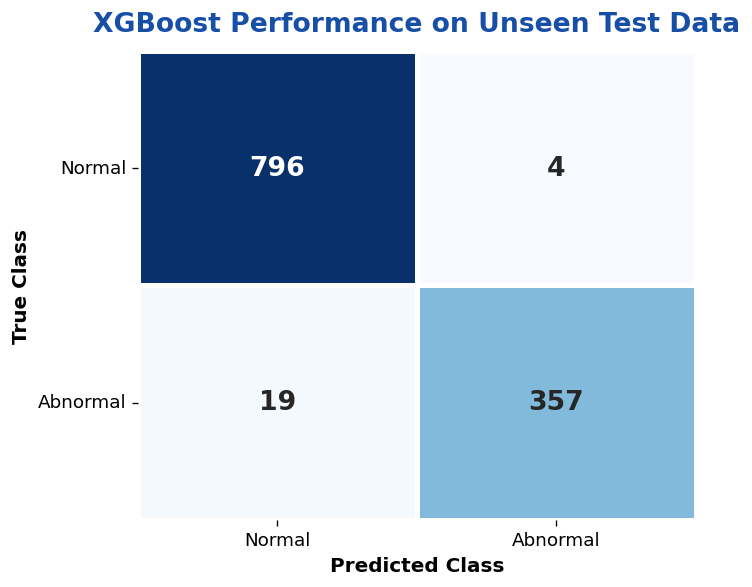

In [ ]:
# ============================================================
# XGBOOST — FINAL TEST SET CONFUSION MATRIX
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# ------------------------------------------------------------
# 1. Generate predictions on the UNSEEN TEST DATA
# ------------------------------------------------------------

y_test_pred = xgb_model.predict(X_test_processed)

# Probability of abnormal class
y_test_prob = xgb_model.predict_proba(
    X_test_processed
)[:, 1]


# ------------------------------------------------------------
# 2. Calculate confusion matrix
# ------------------------------------------------------------

cm = confusion_matrix(
    y_test_anomaly,
    y_test_pred
)

print("=" * 55)
print("XGBOOST PERFORMANCE ON UNSEEN TEST DATA")
print("=" * 55)

print("\nConfusion Matrix:")
print(cm)


# ------------------------------------------------------------
# 3. Calculate performance metrics
# ------------------------------------------------------------

accuracy = accuracy_score(
    y_test_anomaly,
    y_test_pred
)

precision = precision_score(
    y_test_anomaly,
    y_test_pred
)

sensitivity = recall_score(
    y_test_anomaly,
    y_test_pred
)

specificity = cm[0, 0] / (cm[0, 0] + cm[0, 1])

f1 = f1_score(
    y_test_anomaly,
    y_test_pred
)

roc_auc = roc_auc_score(
    y_test_anomaly,
    y_test_prob
)


# ------------------------------------------------------------
# 4. Print metrics
# ------------------------------------------------------------

print("\nPerformance Metrics")
print("-" * 55)

print(f"Accuracy     : {accuracy:.4f}")
print(f"Precision    : {precision:.4f}")
print(f"Sensitivity  : {sensitivity:.4f}")
print(f"Specificity  : {specificity:.4f}")
print(f"F1 Score     : {f1:.4f}")
print(f"ROC-AUC      : {roc_auc:.4f}")


# ------------------------------------------------------------
# 5. Compact professional confusion matrix
# ------------------------------------------------------------

plt.figure(figsize=(6, 5), dpi=120)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    linewidths=2,
    linecolor="white",
    annot_kws={
        "size": 16,
        "weight": "bold"
    },
    xticklabels=["Normal", "Abnormal"],
    yticklabels=["Normal", "Abnormal"]
)

plt.title(
    "XGBoost Performance on Unseen Test Data",
    fontsize=16,
    fontweight="bold",
    color="#174EA6",
    pad=12
)

plt.xlabel(
    "Predicted Class",
    fontsize=12,
    fontweight="bold"
)

plt.ylabel(
    "True Class",
    fontsize=12,
    fontweight="bold"
)

plt.xticks(
    fontsize=11
)

plt.yticks(
    fontsize=11,
    rotation=0
)

plt.tight_layout()

plt.show()

In [ ]:
# ============================================
# STEP 1: DISEASE-WISE PHENOTYPE DISCOVERY
# ============================================

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd
import numpy as np

# Morphological features
morph_cols = [
    "cell_diameter_um",
    "nucleus_area_pct",
    "chromatin_density",
    "cytoplasm_ratio",
    "circularity",
    "eccentricity",
    "granularity_score",
    "lobularity_score",
    "membrane_smoothness",
    "cell_area_px",
    "perimeter_px",
    "mean_r",
    "mean_g",
    "mean_b",
    "stain_intensity"
]

# Work on a clean copy
phenotype_analysis = blood_df[
    morph_cols + ["disease_category", "cell_type"]
].dropna().copy()

# Focus first on disease categories with enough samples
disease_counts = phenotype_analysis["disease_category"].value_counts()

print("Disease category sizes:")
print(disease_counts)

print("\nCategories suitable for sub-phenotype discovery:")
print(disease_counts[disease_counts >= 100])

Disease category sizes:
disease_category
Normal_WBC            2800
Normal_RBC             900
Anemia                 650
Leukemia               460
Infection              450
Normal_Platelet        300
Artefact               180
Sickle_Cell_Anemia     140
Name: count, dtype: int64

Categories suitable for sub-phenotype discovery:
disease_category
Normal_WBC            2800
Normal_RBC             900
Anemia                 650
Leukemia               460
Infection              450
Normal_Platelet        300
Artefact               180
Sickle_Cell_Anemia     140
Name: count, dtype: int64


In [ ]:
# ============================================
# STEP 2: ANEMIA SUB-PHENOTYPE DISCOVERY
# ============================================

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd
import numpy as np

# Select Anemia cells
anemia_df = phenotype_analysis[
    phenotype_analysis["disease_category"] == "Anemia"
].copy()

# Morphology matrix
X_anemia = anemia_df[morph_cols].copy()

# Standardize features
scaler = StandardScaler()
X_anemia_scaled = scaler.fit_transform(X_anemia)

# Test several numbers of phenotypes
results = []

for k in range(2, 7):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = kmeans.fit_predict(X_anemia_scaled)

    score = silhouette_score(
        X_anemia_scaled,
        labels
    )

    results.append({
        "Number_of_Phenotypes": k,
        "Silhouette_Score": score
    })

results_df = pd.DataFrame(results)

print("ANEMIA SUB-PHENOTYPE EVALUATION")
print("=" * 40)

display(results_df)

ANEMIA SUB-PHENOTYPE EVALUATION


,Number_of_Phenotypes,Silhouette_Score
0,2,0.305455
1,3,0.275639
2,4,0.268054
3,5,0.232595
4,6,0.181188


In [ ]:
# ============================================
# STEP 3: FINAL ANEMIA SUB-PHENOTYPES
# ============================================

from sklearn.cluster import KMeans
import pandas as pd
import numpy as np

# K = 2 based on highest silhouette score
kmeans_anemia = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=20
)

anemia_labels = kmeans_anemia.fit_predict(
    X_anemia_scaled
)

# Add phenotype labels
anemia_df["Anemia_Phenotype"] = anemia_labels

print("ANEMIA PHENOTYPE DISTRIBUTION")
print("=" * 40)

print(
    anemia_df["Anemia_Phenotype"]
    .value_counts()
    .sort_index()
)

# --------------------------------------------
# Morphological profile of each phenotype
# --------------------------------------------

phenotype_profile = anemia_df.groupby(
    "Anemia_Phenotype"
)[morph_cols].mean().round(3)

print("\nMORPHOLOGICAL PROFILE")
print("=" * 40)

display(phenotype_profile)

# --------------------------------------------
# Cell-type composition
# --------------------------------------------

print("\nCELL-TYPE COMPOSITION")
print("=" * 40)

celltype_profile = pd.crosstab(
    anemia_df["Anemia_Phenotype"],
    anemia_df["cell_type"],
    normalize="index"
).round(3) * 100

display(celltype_profile)

ANEMIA PHENOTYPE DISTRIBUTION
Anemia_Phenotype
0    170
1    480
Name: count, dtype: int64

MORPHOLOGICAL PROFILE


,cell_diameter_um,nucleus_area_pct,chromatin_density,cytoplasm_ratio,circularity,eccentricity,granularity_score,lobularity_score,membrane_smoothness,cell_area_px,perimeter_px,mean_r,mean_g,mean_b,stain_intensity
Anemia_Phenotype,,,,,,,,,,,,,,,
0,4.156,0.0,0.0,1.0,0.451,0.813,0.611,1.0,0.723,78.000,35.106,225.906,123.688,124.247,0.494
1,7.660,0.0,0.0,1.0,0.749,0.415,0.589,1.0,0.918,178.265,49.173,228.154,129.100,129.042,0.506



CELL-TYPE COMPOSITION


cell_type,Elliptocyte,Schistocyte,Spherocyte,Target_Cell
Anemia_Phenotype,,,,
0,0.0,100.0,0.0,0.0
1,41.7,0.0,31.2,27.1


In [ ]:
# ============================================
# STEP 4: ANEMIA PHENOTYPE STABILITY
# ============================================

from sklearn.metrics import adjusted_rand_score

# Repeat clustering with different random seeds
seeds = [42, 52, 62, 72, 82]

stability_scores = []

for seed in seeds:

    model = KMeans(
        n_clusters=2,
        random_state=seed,
        n_init=20
    )

    labels = model.fit_predict(X_anemia_scaled)

    # Compare with reference clustering
    ari = adjusted_rand_score(
        anemia_labels,
        labels
    )

    stability_scores.append({
        "Seed": seed,
        "ARI_vs_reference": ari
    })

stability_df = pd.DataFrame(stability_scores)

print("ANEMIA PHENOTYPE STABILITY")
print("=" * 40)

display(stability_df)

print(
    "\nMean ARI:",
    round(stability_df["ARI_vs_reference"].mean(), 4)
)

print(
    "Std ARI:",
    round(stability_df["ARI_vs_reference"].std(), 4)
)

ANEMIA PHENOTYPE STABILITY


,Seed,ARI_vs_reference
0,42,1.0
1,52,1.0
2,62,1.0
3,72,1.0
4,82,1.0



Mean ARI: 1.0
Std ARI: 0.0


In [ ]:
# ============================================
# STEP 5: PHENOTYPE DIFFERENCE TEST
# ============================================

from scipy.stats import mannwhitneyu
import pandas as pd

comparison_results = []

for feature in morph_cols:

    group0 = anemia_df.loc[
        anemia_df["Anemia_Phenotype"] == 0,
        feature
    ]

    group1 = anemia_df.loc[
        anemia_df["Anemia_Phenotype"] == 1,
        feature
    ]

    stat, p_value = mannwhitneyu(
        group0,
        group1,
        alternative="two-sided"
    )

    comparison_results.append({
        "Feature": feature,
        "Phenotype_0_Mean": group0.mean(),
        "Phenotype_1_Mean": group1.mean(),
        "P_value": p_value
    })

comparison_df = pd.DataFrame(comparison_results)

# Multiple-testing correction
comparison_df["Significant"] = (
    comparison_df["P_value"] < 0.05
)

comparison_df = comparison_df.sort_values(
    "P_value"
)

print("MORPHOLOGICAL DIFFERENCE BETWEEN ANEMIA PHENOTYPES")
print("=" * 55)

display(comparison_df)

MORPHOLOGICAL DIFFERENCE BETWEEN ANEMIA PHENOTYPES


,Feature,Phenotype_0_Mean,Phenotype_1_Mean,P_value,Significant
9,cell_area_px,78.000000,178.264583,1.540094e-83,True
0,cell_diameter_um,4.156176,7.659667,3.371985e-83,True
8,membrane_smoothness,0.722512,0.918004,1.212635e-81,True
10,perimeter_px,35.105882,49.172917,1.185407e-60,True
4,circularity,0.451494,0.748596,1.522429e-44,True
5,eccentricity,0.812729,0.415302,9.000110e-36,True
13,mean_b,124.247059,129.041667,4.531318e-06,True
12,mean_g,123.688235,129.100000,8.647420e-06,True
14,stain_intensity,0.493729,0.506477,1.714313e-02,True
11,mean_r,225.905882,228.154167,4.033973e-02,True


In [ ]:
# ============================================
# STEP 6A: ADD HEMATOLOGY FEATURES
# ============================================

hematology_cols = [
    "wbc_count_per_ul",
    "rbc_count_millions_per_ul",
    "hemoglobin_g_dl",
    "hematocrit_pct",
    "platelet_count_per_ul",
    "mcv_fl",
    "mchc_g_dl"
]

# Recover hematology values using the original dataframe
anemia_hema = blood_df.loc[
    anemia_df.index,
    hematology_cols
].copy()

# Attach phenotype labels
anemia_hema["Anemia_Phenotype"] = anemia_df["Anemia_Phenotype"]

# Compare hematology profiles
hema_profile = anemia_hema.groupby(
    "Anemia_Phenotype"
)[hematology_cols].agg(["mean", "std"]).round(3)

print("HEMATOLOGICAL PROFILE OF ANEMIA PHENOTYPES")
print("=" * 55)

display(hema_profile)

HEMATOLOGICAL PROFILE OF ANEMIA PHENOTYPES


wbc_count_per_ul           rbc_count_millions_per_ul         \
                             mean       std                      mean    std   
Anemia_Phenotype                                                               
0                        6604.218  2438.202                     4.894  0.770   
1                        6917.227  2472.818                     4.809  0.818   

                 hemoglobin_g_dl        hematocrit_pct         \
                            mean    std           mean    std   
Anemia_Phenotype                                                
0                         13.417  2.109         41.058  5.246   
1                         13.648  2.102         41.111  5.261   

                 platelet_count_per_ul             mcv_fl         mchc_g_dl  \
                                  mean        std    mean     std      mean   
Anemia_Phenotype                                                              
0                           246613.094  88576.774  89.419   9.822    33.724   
1                           248012.556  79138.175  89.028  10.013    33.495   

                         
                    std  
Anemia_Phenotype         
0                 1.476  
1                 1.406

In [ ]:
# ============================================
# STEP 7: WITHIN-CELL-TYPE PHENOTYPE ANALYSIS
# ============================================

# Cross-tabulation of phenotype vs predefined cell type
within_type = pd.crosstab(
    anemia_df["cell_type"],
    anemia_df["Anemia_Phenotype"]
)

print("PHENOTYPE DISTRIBUTION WITHIN EACH ANEMIA CELL TYPE")
print("=" * 55)

display(within_type)

# Percentage distribution within each cell type
within_type_pct = pd.crosstab(
    anemia_df["cell_type"],
    anemia_df["Anemia_Phenotype"],
    normalize="index"
).round(3) * 100

print("\nPERCENTAGE DISTRIBUTION")
print("=" * 55)

display(within_type_pct)

PHENOTYPE DISTRIBUTION WITHIN EACH ANEMIA CELL TYPE


Anemia_Phenotype,0,1
cell_type,,
Elliptocyte,0,200
Schistocyte,170,0
Spherocyte,0,150
Target_Cell,0,130



PERCENTAGE DISTRIBUTION


Anemia_Phenotype,0,1
cell_type,,
Elliptocyte,0.0,100.0
Schistocyte,100.0,0.0
Spherocyte,0.0,100.0
Target_Cell,0.0,100.0


In [ ]:
# ============================================
# STEP 8: ELLIPTOCYTE SUB-PHENOTYPE DISCOVERY
# ============================================

elliptocyte_df = phenotype_analysis[
    phenotype_analysis["cell_type"] == "Elliptocyte"
].copy()

X_elliptocyte = elliptocyte_df[morph_cols].copy()

scaler_elliptocyte = StandardScaler()
X_elliptocyte_scaled = scaler_elliptocyte.fit_transform(
    X_elliptocyte
)

results = []

for k in range(2, 5):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(
        X_elliptocyte_scaled
    )

    score = silhouette_score(
        X_elliptocyte_scaled,
        labels
    )

    results.append({
        "Number_of_Phenotypes": k,
        "Silhouette_Score": score
    })

elliptocyte_results = pd.DataFrame(results)

print("ELLIPTOCYTE SUB-PHENOTYPE EVALUATION")
print("=" * 50)

display(elliptocyte_results)

ELLIPTOCYTE SUB-PHENOTYPE EVALUATION


,Number_of_Phenotypes,Silhouette_Score
0,2,0.078014
1,3,0.072782
2,4,0.071108


In [ ]:
# ============================================
# STEP 9: SPHEROCYTE SUB-PHENOTYPE DISCOVERY
# ============================================

spherocyte_df = phenotype_analysis[
    phenotype_analysis["cell_type"] == "Spherocyte"
].copy()

X_spherocyte = spherocyte_df[morph_cols].copy()

scaler_spherocyte = StandardScaler()
X_spherocyte_scaled = scaler_spherocyte.fit_transform(
    X_spherocyte
)

results = []

for k in range(2, 5):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(
        X_spherocyte_scaled
    )

    score = silhouette_score(
        X_spherocyte_scaled,
        labels
    )

    results.append({
        "Number_of_Phenotypes": k,
        "Silhouette_Score": score
    })

spherocyte_results = pd.DataFrame(results)

print("SPHEROCYTE SUB-PHENOTYPE EVALUATION")
print("=" * 50)

display(spherocyte_results)

SPHEROCYTE SUB-PHENOTYPE EVALUATION


,Number_of_Phenotypes,Silhouette_Score
0,2,0.080683
1,3,0.069917
2,4,0.071083


In [ ]:
# Check existing trained model and preprocessing objects

print("XGBoost model:", "xgb_model" in globals())
print("Preprocessor:", "preprocessor" in globals())
print("Training data:", "X_train" in globals())

XGBoost model: True
Preprocessor: True
Training data: True


In [ ]:
# Check the exact input features expected by the model

print("Number of features:", len(X_train.columns))
print("\nFeatures:")
for i, col in enumerate(X_train.columns, 1):
    print(i, ":", col)

Number of features: 29

Features:
1 : cell_diameter_um
2 : nucleus_area_pct
3 : chromatin_density
4 : cytoplasm_ratio
5 : circularity
6 : eccentricity
7 : granularity_score
8 : lobularity_score
9 : membrane_smoothness
10 : cell_area_px
11 : perimeter_px
12 : mean_r
13 : mean_g
14 : mean_b
15 : stain_intensity
16 : patient_age_group
17 : patient_sex
18 : wbc_count_per_ul
19 : rbc_count_millions_per_ul
20 : hemoglobin_g_dl
21 : hematocrit_pct
22 : platelet_count_per_ul
23 : mcv_fl
24 : mchc_g_dl
25 : dataset_source
26 : staining_protocol
27 : microscope_model
28 : magnification_x
29 : image_resolution_px


In [ ]:
# Create one sample input from the existing test data
cdss_sample = X_train.iloc[[0]].copy()

print("CDSS sample shape:", cdss_sample.shape)
display(cdss_sample)

CDSS sample shape: (1, 29)


,cell_diameter_um,nucleus_area_pct,chromatin_density,cytoplasm_ratio,circularity,eccentricity,granularity_score,lobularity_score,membrane_smoothness,cell_area_px,...,hemoglobin_g_dl,hematocrit_pct,platelet_count_per_ul,mcv_fl,mchc_g_dl,dataset_source,staining_protocol,microscope_model,magnification_x,image_resolution_px
773,7.72,81.8,0.939,0.199,0.946,0.146,0.91,1.0,0.925,244,...,14.3,43.2,76942,83.8,33.3,PBC_Dataset,Giemsa,Zeiss_Axio,60,360


In [ ]:
# Test preprocessing for the CDSS sample

cdss_transformed = preprocessor.transform(cdss_sample)

print("Raw input shape:", cdss_sample.shape)
print("Transformed input shape:", cdss_transformed.shape)

Raw input shape: (1, 29)
Transformed input shape: (1, 38)


In [ ]:
# CDSS prediction

cdss_probability = xgb_model.predict_proba(cdss_transformed)[0, 1]
cdss_prediction = xgb_model.predict(cdss_transformed)[0]

print("Predicted class:", cdss_prediction)
print("Abnormality probability:", round(cdss_probability, 4))

Predicted class: 0
Abnormality probability: 0.0003


In [ ]:
# SHAP explanation for the CDSS prediction

import shap
import numpy as np
import pandas as pd

# Create SHAP explainer
cdss_explainer = shap.TreeExplainer(xgb_model)

# Calculate SHAP values
cdss_shap = cdss_explainer.shap_values(cdss_transformed)

# Get transformed feature names
cdss_feature_names = preprocessor.get_feature_names_out()

# Handle binary-class SHAP output
if isinstance(cdss_shap, list):
    cdss_shap_values = cdss_shap[1][0]
else:
    cdss_shap_values = cdss_shap[0]

# Create explanation table
cdss_explanation = pd.DataFrame({
    "Feature": cdss_feature_names,
    "SHAP_Value": cdss_shap_values
})

cdss_explanation["Absolute_SHAP"] = cdss_explanation["SHAP_Value"].abs()
cdss_explanation = cdss_explanation.sort_values(
    "Absolute_SHAP", ascending=False
)

print("Top features influencing this prediction:")
display(cdss_explanation.head(10))

Top features influencing this prediction:


,Feature,SHAP_Value,Absolute_SHAP
2,num__chromatin_density,-1.748322,1.748322
9,num__cell_area_px,-1.510294,1.510294
0,num__cell_diameter_um,-1.443210,1.443210
6,num__granularity_score,0.823682,0.823682
4,num__circularity,-0.774136,0.774136
10,num__perimeter_px,-0.759301,0.759301
5,num__eccentricity,-0.622797,0.622797
14,num__stain_intensity,-0.368167,0.368167
7,num__lobularity_score,-0.362404,0.362404
12,num__mean_g,-0.323250,0.323250


In [ ]:
# Final CDSS output

operating_threshold = 0.7891

if cdss_probability >= operating_threshold:
    status = "ABNORMAL"
    recommendation = "Expert review recommended"
else:
    status = "NORMAL"
    recommendation = "No immediate review flag based on the model"

print("=" * 50)
print("        BLOOD CELL CDSS RESULT")
print("=" * 50)
print(f"Phenotype Status       : {status}")
print(f"Abnormality Probability: {cdss_probability:.4f}")
print(f"Operating Threshold    : {operating_threshold:.4f}")
print(f"Recommendation         : {recommendation}")
print("=" * 50)

print("\nTop 5 Model Explanations:")
for _, row in cdss_explanation.head(5).iterrows():
    direction = "increases" if row["SHAP_Value"] > 0 else "decreases"
    print(
        f"- {row['Feature']} "
        f"({direction} abnormality score, SHAP={row['SHAP_Value']:.4f})"
    )

        BLOOD CELL CDSS RESULT
Phenotype Status       : NORMAL
Abnormality Probability: 0.0003
Operating Threshold    : 0.7891
Recommendation         : No immediate review flag based on the model

Top 5 Model Explanations:
- num__chromatin_density (decreases abnormality score, SHAP=-1.7483)
- num__cell_area_px (decreases abnormality score, SHAP=-1.5103)
- num__cell_diameter_um (decreases abnormality score, SHAP=-1.4432)
- num__granularity_score (increases abnormality score, SHAP=0.8237)
- num__circularity (decreases abnormality score, SHAP=-0.7741)


In [ ]:
# Select a known abnormal sample from the test set

abnormal_idx = y_test[y_test == 1].index[0]

cdss_abnormal_sample = X_test.loc[[abnormal_idx]].copy()

print("Selected abnormal sample:")
display(cdss_abnormal_sample)

print("\nTrue label:", y_test.loc[abnormal_idx])

Selected abnormal sample:


,cell_diameter_um,nucleus_area_pct,chromatin_density,cytoplasm_ratio,circularity,eccentricity,granularity_score,lobularity_score,membrane_smoothness,cell_area_px,...,hemoglobin_g_dl,hematocrit_pct,platelet_count_per_ul,mcv_fl,mchc_g_dl,dataset_source,staining_protocol,microscope_model,magnification_x,image_resolution_px
944,8.69,0.0,0.0,1.0,0.835,0.257,0.95,1.0,0.907,226,...,16.6,39.8,329598,85.7,31.6,PBC_Dataset,Giemsa,Zeiss_Axio,60,256



True label: 1


In [ ]:
# Predict the known abnormal sample

cdss_abnormal_transformed = preprocessor.transform(cdss_abnormal_sample)

abnormal_probability = xgb_model.predict_proba(
    cdss_abnormal_transformed
)[0, 1]

abnormal_prediction = xgb_model.predict(
    cdss_abnormal_transformed
)[0]

print("True label              :", y_test.loc[abnormal_idx])
print("Predicted class         :", abnormal_prediction)
print("Abnormality probability :", round(abnormal_probability, 4))

True label              : 1
Predicted class         : 1
Abnormality probability : 0.9886


In [ ]:
# SHAP explanation for the abnormal CDSS sample

abnormal_shap = cdss_explainer.shap_values(cdss_abnormal_transformed)

if isinstance(abnormal_shap, list):
    abnormal_shap_values = abnormal_shap[1][0]
else:
    abnormal_shap_values = abnormal_shap[0]

abnormal_explanation = pd.DataFrame({
    "Feature": cdss_feature_names,
    "SHAP_Value": abnormal_shap_values
})

abnormal_explanation["Absolute_SHAP"] = (
    abnormal_explanation["SHAP_Value"].abs()
)

abnormal_explanation = abnormal_explanation.sort_values(
    "Absolute_SHAP", ascending=False
)

print("Top features influencing the abnormal prediction:")
display(abnormal_explanation.head(10))

Top features influencing the abnormal prediction:


,Feature,SHAP_Value,Absolute_SHAP
6,num__granularity_score,2.571112,2.571112
0,num__cell_diameter_um,1.274729,1.274729
2,num__chromatin_density,0.712290,0.712290
1,num__nucleus_area_pct,0.511370,0.511370
9,num__cell_area_px,0.496622,0.496622
19,num__platelet_count_per_ul,-0.490741,0.490741
7,num__lobularity_score,-0.308881,0.308881
17,num__hemoglobin_g_dl,0.264317,0.264317
4,num__circularity,-0.255096,0.255096
37,cat__microscope_model_Zeiss_Axio,0.247274,0.247274


In [ ]:
!pip -q install gradio

In [ ]:
# Check categorical values used by the trained model

categorical_cols = [
    "patient_age_group",
    "patient_sex",
    "dataset_source",
    "staining_protocol",
    "microscope_model"
]

for col in categorical_cols:
    print(f"\n{col}:")
    print(sorted(X_train[col].dropna().unique().tolist()))


patient_age_group:
['Adult', 'Elderly', 'Pediatric']

patient_sex:
['F', 'M']

dataset_source:
['CytoData', 'PBC_Dataset', 'Raabin_WBC']

staining_protocol:
['Giemsa', 'May_Grunwald_Giemsa', 'Wright']

microscope_model:
['Leica_DM2000', 'Olympus_BX51', 'Zeiss_Axio']


In [ ]:
import gradio as gr
import pandas as pd

def cdss_predict(
    cell_diameter_um,
    nucleus_area_pct,
    chromatin_density,
    cytoplasm_ratio,
    circularity,
    eccentricity,
    granularity_score,
    lobularity_score,
    membrane_smoothness,
    cell_area_px,
    perimeter_px,
    mean_r,
    mean_g,
    mean_b,
    stain_intensity,
    patient_age_group,
    patient_sex,
    wbc_count_per_ul,
    rbc_count_millions_per_ul,
    hemoglobin_g_dl,
    hematocrit_pct,
    platelet_count_per_ul,
    mcv_fl,
    mchc_g_dl,
    dataset_source,
    staining_protocol,
    microscope_model,
    magnification_x,
    image_resolution_px
):

    input_data = pd.DataFrame([{
        "cell_diameter_um": cell_diameter_um,
        "nucleus_area_pct": nucleus_area_pct,
        "chromatin_density": chromatin_density,
        "cytoplasm_ratio": cytoplasm_ratio,
        "circularity": circularity,
        "eccentricity": eccentricity,
        "granularity_score": granularity_score,
        "lobularity_score": lobularity_score,
        "membrane_smoothness": membrane_smoothness,
        "cell_area_px": cell_area_px,
        "perimeter_px": perimeter_px,
        "mean_r": mean_r,
        "mean_g": mean_g,
        "mean_b": mean_b,
        "stain_intensity": stain_intensity,
        "patient_age_group": patient_age_group,
        "patient_sex": patient_sex,
        "wbc_count_per_ul": wbc_count_per_ul,
        "rbc_count_millions_per_ul": rbc_count_millions_per_ul,
        "hemoglobin_g_dl": hemoglobin_g_dl,
        "hematocrit_pct": hematocrit_pct,
        "platelet_count_per_ul": platelet_count_per_ul,
        "mcv_fl": mcv_fl,
        "mchc_g_dl": mchc_g_dl,
        "dataset_source": dataset_source,
        "staining_protocol": staining_protocol,
        "microscope_model": microscope_model,
        "magnification_x": magnification_x,
        "image_resolution_px": image_resolution_px
    }])

    # Preprocess
    transformed = preprocessor.transform(input_data)

    # Prediction
    probability = xgb_model.predict_proba(transformed)[0, 1]

    if probability >= 0.7891:
        status = "🔴 ABNORMAL"
        recommendation = "Expert review recommended"
    else:
        status = "🟢 NORMAL"
        recommendation = "No immediate review flag based on the model"

    # SHAP explanation
    shap_values = cdss_explainer.shap_values(transformed)

    if isinstance(shap_values, list):
        shap_values = shap_values[1][0]
    else:
        shap_values = shap_values[0]

    explanation = pd.DataFrame({
        "Feature": cdss_feature_names,
        "SHAP_Value": shap_values
    })

    explanation["Absolute_SHAP"] = explanation["SHAP_Value"].abs()

    explanation = explanation.sort_values(
        "Absolute_SHAP",
        ascending=False
    ).head(5)

    explanation_text = ""

    for _, row in explanation.iterrows():

        direction = (
            "increases abnormality"
            if row["SHAP_Value"] > 0
            else "decreases abnormality"
        )

        explanation_text += (
            f"• {row['Feature']} → {direction} "
            f"(SHAP: {row['SHAP_Value']:.4f})\n"
        )

    return (
        status,
        f"{probability:.4f}",
        recommendation,
        explanation_text
    )

# Define the 29 inputs required by the function
inputs = [
    gr.Slider(minimum=1.0, maximum=22.0, value=10.17, label="Cell Diameter (um)"),
    gr.Slider(minimum=0.0, maximum=100.0, value=43.53, label="Nucleus Area (%)"),
    gr.Slider(minimum=0.0, maximum=1.0, value=0.39, label="Chromatin Density"),
    gr.Slider(minimum=0.0, maximum=1.0, value=0.56, label="Cytoplasm Ratio"),
    gr.Slider(minimum=0.0, maximum=1.0, value=0.76, label="Circularity"),
    gr.Slider(minimum=0.0, maximum=1.0, value=0.36, label="Eccentricity"),
    gr.Slider(minimum=0.0, maximum=6.0, value=1.88, label="Granularity Score"),
    gr.Slider(minimum=1.0, maximum=8.0, value=1.76, label="Lobularity Score"),
    gr.Slider(minimum=0.0, maximum=1.0, value=0.84, label="Membrane Smoothness"),
    gr.Number(value=336, label="Cell Area (px)"),
    gr.Number(value=64, label="Perimeter (px)"),
    gr.Slider(minimum=0, maximum=255, value=212, label="Mean R"),
    gr.Slider(minimum=0, maximum=255, value=146, label="Mean G"),
    gr.Slider(minimum=0, maximum=255, value=168, label="Mean B"),
    gr.Slider(minimum=0.0, maximum=1.0, value=0.61, label="Stain Intensity"),
    gr.Dropdown(choices=["Adult", "Elderly", "Pediatric"], value="Adult", label="Patient Age Group"),
    gr.Dropdown(choices=["F", "M"], value="F", label="Patient Sex"),
    gr.Number(value=7043, label="WBC Count (per uL)"),
    gr.Number(value=4.79, label="RBC Count (millions/uL)"),
    gr.Number(value=13.54, label="Hemoglobin (g/dL)"),
    gr.Number(value=41.29, label="Hematocrit (%)"),
    gr.Number(value=249792, label="Platelet Count (per uL)"),
    gr.Number(value=88.94, label="MCV (fL)"),
    gr.Number(value=33.49, label="MCHC (g/dL)"),
    gr.Dropdown(choices=["CytoData", "PBC_Dataset", "Raabin_WBC"], value="PBC_Dataset", label="Dataset Source"),
    gr.Dropdown(choices=["Giemsa", "May_Grunwald_Giemsa", "Wright"], value="Giemsa", label="Staining Protocol"),
    gr.Dropdown(choices=["Leica_DM2000", "Olympus_BX51", "Zeiss_Axio"], value="Olympus_BX51", label="Microscope Model"),
    gr.Dropdown(choices=[40, 60, 100], value=100, label="Magnification (x)"),
    gr.Dropdown(choices=[224, 256, 360, 512], value=256, label="Image Resolution (px)")
]

# Updated outputs
outputs = [
    gr.Textbox(label="Phenotype Status"),
    gr.Textbox(label="Abnormality Probability"),
    gr.Textbox(label="Recommendation"),
    gr.Textbox(label="Top SHAP Explanations", lines=6)
]

# Rebuild interface
demo = gr.Interface(
    fn=cdss_predict,
    inputs=inputs,
    outputs=outputs,
    title="Blood Cell Explainable AI CDSS",
    description=(
        "Decision-support prototype for blood-cell abnormality "
        "assessment using morphology and hematology features."
    )
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://f1d312c9de7ef577f7.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
